# Analysis of full-texts

This Notebook aims to analyze the full-text corpus, obtained from Grobid-parsed XML files gathered via OpenAlex.

The main goal is answering the RQ4, *Do abstracts diverge from the other sections of research papers by the degree of anthropomorphism?*

The analysis shall be conducted on different levels to also detect the possible differences between domains and the change through years.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pingouin as pg
import re
from scipy import stats
from scipy.stats import linregress
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

Note that the file `new-method-fulltexts-cleaned.csv` contains duplicated rows for multi-token entities due to different token metadata. However, the values of the id columns and the score are identical. Those rows should be removed for calculating the average scores.

In [2]:
CLEANED_FULLTEXTS = "../data/new-method-fulltexts-cleaned.csv"
CLEANED_FULLTEXTS_UPDATED = "../data/new-method-fulltexts-cleaned-updated.csv"

In [3]:
cat_cols = "paper_id domain source_file section_type entity_lower role pos tag dep ent_type ent_iob entity_type".split()
dtypes = {col: "category" for col in cat_cols}

In [4]:
df = pd.read_csv(CLEANED_FULLTEXTS_UPDATED, dtype=dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1011876 entries, 0 to 1011875
Data columns (total 34 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1011876 non-null  category
 1   year                     1011876 non-null  int64   
 2   domain                   1011876 non-null  category
 3   source_file              1011876 non-null  category
 4   global_i                 1011876 non-null  int64   
 5   sentence_index           1011876 non-null  int64   
 6   section                  991385 non-null   object  
 7   section_type             1011876 non-null  category
 8   paragraph_index          1011876 non-null  int64   
 9   sent_id                  1011876 non-null  int64   
 10  match_id                 1011876 non-null  int64   
 11  sentence                 1011876 non-null  object  
 12  masked_sentence_minimal  1011876 non-null  object  
 13  masked_sentence_chunk    10

In [5]:
df["humanlike"] = df["score"] > 0

In [6]:
df["section_canonical"] = df["section_canonical"].replace({"approach": "methods"})

In [7]:
df["section_canonical"].unique()

array(['abstract', 'introduction', 'related_work', 'discussion',
       '[MISSING]', 'ethics', 'methods', 'data', 'acknowledgments',
       'conclusion', 'results', 'experiments', 'funding', 'statement',
       'availability', 'contributions', 'appendix', 'references'],
      dtype=object)

In [8]:
df["entity_type_updated"] = df["entity_type"]
df["entity_type_updated"] = df["entity_type_updated"].cat.add_categories("propn_llm")
df.loc[df["entity_lower"].isin(("chatgpt", "claude", "gemini")), "entity_type_updated"] = "propn_llm"

In [9]:
pd.DataFrame({"count": df.entity_type_updated.value_counts(), "proportion": df.entity_type_updated.value_counts(normalize=True)})

,count,proportion
entity_type_updated,,
artifact,610878,0.603708
human,306361,0.302765
lm,85558,0.084554
propn_llm,9079,0.008972


In [10]:
pd.DataFrame({"count": df.entity_type.value_counts(), "proportion": df.entity_type.value_counts(normalize=True)})

,count,proportion
entity_type,,
artifact,610878,0.603708
human,306361,0.302765
lm,94637,0.093526


In [9]:
df.loc[(df["section_type"] == "abstract") & (df["section"].isna()), "section"] = "abstract"

In [6]:
id_cols = "paper_id source_file global_i sentence_index section section_type paragraph_index sent_id match_id score".split()
df.duplicated(id_cols, keep=False).sum()

61339

In [7]:
# Get rid of the multi-token instances, keeping the last part, e.g. "model" from "large language model"
df_dedup = df.drop_duplicates(id_cols, keep="last").copy()

In [8]:
df_dedup

,paper_id,year,domain,source_file,global_i,sentence_index,section,section_type,paragraph_index,sent_id,...,pos,tag,dep,ent_type,ent_iob,entity_type,num_tokens,entity_type_updated,section_canonical,humanlike
1,W169306565,2023,Social Sciences,fulltext-sentences-extended_001.spacy,1,0,abstract,abstract,0,0,...,PROPN,NNP,nsubj,ORG,I,artifact,25,artifact,abstract,True
2,W169306565,2023,Social Sciences,fulltext-sentences-extended_001.spacy,1,0,abstract,abstract,0,0,...,PROPN,NNP,appos,ORG,I,artifact,25,artifact,abstract,True
3,W169306565,2023,Social Sciences,fulltext-sentences-extended_001.spacy,2,1,abstract,abstract,0,0,...,PROPN,NNP,pobj,ORG,B,artifact,21,artifact,abstract,False
4,W169306565,2023,Social Sciences,fulltext-sentences-extended_001.spacy,3,2,abstract,abstract,0,0,...,PROPN,NNP,pobj,ORG,B,artifact,25,artifact,abstract,False
5,W169306565,2023,Social Sciences,fulltext-sentences-extended_001.spacy,4,3,abstract,abstract,0,0,...,PROPN,NNP,pobj,ORG,B,artifact,19,artifact,abstract,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1011871,W7140044697,2026,Social Sciences,fulltext-sentences-extended_010.spacy,114897,0,Conclusion,body,3,0,...,PROPN,NNP,npadvmod,NaN,O,artifact,30,artifact,conclusion,True
1011872,W7140044697,2026,Social Sciences,fulltext-sentences-extended_011.spacy,2,0,Conclusion,body,4,0,...,NOUN,NN,nsubj,NaN,O,artifact,27,artifact,conclusion,False
1011873,W7140044697,2026,Social Sciences,fulltext-sentences-extended_011.spacy,2,0,Conclusion,body,4,0,...,NOUN,NN,conj,NaN,O,artifact,27,artifact,conclusion,False
1011874,W7140044697,2026,Social Sciences,fulltext-sentences-extended_011.spacy,4,2,Conclusion,body,4,0,...,NOUN,NN,poss,NaN,O,artifact,47,artifact,conclusion,False


In [43]:
skip_singular = set(("approaches", "us", "companies"))
def map_to_singular(term):
    if term.endswith("s") and term not in skip_singular:
        return term[:-1]
    return term

df_dedup["entity_stripped"] = df_dedup["entity_lower"].apply(map_to_singular)
df_dedup["entity_stripped"] = df_dedup["entity_stripped"].replace({"approaches": "approach"})

In [14]:
df_dedup.in_noun_chunk.value_counts()

in_noun_chunk
True     959900
False     19185
Name: count, dtype: int64

In [15]:
# Inspect how big a proportion of all entities are the root of the noun chunk they are part of,
# or not in a noun chunk 
num_not_in_chunk = (df_dedup["in_noun_chunk"] == False).sum()
num_is_root = len(df_dedup[df_dedup["token_text"] == df_dedup["chunk_root_text"]])
print(f"{num_not_in_chunk} not in chunk + {num_is_root} is root")
print(f"Proportion of deduplicated data: {(num_not_in_chunk + num_is_root) / len(df_dedup):.2%}")

19185 not in chunk + 765059 is root
Proportion of deduplicated data: 80.10%


In [15]:
# TODO: Compare the results obtained with this 80% vs 100%

/tmp/kapyahos/1613792/ipykernel_530649/2259506906.py:1: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  g = sns.displot(df_dedup, kind="kde", x="score", col="entity_lower", col_wrap=6, common_norm=False, height=2, hue="domain", hue_order=domain_order)


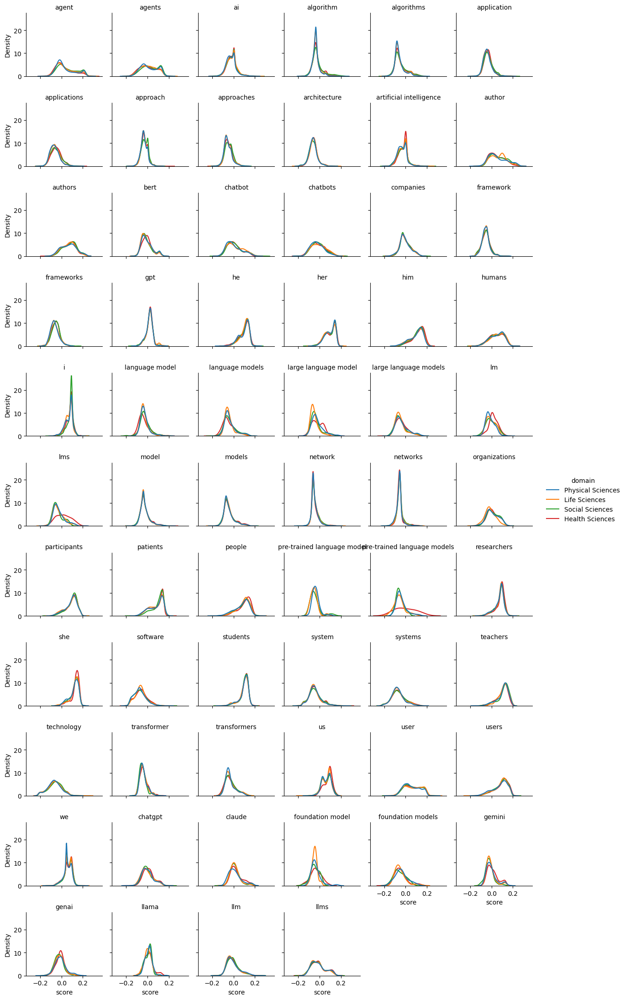

In [34]:
g = sns.displot(df_dedup, kind="kde", x="score", col="entity_lower", col_wrap=6, common_norm=False, height=2, hue="domain", hue_order=domain_order)
g.set_titles("{col_name}")

## Mapping (some of) the sections to main sections

(Note that it might be a better idea to go back to the XML to CSV transformation part, as it is likely that by following a title chain, the main title could be preserved, as the explored method can only map about 50% of the titles into the fine-grained categories. UPDATE: This was tested, but didn't work as smoothly as expected, and is out of scope for the purpose of the thesis.)

In [16]:
# Get each section from the body of each paper
id_cols_section = "paper_id section section_type".split()
unique_sections = df_dedup[df_dedup["section_type"] == "body"].drop_duplicates(id_cols_section)[["paper_id", "section", "section_type"]]

In [17]:
unique_sections.section_type.value_counts()

section_type
body        71994
abstract        0
Name: count, dtype: int64

In [18]:
unique_sections.section.nunique()

49428

In [19]:
unique_sections.section.str.lower().value_counts().head(20)

section
introduction              3251
discussion                1514
conclusion                1497
conclusions                880
results                    823
acknowledgments            502
i. introduction            434
related work               423
acknowledgements           402
methods                    342
limitations                255
methodology                225
background                 215
statistical analysis       205
materials and methods      173
results and discussion     160
author contributions       158
experiments                149
•                          139
data availability          128
Name: count, dtype: int64

In [20]:
def normalize_title(t):
    t = t.lower().strip()
    t = re.sub(r'^\s*\d+(\.\d+)*\.?\s*', '', t)      # strip leading numbering: "3.2 Related Work" -> "related work"
    t = re.sub(r'^[ivxlc]+\.\s*', '', t)             # strip roman numerals
    t = re.sub(r'[^\w\s&-]', '', t)                  # strip punctuation
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df_dedup["section_normalized"] = df_dedup["section"].dropna().map(normalize_title)
unique_sections['section_normalized'] = unique_sections['section'].dropna().map(normalize_title)
unique_sections.section_normalized.nunique()

46212

In [21]:
unique_sections.section_normalized.value_counts().head(10)

section_normalized
introduction        3736
conclusion          1798
discussion          1603
conclusions          974
                     942
results              884
acknowledgments      575
related work         499
acknowledgements     415
methods              367
Name: count, dtype: int64

In [22]:
counts = pd.DataFrame(unique_sections['section_normalized'].value_counts())
counts = counts.reset_index("section_normalized")

In [23]:
counts["cumsum"] = counts["count"].cumsum() / counts["count"].sum()   # cumulative coverage
counts

,section_normalized,count,cumsum
0,introduction,3736,0.052849
1,conclusion,1798,0.078283
2,discussion,1603,0.100959
3,conclusions,974,0.114737
4,,942,0.128063
...,...,...,...
46207,monitoring and minimizing bias,1,0.999943
46208,ai on a leash,1,0.999958
46209,ensuring user inclusivity,1,0.999972
46210,convolutional neural network architecture and ...,1,0.999986


In [24]:
# Only ~30% covered with top-300 section titles
counts.iloc[300]

section_normalized    conclusions and outlook
count                                       8
cumsum                               0.291023
Name: 300, dtype: object

In [25]:
# 39143 section titles to reach 90%
(counts["cumsum"] <= 0.9).sum()

39142

In [26]:
# On the other hand, only 2510 appear more than once
(counts["count"] > 1).sum()

2511

The following regular expression was built iteratively by manually inspecting the most common titles.

In [27]:
CANONICAL_RULES = [
    # (canonical_label, regex pattern, applied in order — first match wins)
    ('introduction',   r'\bintroduction\b|\bbackground and motivation\b|^background$|\btheoretical background\b|\boverview\b|\bobjective(s)?\b|\bpreliminaries\b|\bproblem (formulation|statement|definition)\b|\bmotivation\b|\bresearch questions\b'),
    ('related_work',   r'\brelated work(s)?\b|\bliterature (review|survey)\b|\bprior work\b|\bprevious work\b'),
    ('approach',       r'\bmethod(ology|s)?\b|\bapproach\b|\bmodel(s)?\b|\bsystem\b|\bframework\b|\bproposed\b|\bimplementation\b|\b(research|study) design\b|\bprocedure(s)?\b|\barchitecture\b|\btraining\b|\bmetrics\b|\bsearch strategy\b|\bsoftware\b|\bapplication\b'),
    ('data',           r'^data$|\bdata( )?set(s)?\b|\bdata (collection|preprocessing|augmentation|extraction|preparation|acquisition)\b|\btraining data\b|\b(data )?pre(-)?processing\b'),
    ('experiments',    r'\bexperiment(s|al)?( setup| design)?\b|\bevaluation\b|\bsetup\b|\bparticipants\b|\bcase stud(y|ies)\b|\bbaselines\b|\bstudy population\b|\bpatients\b|\bsimulations\b'),
    ('results',        r'\bresult(s)?\b|\bfindings\b|\bperformance\b'),
    ('discussion',     r'\bdiscussion(s)?\b|\banalys(i|e)s\b|\bablation\b|\blimitations\b|\bchallenges\b|\b(theoretical )?implications\b'),
    ('conclusion',     r'\bconclusion(s)?\b|\bconcluding remarks\b|\bfuture (work|directions|research)\b|\bsummary\b|\brecommendations\b'),
    ('ethics',         r'\bethics\b|\bethic(s|al) ((statement|consideration|approval)(s)?)\b'),
    ('statement',      r'\bconflict(s)? of interest(s)?\b|\bcompeting interest(s)?\b|\bdeclaration(s)?\b|\bdisclosure( statement)?\b|\bconsent for publication\b'),
    ('availability',   r'\b(data|code) availability( statement)?\b|\bavailability of (data|code)\b'),
    ('funding',        r'^funding$'),
    ('abstract',       r'^abstract$'),
    ('acknowledgments',r'\backnowledg'),
    ('contributions',  r'\b(author(s)? )?contribution(s)?\b'),
    ('appendix',       r'\bappendix\b|\bsupplementary\b|\badditional information\b'),
    ('references',     r'^references$|^bibliography$'),
    ('[MISSING]',      r'^$')
]

def map_to_canonical(title_norm):
    for label, pattern in CANONICAL_RULES:
        if re.search(pattern, title_norm):
            return label
    return None  # unmapped -> handle in step 3/4

counts['section_canonical'] = counts['section_normalized'].dropna().map(map_to_canonical)

In [28]:
counts.section_canonical.value_counts()

section_canonical
approach           6395
discussion         2189
experiments        1535
results            1142
data                808
introduction        695
conclusion          422
ethics              178
related_work        169
appendix            118
contributions       108
statement            80
availability         24
acknowledgments      19
[MISSING]             1
funding               1
abstract              1
references            1
Name: count, dtype: int64

In [29]:
counts.section_canonical.isna().sum()

32326

In [30]:
counts

,section_normalized,count,cumsum,section_canonical
0,introduction,3736,0.052849,introduction
1,conclusion,1798,0.078283,conclusion
2,discussion,1603,0.100959,discussion
3,conclusions,974,0.114737,conclusion
4,,942,0.128063,[MISSING]
...,...,...,...,...
46207,monitoring and minimizing bias,1,0.999943,None
46208,ai on a leash,1,0.999958,None
46209,ensuring user inclusivity,1,0.999972,None
46210,convolutional neural network architecture and ...,1,0.999986,approach


In [31]:
canon_dict = counts[["section_normalized", "section_canonical"]].set_index("section_normalized")["section_canonical"].to_dict()

In [32]:
df_dedup["section_canonical"] = df_dedup["section_normalized"].map(canon_dict)

In [33]:
# Coverage at this point per canonical section
counts.groupby("section_canonical", observed=True)["count"].sum() / counts["count"].sum()

section_canonical
[MISSING]          0.013325
abstract           0.000184
acknowledgments    0.016466
appendix           0.003522
approach           0.124866
availability       0.004654
conclusion         0.052792
contributions      0.005588
data               0.020455
discussion         0.076048
ethics             0.004824
experiments        0.036892
funding            0.000905
introduction       0.071592
references         0.000071
related_work       0.013311
results            0.036808
statement          0.007483
Name: count, dtype: float64

In [34]:
# Coverage of all section names
counts.groupby("section_canonical", observed=True)["count"].sum().sum() / counts["count"].sum()

0.489786680246704

In [35]:
counts.loc[counts["section_canonical"].isna(), "count"].sum() / counts["count"].sum()

0.510213319753296

In [36]:
counts[counts.section_canonical.isna()].sort_values('count', ascending=False).head(50)

,section_normalized,count,cumsum,section_canonical
69,measures,37,0.241597,None
73,artificial intelligence,35,0.243606,None
91,deep learning,27,0.251358,None
94,machine learning,26,0.252476,None
108,preprints,22,0.257172,None
134,transparency,17,0.264174,None
136,sample,17,0.264655,None
137,materials,17,0.264896,None
141,feature extraction,16,0.265815,None
148,data sources,16,0.267399,None


In [37]:
counts[counts.section_canonical.isna()].sort_values('count', ascending=False).head(50)["count"].sum()

721

In [38]:
counts["cumsum_canonical"] = counts[~counts["section_canonical"].isna()]["count"].cumsum() / counts["count"].sum()

In [39]:
df_dedup.section_canonical.value_counts()

section_canonical
introduction       119931
approach           115806
discussion          88339
conclusion          46531
abstract            45892
results             37750
experiments         29235
related_work        19008
[MISSING]           13159
data                11117
ethics               3769
acknowledgments      2628
contributions        2346
appendix             1354
statement            1071
availability          582
funding               109
references             14
Name: count, dtype: int64

In [40]:
df_dedup[df_dedup["section_canonical"].isna()].groupby("domain", observed=True).size()

domain
Health Sciences       69773
Life Sciences         74769
Physical Sciences    162818
Social Sciences      133084
dtype: int64

In [41]:
df_dedup["section_canonical"] = df_dedup["section_canonical"].fillna("[MISSING]")

In [42]:
df_dedup.loc[(df_dedup["section_canonical"] == "abstract"), "section_type"] = "abstract"
df_dedup.loc[(df_dedup["section_type"] == "abstract"), "section_canonical"] = "abstract"

In [43]:
df_dedup.section_canonical.value_counts()

section_canonical
[MISSING]          452257
introduction       119309
approach           115000
discussion          88326
abstract            49842
conclusion          46011
results             37108
experiments         29235
related_work        19008
data                11117
ethics               3769
acknowledgments      2628
contributions        2346
appendix             1354
statement            1070
availability          582
funding               109
references             14
Name: count, dtype: int64

In [155]:
def print_section_dist():
    for et in df_dedup.entity_type_updated.unique():
        print(et.upper())
        subset = df_dedup[df_dedup["entity_type_updated"] == et]
        display(subset.groupby("section_canonical", observed=True)["score"].agg(["mean", "size"]).sort_values("mean"))
        print("="*30)
        print()

print_section_dist()

ARTIFACT


,mean,size
section_canonical,,
funding,-0.083357,69
acknowledgments,-0.065234,658
availability,-0.042393,221
related_work,-0.041178,12580
references,-0.040226,11
introduction,-0.038395,77973
conclusion,-0.037588,29566
abstract,-0.035724,32506
approach,-0.034297,71808



HUMAN


,mean,size
section_canonical,,
availability,0.017333,345
references,0.037207,2
data,0.058412,5824
funding,0.058927,40
approach,0.061353,32901
appendix,0.063871,612
experiments,0.064353,12684
[MISSING],0.066804,147864
related_work,0.067806,3704



LM


,mean,size
section_canonical,,
conclusion,-0.023245,3096
acknowledgments,-0.022059,24
abstract,-0.021467,4317
related_work,-0.021412,2537
introduction,-0.020857,9857
availability,-0.019443,14
contributions,-0.014996,139
approach,-0.012671,9481
appendix,-0.009390,67



PROPN_LLM


,mean,size
section_canonical,,
availability,-0.018108,2
acknowledgments,-0.008528,16
statement,-0.007807,4
related_work,-0.006781,187
conclusion,-0.003039,370
introduction,-0.002358,976
ethics,0.001162,28
abstract,0.001483,555
approach,0.005753,810


IMRaD: Introduction, Methods, Results, Discussion

In [224]:
sections_of_interest = ("introduction", "approach", "discussion", "abstract", "conclusion", "results", "experiments", "related_work", "data", "ethics", "[MISSING]")

In [160]:
filtered = df_dedup[df_dedup["section_canonical"].isin(sections_of_interest)]

In [161]:
filtered.groupby("paper_id",observed=True)["section_canonical"].nunique().describe()

count    4845.000000
mean        5.021259
std         1.783770
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: section_canonical, dtype: float64

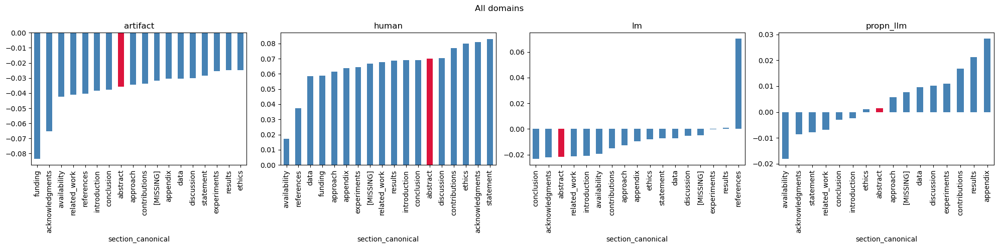

In [47]:
def plot_section_scores(subset, title, highlight="abstract", 
                        highlight_color="crimson", other_color="steelblue"):
    fig, axes = plt.subplots(1, subset.entity_type_updated.nunique(), figsize=(20, 5))
    axes = axes.flatten()
    fig.suptitle(title)
    
    for i, entity_type in enumerate(subset.entity_type_updated.unique()):
        axes[i].set_title(entity_type)
        means = (
            subset[subset["entity_type_updated"] == entity_type]
            .groupby("section_canonical", observed=True)["score"]
            .mean()
            .sort_values()
        )
        colors = [highlight_color if label == highlight else other_color 
                  for label in means.index]
        means.plot.bar(ax=axes[i], color=colors)
    plt.tight_layout()
    plt.show()

plot_section_scores(df_dedup, "All domains")

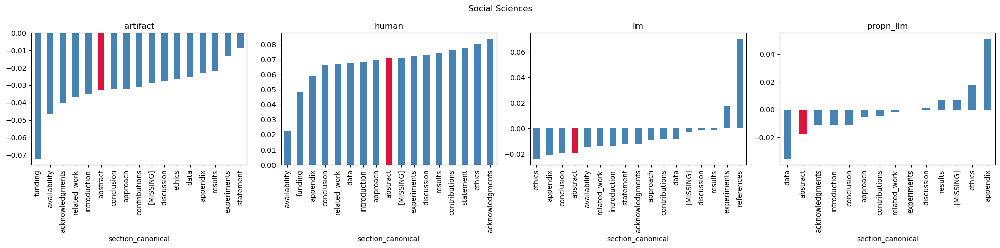

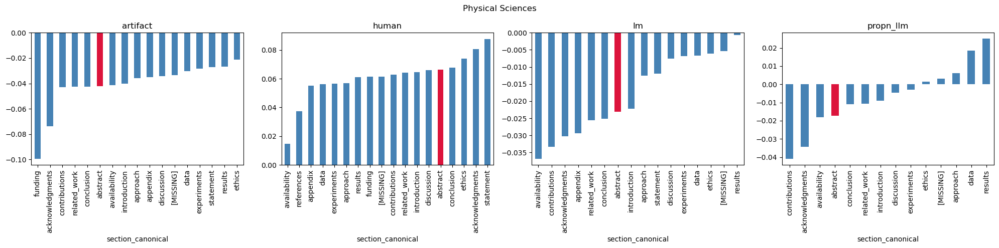

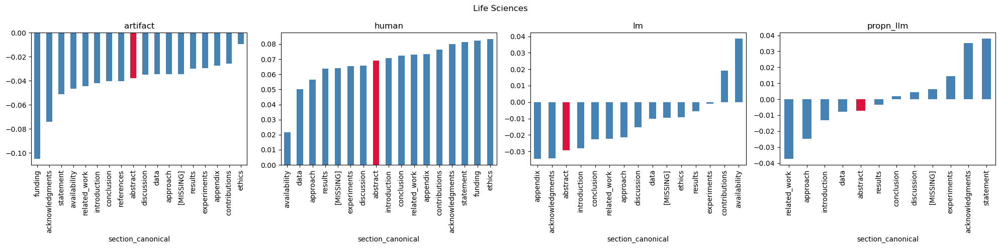

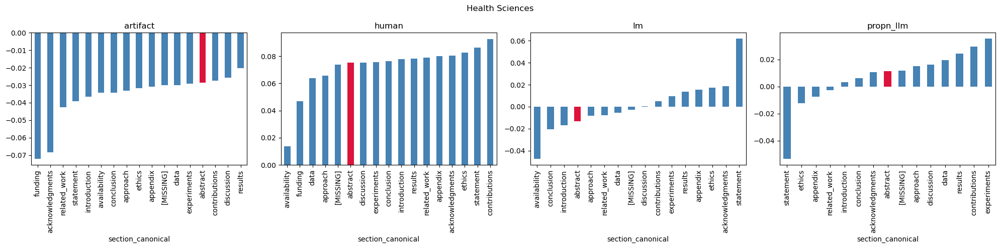

In [48]:
for domain in df_dedup.domain.unique():
    subset = df_dedup[df_dedup["domain"] == domain]
    plot_section_scores(subset, domain)

<Axes: ylabel='Frequency'>

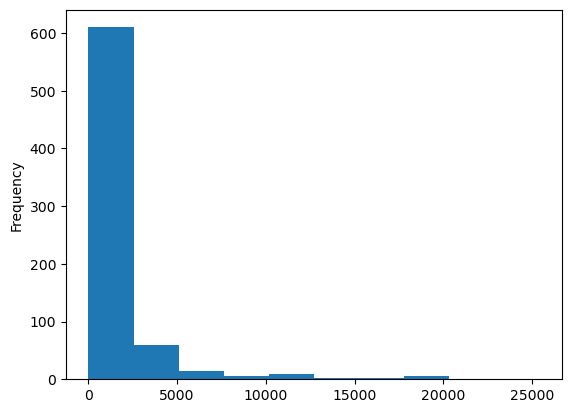

In [49]:
df_dedup.groupby(["year", "domain"], observed=True).section_canonical.value_counts().plot.hist()

In [50]:
df_dedup.section_canonical.value_counts()

section_canonical
[MISSING]          452257
introduction       119309
approach           115000
discussion          88326
abstract            49842
conclusion          46011
results             37108
experiments         29235
related_work        19008
data                11117
ethics               3769
acknowledgments      2628
contributions        2346
appendix             1354
statement            1070
availability          582
funding               109
references             14
Name: count, dtype: int64

In [51]:
for row in df_dedup[df_dedup["section_canonical"].isin(("acknowledgments", "contributions", "statement", "availability", "references"))].groupby("section_canonical").sample(3).itertuples():
    print(row.section, row.section_canonical, row.entity)
    print(row.sentence)
    print()

Acknowledgments acknowledgments Framework
We acknowledge support from The Danish Agency for Science, Technology and Innovation, Denmark (FENAMI project 10-093456); the research leading to these results has also received funding from the European Union's Seventh Framework Programme for research, technological development and demonstration under grant agreement no.

Acknowledgments acknowledgments AI
A fundus image is shown with the model's prediction, its confidence level (from 0% to 100 %, with 100% being the highest confidence score), and explanation in the form of blue bounding boxes around the regions for which the AI model believes that they contain signs of DR.

ACKNOWLEDGMENTS acknowledgments we
With our deepest gratitude, we acknowledge the time our participants generously invested in this project.

Data availability and quality availability Network
Network logs, user behavior data, and threat intelligence feeds can contain irrelevant information, missing values, and inconsisten

## Save the coarse section categorization

In [49]:
df.columns

Index(['paper_id', 'year', 'domain', 'source_file', 'global_i',
       'sentence_index', 'section', 'section_type', 'paragraph_index',
       'sent_id', 'match_id', 'sentence', 'masked_sentence_minimal',
       'masked_sentence_chunk', 'entity', 'entity_lower', 'in_noun_chunk',
       'chunk_text', 'chunk_root_text', 'chunk_root_dep', 'head', 'score',
       'role', 'token_i', 'token_text', 'pos', 'tag', 'dep', 'ent_type',
       'ent_iob', 'entity_type', 'num_tokens', 'entity_type_updated'],
      dtype='object')

In [50]:
df_dedup.columns

Index(['paper_id', 'year', 'domain', 'source_file', 'global_i',
       'sentence_index', 'section', 'section_type', 'paragraph_index',
       'sent_id', 'match_id', 'sentence', 'masked_sentence_minimal',
       'masked_sentence_chunk', 'entity', 'entity_lower', 'in_noun_chunk',
       'chunk_text', 'chunk_root_text', 'chunk_root_dep', 'head', 'score',
       'role', 'token_i', 'token_text', 'pos', 'tag', 'dep', 'ent_type',
       'ent_iob', 'entity_type', 'num_tokens', 'entity_type_updated',
       'section_normalized', 'section_canonical'],
      dtype='object')

In [51]:
id_cols

['paper_id',
 'source_file',
 'global_i',
 'sentence_index',
 'section',
 'section_type',
 'paragraph_index',
 'sent_id',
 'match_id',
 'score']

In [52]:
len(df)

1011876

In [53]:
len(df_dedup)

979085

In [56]:
updated = df.merge(df_dedup[id_cols + ["section_canonical"]], on=id_cols, how="left")
updated.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1011876 entries, 0 to 1011875
Data columns (total 34 columns):
 #   Column                   Non-Null Count    Dtype   
---  ------                   --------------    -----   
 0   paper_id                 1011876 non-null  category
 1   year                     1011876 non-null  int64   
 2   domain                   1011876 non-null  category
 3   source_file              1011876 non-null  category
 4   global_i                 1011876 non-null  int64   
 5   sentence_index           1011876 non-null  int64   
 6   section                  991385 non-null   object  
 7   section_type             1011876 non-null  category
 8   paragraph_index          1011876 non-null  int64   
 9   sent_id                  1011876 non-null  int64   
 10  match_id                 1011876 non-null  int64   
 11  sentence                 1011876 non-null  object  
 12  masked_sentence_minimal  1011876 non-null  object  
 13  masked_sentence_chunk    10

In [58]:
updated.isna().sum()

paper_id                        0
year                            0
domain                          0
source_file                     0
global_i                        0
sentence_index                  0
section                     20491
section_type                    0
paragraph_index                 0
sent_id                         0
match_id                        0
sentence                        0
masked_sentence_minimal         0
masked_sentence_chunk           0
entity                          0
entity_lower                    0
in_noun_chunk                   0
chunk_text                  20010
chunk_root_text             20010
chunk_root_dep              20010
head                        20010
score                           0
role                            0
token_i                         0
token_text                      0
pos                             0
tag                             0
dep                             0
ent_type                   833598
ent_iob       

In [59]:
df_dedup.section_canonical.isna().sum()

0

In [62]:
updated[updated["section_canonical"].isna()].section.unique()

array(['Abstract', 'Abstract:', 'ABSTRACT:', 'ABSTRACT'], dtype=object)

In [63]:
updated["section_canonical"] = updated["section_canonical"].fillna("abstract")

In [65]:
updated.to_csv("../data/new-method-fulltexts-cleaned-updated.csv", index=False)

Remove human terms for analysis

In [52]:
no_human_terms = df_dedup[df_dedup["entity_type"] != "human"].copy()
len(no_human_terms) / len(df_dedup)

0.6870945832077909

In [57]:
no_human_terms["entity_type_updated"] = no_human_terms["entity_type_updated"].cat.remove_unused_categories()

In [53]:
no_human_terms.groupby("paper_id", observed=True)["section_canonical"].value_counts().describe()

count    28907.000000
mean        23.272010
std         43.094191
min          1.000000
25%          5.000000
50%         11.000000
75%         24.000000
max       1402.000000
Name: count, dtype: float64

In [54]:
no_human_terms.groupby("paper_id", observed=True)["section_canonical"].size().describe()

count    4913.000000
mean      136.927336
std       127.184387
min         1.000000
25%        60.000000
50%       104.000000
75%       171.000000
max      1725.000000
Name: section_canonical, dtype: float64

In [59]:
lm_terms_only = df_dedup[df_dedup["entity_type"] == "lm"].copy()
lm_terms_only["entity_type_updated"] = lm_terms_only["entity_type_updated"].cat.remove_unused_categories()

In [60]:
len(lm_terms_only) / len(df_dedup)

0.08008191321488942

In [61]:
lm_terms_only.section_canonical.value_counts()

section_canonical
[MISSING]          30956
introduction       10833
approach           10291
discussion          7262
abstract            4872
results             3520
conclusion          3466
experiments         3198
related_work        2724
data                 757
ethics               195
contributions        158
appendix              85
acknowledgments       40
statement             33
availability          16
references             1
Name: count, dtype: int64

In [109]:
abstracts = df_dedup[df_dedup["section_canonical"] == "abstract"].copy()
abstracts["dep"] = abstracts["dep"].cat.remove_unused_categories()
len(abstracts)

49842

In [98]:
pd.crosstab(abstracts.year, abstracts.domain)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2016,421,343,889,582
2017,444,442,1327,532
2018,646,466,1336,899
2019,768,742,1456,766
2020,1546,1157,1625,1025
2021,1743,1213,1693,1536
2022,1596,1234,1714,1560
2023,1396,1001,1542,1309
2024,1456,1159,1784,1591


## Load document and section level scores

In [9]:
docs = pd.read_csv("../data/doc-scores-fulltexts.csv")
docs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4913 entries, 0 to 4912
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   paper_id                    4913 non-null   object 
 1   year                        4913 non-null   int64  
 2   domain                      4913 non-null   object 
 3   contains_artifact           4913 non-null   bool   
 4   contains_lm                 4913 non-null   bool   
 5   contains_propn_llm          4913 non-null   bool   
 6   contains_human              4913 non-null   bool   
 7   num_artifact                4913 non-null   int64  
 8   num_lm                      4913 non-null   int64  
 9   num_propn_llm               4913 non-null   int64  
 10  num_human                   4913 non-null   int64  
 11  num_sents                   4913 non-null   int64  
 12  num_unique_entities         4913 non-null   int64  
 13  num_unique_entities_nonhum  4913 

In [10]:
secs = pd.read_csv("../data/section-scores-fulltexts.csv")
secs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31678 entries, 0 to 31677
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   paper_id                    31678 non-null  object 
 1   section_canonical           31678 non-null  object 
 2   year                        31678 non-null  int64  
 3   domain                      31678 non-null  object 
 4   contains_artifact           31678 non-null  bool   
 5   contains_lm                 31678 non-null  bool   
 6   contains_propn_llm          31678 non-null  bool   
 7   contains_human              31678 non-null  bool   
 8   num_artifact                31678 non-null  int64  
 9   num_lm                      31678 non-null  int64  
 10  num_propn_llm               31678 non-null  int64  
 11  num_human                   31678 non-null  int64  
 12  num_sents                   31678 non-null  int64  
 13  num_unique_entities         316

## Helper initialization

In [11]:
legend_map = {
    "artifact": "artifact",
    "lm": "LM",
    "propn_llm": "product name",
    "propn": "product name",
    "product_name": "product name",
    "human": "human"
}

In [12]:
size_order = ["Physical Sciences", "Social Sciences", "Health Sciences", "Life Sciences"]
domain_order = ["Physical Sciences", "Life Sciences", "Social Sciences", "Health Sciences"]

In [13]:
avg_score_cols = [col for col in docs.columns if col.startswith("avg_score")]
contains_cols = [col for col in docs.columns if col.startswith("contains")]
num_cols = [col for col in docs.columns if col.startswith("num")]
sorted_avg_cols = docs[avg_score_cols].mean().sort_values().index

In [14]:
entity_order = ["artifact", "lm", "propn_llm", "human"]

In [15]:
entity_order_mapped = ["artifact", "LM", "product name"]

In [16]:
col_to_label = {
    "avg_score_artifact": "Artifact",
    "avg_score": "Artifact + LM",
    "avg_score_lm_no_propn": "LM",
    "avg_score_lm": "LM",
    "avg_score_propn_llm": "Product name",
    "avg_score_human": "Human"
}
to_plot_cols = ["avg_score_artifact", "avg_score_lm_no_propn", "avg_score_propn_llm", "avg_score_human"]

In [17]:
sections_of_interest = ("introduction", "methods", "discussion", "abstract", "conclusion", "results", "experiments", "related_work", "data", "ethics", "[MISSING]")

In [18]:
et_palette = sns.color_palette("seismic", 4)
et_palette

[(0.0, 0.0, 0.8599999999999999),
 (0.6, 0.6, 1.0),
 (1.0, 0.6, 0.6),
 (0.9, 0.0, 0.0)]

## Check robustness using the binary interpretation of the score on human pronouns

In [36]:
human_pronouns = {"we", "she", "he", "i", "us", "her", "him"}
df_dedup[df_dedup["entity_lower"].isin(human_pronouns)].groupby("entity_lower", observed=True)["humanlike"].agg(["mean", "std"]).sort_values("mean", ascending=False)

,mean,std
entity_lower,,
she,0.982088,0.132666
her,0.968590,0.174456
he,0.963008,0.188764
i,0.962011,0.191178
him,0.944043,0.230046
us,0.939673,0.238111
we,0.915433,0.278237


In [43]:
print(pd.DataFrame(df_dedup[df_dedup["entity_lower"].isin(human_pronouns)].groupby("entity_lower", observed=True)["humanlike"].mean().sort_values(ascending=False)).T.to_latex(float_format="%.3f"))

\begin{tabular}{lrrrrrrr}
\toprule
entity_lower & she & her & he & i & him & us & we \\
\midrule
humanlike & 0.982 & 0.969 & 0.963 & 0.962 & 0.944 & 0.940 & 0.915 \\
\bottomrule
\end{tabular}



In [33]:
df_dedup[df_dedup["entity_lower"].isin(human_pronouns)].groupby(["domain", "entity_lower"], observed=True)["humanlike"].mean().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
he,0.938272,0.968326,0.961102,0.967928
her,0.971875,0.976242,0.976562,0.959964
him,0.955224,0.916667,0.947826,0.954167
i,0.963710,0.951362,0.947077,0.978651
she,0.991379,0.976821,0.989418,0.976553
us,0.959337,0.938619,0.945290,0.927882
we,0.903651,0.908674,0.914698,0.931088


## Document-level summaries
The document-level summary collects all sentences (that include a target entity; the original paper is highly likely to include many more sentences)
and calculates statistics for them. The "default" average score is calculated by using the mean of both artifact and LM term scores, but the average
score for each entity type is also calculated.

In [38]:
def get_doc_summary(df: pd.DataFrame):
    return df.groupby("paper_id", observed=True).agg(
        year=("year", "first"),
        domain=("domain", "first"),
        
        contains_artifact=("entity_type", lambda x: (x == "artifact").any()),
        contains_lm=("entity_type", lambda x: (x == "lm").any()),
        contains_propn_llm=("entity_type_updated", lambda x: (x == "propn_llm").any()),
        contains_human=("entity_type", lambda x: (x == "human").any()),
        
        num_artifact=("entity_type", lambda x: (x == "artifact").sum()),
        num_lm=("entity_type_updated", lambda x: (x == "lm").sum()),
        num_propn_llm=("entity_type_updated", lambda x: (x == "propn_llm").sum()),
        num_human=("entity_type", lambda x: (x == "human").sum()),
        num_sents=("paper_id", "size"),
        num_unique_entities=("entity_lower", "nunique"),
        num_unique_entities_nonhum=("entity_lower", lambda x: x[df.loc[x.index, "entity_type"] != "human"].nunique()),

        avg_score=("score", lambda x: x[df.loc[x.index, "entity_type"] != "human"].mean()),
        avg_score_artifact=("score", lambda x: x[df.loc[x.index, "entity_type"] == "artifact"].mean()),
        avg_score_lm=("score", lambda x: x[df.loc[x.index, "entity_type"] == "lm"].mean()),
        avg_score_lm_no_propn=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "lm"].mean()),
        avg_score_propn_llm=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "propn_llm"].mean()),
        avg_score_human=("score", lambda x: x[df.loc[x.index, "entity_type"] == "human"].mean())
    )

In [68]:
docs = get_doc_summary(df_dedup)

In [81]:
docs.info()

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 4913 entries, W169306565 to W7140044697
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   year                        4913 non-null   int64   
 1   domain                      4913 non-null   category
 2   contains_artifact           4913 non-null   bool    
 3   contains_lm                 4913 non-null   bool    
 4   contains_propn_llm          4913 non-null   bool    
 5   contains_human              4913 non-null   bool    
 6   num_artifact                4913 non-null   int64   
 7   num_lm                      4913 non-null   int64   
 8   num_propn_llm               4913 non-null   int64   
 9   num_human                   4913 non-null   int64   
 10  num_sents                   4913 non-null   int64   
 11  num_unique_entities         4913 non-null   int64   
 12  num_unique_entities_nonhum  4913 non-null   int64   
 

In [24]:
# Are there fulltexts that contribute no artifact / LM mentions?
term_mask = ((docs["contains_artifact"] == False) &
             (docs["contains_lm"] == False) &
             (docs["contains_propn_llm"] == False))
docs[term_mask]

,paper_id,year,domain,contains_artifact,contains_lm,contains_propn_llm,contains_human,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_unique_entities_nonhum,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human


In [25]:
docs.isna().sum()

paper_id                         0
year                             0
domain                           0
contains_artifact                0
contains_lm                      0
contains_propn_llm               0
contains_human                   0
num_artifact                     0
num_lm                           0
num_propn_llm                    0
num_human                        0
num_sents                        0
num_unique_entities              0
num_unique_entities_nonhum       0
avg_score                        0
avg_score_artifact               3
avg_score_lm                  2953
avg_score_lm_no_propn         2979
avg_score_propn_llm           4321
avg_score_human                 42
dtype: int64

In [73]:
# Drop instances that do not contribute to average scores
docs = docs.dropna(subset="avg_score")

In [74]:
docs.reset_index().to_csv("../data/doc-scores-fulltexts.csv", index=False)

In [26]:
# Descriptive statistics of year x domain
summary = pd.crosstab(docs.domain, docs.year, margins=True)
summary

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,All
domain,,,,,,,,,,,,
Health Sciences,58,65,80,74,142,143,149,104,113,142,36,1106
Life Sciences,72,71,85,90,125,159,133,112,116,139,35,1137
Physical Sciences,104,149,147,152,159,154,153,143,146,155,55,1517
Social Sciences,68,73,100,87,112,150,141,114,140,133,35,1153
All,302,358,412,403,538,606,576,473,515,569,161,4913


In [27]:
conditions = [
    docs["contains_propn_llm"],
    docs["contains_lm"],
    docs["contains_artifact"]
]

choices = [
    "propn",
    "lm",
    "artifact"
]

docs["paper_type"] = np.select(conditions, choices, default="human_only")
docs["paper_type"].value_counts()

paper_type
artifact    2953
lm          1368
propn        592
Name: count, dtype: int64

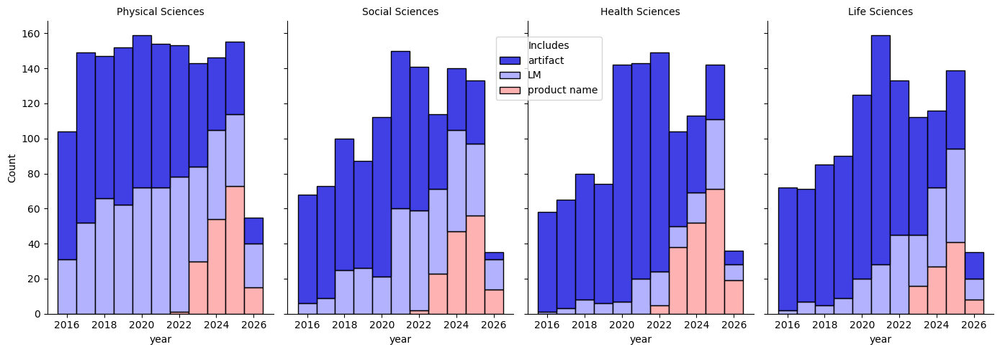

In [31]:
renamed = docs.rename(columns={"paper_type": "Includes"})
renamed["Includes"] = renamed["Includes"].replace(legend_map)
renamed["year"] = renamed["year"].astype("category")
g = sns.displot(renamed, x="year", hue="Includes", col="domain", col_order=size_order,
                multiple="stack", palette=et_palette[:-1], height=5, aspect=0.7, facet_kws=dict(legend_out=False))
g.set_titles(col_template="{col_name}")
sns.move_legend(g, "center", bbox_to_anchor=(0.548, 0.8), frameon=True)
plt.savefig("../figures/displot-fulltexts.pdf", bbox_inches="tight")
plt.show()

In [61]:
df_dedup.score.describe()

count    979085.000000
mean          0.000214
std           0.071756
min          -0.238577
25%          -0.053106
50%          -0.011337
75%           0.051568
max           0.295244
Name: score, dtype: float64

In [60]:
docs[to_plot_cols].describe()

,avg_score_artifact,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
count,4910.000000,1934.000000,592.000000,4871.000000
mean,-0.033073,-0.018809,-0.004559,0.064774
std,0.020423,0.032325,0.033843,0.022192
min,-0.145281,-0.135615,-0.112835,-0.121752
25%,-0.045768,-0.037990,-0.026272,0.051235
50%,-0.035456,-0.021321,-0.004948,0.063816
75%,-0.023213,-0.000735,0.013648,0.078326
max,0.082754,0.163920,0.158022,0.183439


Document-level scores

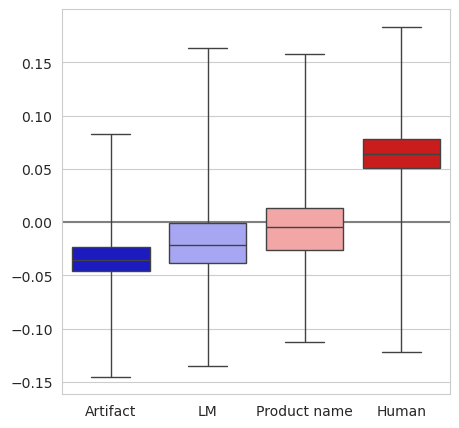

In [62]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.axhline(0, color="gray")
    sns.boxplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic", whis=(0, 100), fliersize=2, ax=ax) # 
    #plt.xticks(rotation=45, ha="right")
    #plt.tight_layout()
    plt.savefig("../figures/entity_type_scores_fulltexts.pdf", bbox_inches="tight")
    plt.show()

Section-level scores

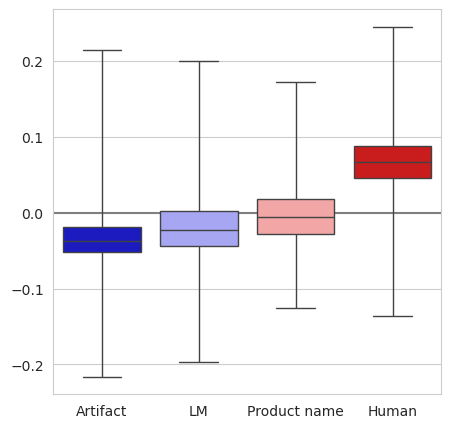

In [74]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.axhline(0, color="gray")
    sns.boxplot(secs[to_plot_cols].rename(columns=col_to_label), palette="seismic", whis=(0, 100), fliersize=2, ax=ax) # 
    #plt.xticks(rotation=45, ha="right")
    #plt.tight_layout()
    #plt.savefig("../figures/entity_type_scores_fulltexts.pdf", bbox_inches="tight")
    plt.show()

Document-level scores

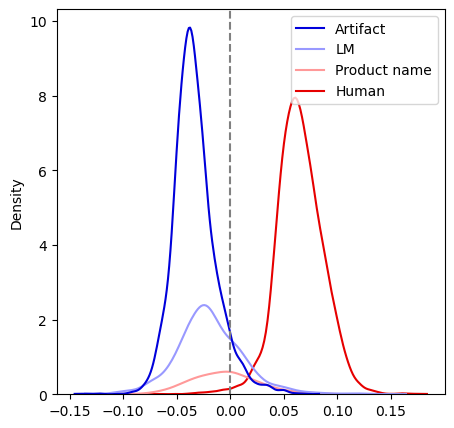

In [63]:
plt.figure(figsize=(5,5))
ax = sns.kdeplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic", cut=0)
ax.axvline(0, color="gray", linestyle="--")
plt.savefig("../figures/entity_type_scores_kde_fulltexts.pdf", bbox_inches="tight")
plt.show()

Section-level scores

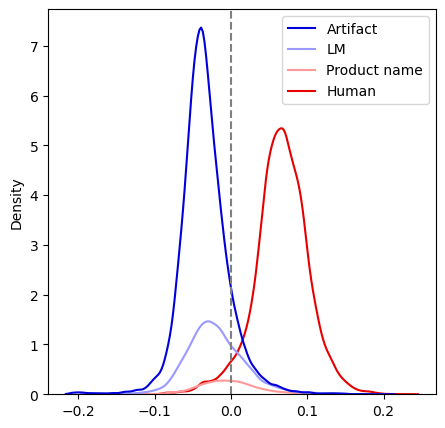

In [77]:
plt.figure(figsize=(5,5))
ax = sns.kdeplot(secs[to_plot_cols].rename(columns=col_to_label), palette="seismic", cut=0)
ax.axvline(0, color="gray", linestyle="--")
#plt.savefig("../figures/entity_type_scores_kde_fulltexts.pdf", bbox_inches="tight")
plt.show()

In [32]:
docs.describe()

,year,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_unique_entities_nonhum,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
count,4913.000000,4913.000000,4913.000000,4913.000000,4913.000000,4913.000000,4913.000000,4913.000000,4913.000000,4910.000000,1960.000000,1934.000000,592.000000,4871.000000
mean,2021.127417,120.968248,14.111134,1.847954,62.349074,199.276410,19.296560,13.307755,-0.030824,-0.033073,-0.017141,-0.018809,-0.004559,0.064774
std,2.828148,118.583468,36.689463,9.876223,69.736974,170.345599,7.073873,5.146840,0.021318,0.020423,0.031417,0.032325,0.033843,0.022192
min,2016.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,-0.145281,-0.145281,-0.135615,-0.135615,-0.112835,-0.121752
25%,2019.000000,50.000000,0.000000,0.000000,21.000000,96.000000,15.000000,10.000000,-0.044271,-0.045768,-0.036057,-0.037990,-0.026272,0.051235
50%,2021.000000,88.000000,0.000000,0.000000,44.000000,157.000000,19.000000,13.000000,-0.033602,-0.035456,-0.019829,-0.021321,-0.004948,0.063816
75%,2024.000000,151.000000,8.000000,0.000000,81.000000,250.000000,24.000000,16.000000,-0.019894,-0.023213,0.000500,-0.000735,0.013648,0.078326
max,2026.000000,1725.000000,601.000000,170.000000,1575.000000,2651.000000,52.000000,38.000000,0.082754,0.082754,0.163920,0.163920,0.158022,0.183439


In [112]:
docs.info()

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 4913 entries, W169306565 to W7140044697
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   year                        4913 non-null   int64   
 1   domain                      4913 non-null   category
 2   contains_artifact           4913 non-null   bool    
 3   contains_lm                 4913 non-null   bool    
 4   contains_propn_llm          4913 non-null   bool    
 5   contains_human              4913 non-null   bool    
 6   num_artifact                4913 non-null   int64   
 7   num_lm                      4913 non-null   int64   
 8   num_propn_llm               4913 non-null   int64   
 9   num_human                   4913 non-null   int64   
 10  num_sents                   4913 non-null   int64   
 11  num_unique_entities         4913 non-null   int64   
 12  num_unique_entities_nonhum  4913 non-null   int64   
 

<Axes: >

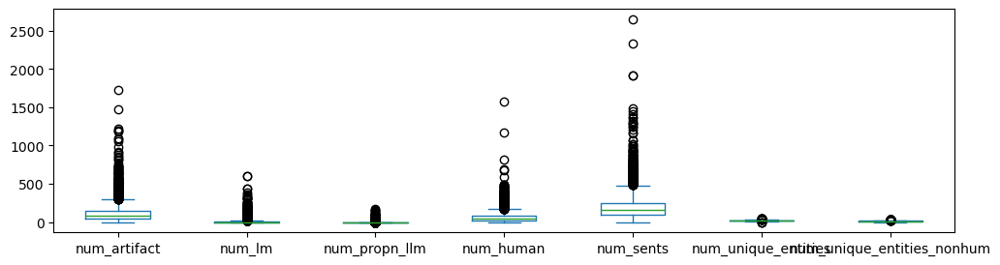

In [33]:
docs.select_dtypes(include=["int64"]).drop(columns="year").plot.box(figsize=(12,3))

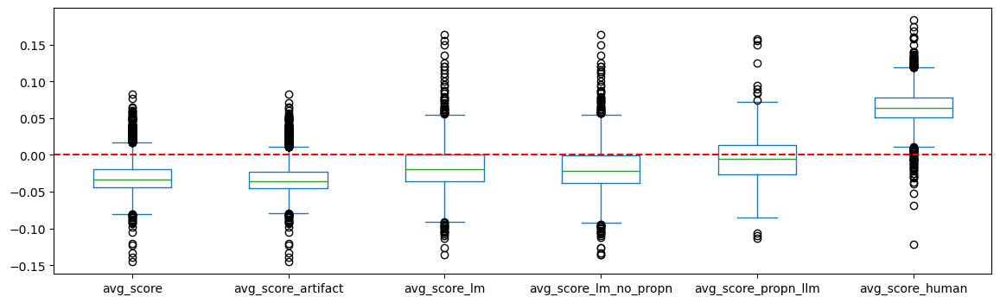

In [34]:
ax = docs.select_dtypes(include=["float64"]).plot.box(figsize=(14,4))
ax.axhline(0, color="red", linestyle="--")

In the section-level summary the paper is divided into the abstract and the rest.
A finer-grained sectioning is not necessarily meaningful, as the section names are not standardized.

In [39]:
abstracts = get_doc_summary(df_dedup[df_dedup["section_type"] == "abstract"])
bodies = get_doc_summary(df_dedup[df_dedup["section_type"] == "body"])

In [40]:
abstracts["section_type"] = "abstract"
bodies["section_type"] = "body"
docs_per_section = pd.concat([abstracts, bodies], ignore_index=True)
docs_per_section

,year,domain,contains_artifact,contains_lm,contains_propn_llm,contains_human,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_unique_entities_nonhum,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human,section_type
0,2023,Social Sciences,True,False,False,False,17,0,0,0,17,5,5,-0.041515,-0.041515,NaN,NaN,NaN,NaN,abstract
1,2017,Physical Sciences,True,False,False,True,14,0,0,1,15,5,4,-0.009286,-0.009286,NaN,NaN,NaN,0.086980,abstract
2,2021,Physical Sciences,True,True,False,True,6,2,0,2,10,5,4,-0.026313,-0.022090,-0.038983,-0.038983,NaN,0.097229,abstract
3,2017,Physical Sciences,True,False,False,True,2,0,0,1,3,3,2,-0.084604,-0.084604,NaN,NaN,NaN,0.114982,abstract
4,2017,Physical Sciences,True,True,False,True,4,3,0,7,14,5,4,-0.057932,-0.052138,-0.065657,-0.065657,NaN,0.036200,abstract
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9530,2026,Physical Sciences,True,True,True,True,122,6,1,61,190,29,21,-0.030685,-0.029400,-0.053084,-0.061321,-0.003661,0.062727,body
9531,2026,Health Sciences,True,False,False,True,60,0,0,1,61,13,12,-0.025434,-0.025434,NaN,NaN,NaN,0.110181,body
9532,2026,Health Sciences,True,True,True,True,99,33,1,37,170,23,20,-0.039290,-0.040387,-0.036097,-0.036289,-0.029740,0.071659,body
9533,2026,Social Sciences,True,False,False,True,111,0,0,31,142,19,12,-0.014532,-0.014532,NaN,NaN,NaN,0.094205,body


In [41]:
# Descriptive statistics of year x domain in abstracts
abs_summary = pd.crosstab(abstracts.domain, abstracts.year, margins=True)
abs_summary

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,All
domain,,,,,,,,,,,,
Health Sciences,54,60,73,66,127,141,145,100,108,136,35,1045
Life Sciences,63,65,72,81,123,145,126,104,110,129,30,1048
Physical Sciences,100,142,141,148,156,152,152,136,139,152,55,1473
Social Sciences,59,65,97,80,99,143,133,107,133,130,32,1078
All,276,332,383,375,505,581,556,447,490,547,152,4644


In [42]:
# Descriptive statistics of year x domain in bodies
body_summary = pd.crosstab(bodies.domain, bodies.year, margins=True)
body_summary

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,All
domain,,,,,,,,,,,,
Health Sciences,58,64,80,73,143,142,148,103,113,140,36,1100
Life Sciences,72,69,84,89,126,157,132,112,117,139,35,1132
Physical Sciences,103,150,147,152,158,154,153,143,146,153,55,1514
Social Sciences,67,71,98,87,111,150,141,113,140,132,35,1145
All,300,354,409,401,538,603,574,471,516,564,161,4891


Pair the data section-level data, dropping the papers that are missing either the abstract or the body.

In [44]:
paired = abstracts.drop(columns="section_type").merge(bodies.drop(columns=["year", "domain", "section_type"]), on="paper_id", suffixes=("_abs", "_body"))
paired

,year,domain,contains_artifact_abs,contains_lm_abs,contains_propn_llm_abs,contains_human_abs,num_artifact_abs,num_lm_abs,num_propn_llm_abs,num_human_abs,...,num_human_body,num_sents_body,num_unique_entities_body,num_unique_entities_nonhum_body,avg_score_body,avg_score_artifact_body,avg_score_lm_body,avg_score_lm_no_propn_body,avg_score_propn_llm_body,avg_score_human_body
paper_id,,,,,,,,,,,,,,,,,,,,,
W169306565,2023,Social Sciences,True,False,False,False,17,0,0,0,...,16,125,17,11,-0.036351,-0.036351,NaN,NaN,NaN,0.060470
W2353482882,2017,Physical Sciences,True,False,False,True,14,0,0,1,...,55,150,15,10,-0.009984,-0.009984,NaN,NaN,NaN,0.042440
W2395693197,2021,Physical Sciences,True,True,False,True,6,2,0,2,...,56,104,12,8,-0.032838,-0.037283,-0.029926,-0.029926,NaN,0.063939
W2417333619,2017,Physical Sciences,True,False,False,True,2,0,0,1,...,48,159,18,16,-0.043742,-0.043345,-0.058042,-0.058042,NaN,0.066706
W2514713644,2017,Physical Sciences,True,True,False,True,4,3,0,7,...,44,135,10,8,-0.037200,-0.034495,-0.069659,-0.069659,NaN,0.044838
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
W7128682674,2026,Physical Sciences,True,False,False,True,7,0,0,5,...,61,190,29,21,-0.030685,-0.029400,-0.053084,-0.061321,-0.003661,0.062727
W7130706075,2026,Health Sciences,True,False,False,True,11,0,0,1,...,1,61,13,12,-0.025434,-0.025434,NaN,NaN,NaN,0.110181
W7130932744,2026,Health Sciences,True,True,False,False,10,5,0,0,...,37,170,23,20,-0.039290,-0.040387,-0.036097,-0.036289,-0.029740,0.071659


In [120]:
paired.isna().sum()

year                                  0
domain                                0
contains_artifact_abs                 0
contains_lm_abs                       0
contains_propn_llm_abs                0
contains_human_abs                    0
num_artifact_abs                      0
num_lm_abs                            0
num_propn_llm_abs                     0
num_human_abs                         0
num_sents_abs                         0
num_unique_entities_abs               0
num_unique_entities_nonhum_abs        0
avg_score_abs                        42
avg_score_artifact_abs              122
avg_score_lm_abs                   3422
avg_score_lm_no_propn_abs          3466
avg_score_propn_llm_abs            4434
avg_score_human_abs                 957
contains_artifact_body                0
contains_lm_body                      0
contains_propn_llm_body               0
contains_human_body                   0
num_artifact_body                     0
num_lm_body                           0


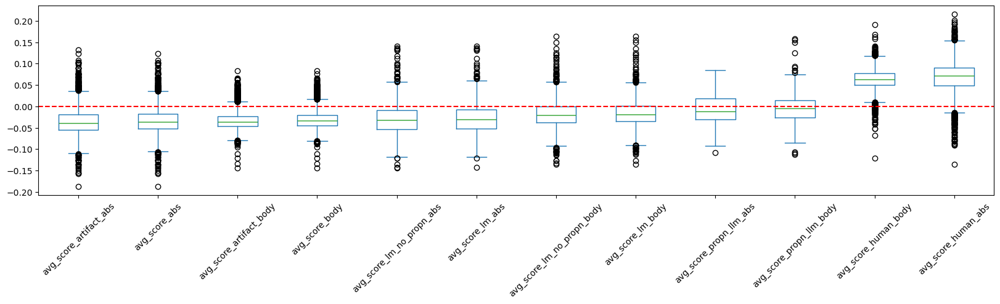

In [45]:
ax = (paired.select_dtypes(include=["float64"])
    .pipe(lambda x: x[x.mean().sort_values().index])
    .plot.box(figsize=(20, 4), rot=45))
ax.axhline(0, color="red", linestyle="--")
plt.show()

In [46]:
len(paired)

4614

In [47]:
paired.domain.value_counts(normalize=True)

domain
Physical Sciences    0.318379
Social Sciences      0.231686
Life Sciences        0.225401
Health Sciences      0.224534
Name: proportion, dtype: float64

In [49]:
paired.describe(include="int")

,year,num_artifact_abs,num_lm_abs,num_propn_llm_abs,num_human_abs,num_sents_abs,num_unique_entities_abs,num_unique_entities_nonhum_abs,num_artifact_body,num_lm_body,num_propn_llm_body,num_human_body,num_sents_body,num_unique_entities_body,num_unique_entities_nonhum_body
count,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000,4614.000000
mean,2021.167534,6.987213,0.929345,0.118336,2.670351,10.705245,5.282618,4.029476,117.339402,13.622453,1.773082,61.186389,193.921326,19.246207,13.261162
std,2.814193,4.963256,2.170840,0.786758,2.558723,6.075383,2.278633,2.028519,116.623587,35.337671,9.515597,68.645986,167.157853,6.995250,5.098686
min,2016.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2019.000000,3.000000,0.000000,0.000000,1.000000,6.000000,4.000000,3.000000,48.000000,0.000000,0.000000,21.000000,93.000000,14.000000,10.000000
50%,2021.000000,6.000000,0.000000,0.000000,2.000000,10.000000,5.000000,4.000000,84.000000,0.000000,0.000000,43.000000,151.000000,19.000000,13.000000
75%,2024.000000,9.000000,0.000000,0.000000,4.000000,14.000000,7.000000,5.000000,146.750000,8.000000,0.000000,79.000000,242.000000,24.000000,16.000000
max,2026.000000,63.000000,17.000000,14.000000,25.000000,68.000000,17.000000,14.000000,1708.000000,592.000000,165.000000,1562.000000,2642.000000,52.000000,38.000000


## Section-level summaries

In [166]:
def get_section_summary(df: pd.DataFrame):
    return df.groupby(["paper_id", "section_canonical"], observed=True).agg(
        year=("year", "first"),
        domain=("domain", "first"),
        
        contains_artifact=("entity_type", lambda x: (x == "artifact").any()),
        contains_lm=("entity_type", lambda x: (x == "lm").any()),
        contains_propn_llm=("entity_type_updated", lambda x: (x == "propn_llm").any()),
        contains_human=("entity_type", lambda x: (x == "human").any()),
        
        num_artifact=("entity_type", lambda x: (x == "artifact").sum()),
        num_lm=("entity_type_updated", lambda x: (x == "lm").sum()),
        num_propn_llm=("entity_type_updated", lambda x: (x == "propn_llm").sum()),
        num_human=("entity_type", lambda x: (x == "human").sum()),
        num_sents=("paper_id", "size"),
        num_unique_entities=("entity_lower", "nunique"),
        num_unique_entities_nonhum=("entity_lower", lambda x: x[df.loc[x.index, "entity_type"] != "human"].nunique()),

        avg_score=("score", lambda x: x[df.loc[x.index, "entity_type"] != "human"].mean()),
        avg_score_artifact=("score", lambda x: x[df.loc[x.index, "entity_type"] == "artifact"].mean()),
        avg_score_lm=("score", lambda x: x[df.loc[x.index, "entity_type"] == "lm"].mean()),
        avg_score_lm_no_propn=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "lm"].mean()),
        avg_score_propn_llm=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "propn_llm"].mean()),
        avg_score_human=("score", lambda x: x[df.loc[x.index, "entity_type"] == "human"].mean())
    )

In [ ]:
secs = get_section_summary(df_dedup)

In [64]:
secs

,paper_id,section_canonical,year,domain,contains_artifact,contains_lm,contains_propn_llm,contains_human,num_artifact,num_lm,...,num_human,num_sents,num_unique_entities,num_unique_entities_nonhum,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
0,W169306565,[MISSING],2023,Social Sciences,True,False,False,True,26,0,...,2,28,8,6,-0.027350,-0.027350,NaN,NaN,NaN,0.068691
1,W169306565,abstract,2023,Social Sciences,True,False,False,False,17,0,...,0,17,5,5,-0.041515,-0.041515,NaN,NaN,NaN,NaN
2,W169306565,acknowledgments,2023,Social Sciences,True,False,False,True,1,0,...,1,2,2,1,-0.168241,-0.168241,NaN,NaN,NaN,0.087013
3,W169306565,approach,2023,Social Sciences,True,False,False,True,21,0,...,2,23,8,7,-0.012032,-0.012032,NaN,NaN,NaN,-0.021429
4,W169306565,conclusion,2023,Social Sciences,True,False,False,True,16,0,...,5,21,7,4,-0.036197,-0.036197,NaN,NaN,NaN,0.049839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31673,W7140044697,approach,2026,Social Sciences,True,False,False,True,36,0,...,2,38,10,9,-0.060853,-0.060853,NaN,NaN,NaN,0.058804
31674,W7140044697,conclusion,2026,Social Sciences,True,False,False,False,17,0,...,0,17,5,5,-0.049655,-0.049655,NaN,NaN,NaN,NaN
31675,W7140044697,contributions,2026,Social Sciences,True,False,False,True,22,0,...,1,23,10,9,-0.056967,-0.056967,NaN,NaN,NaN,0.104317
31676,W7140044697,discussion,2026,Social Sciences,True,False,False,True,25,0,...,3,28,9,7,-0.053662,-0.053662,NaN,NaN,NaN,0.061307


In [171]:
secs.reset_index().to_csv("../data/section-scores-fulltexts.csv", index=False)

In [175]:
secs = secs.reset_index()

In [177]:
secs = secs.dropna(subset="avg_score")

In [78]:
secs.section_canonical.value_counts()

section_canonical
[MISSING]          4741
abstract           4651
introduction       4054
approach           3483
conclusion         3349
discussion         2973
results            1957
experiments        1590
acknowledgments    1162
data               1062
related_work        918
statement           501
contributions       368
availability        306
ethics              291
appendix            203
funding              64
references            5
Name: count, dtype: int64

## Pair the data

In [19]:
keep_sections = {"abstract", "introduction", "approach", "conclusion", "discussion", "results", "experiments", "data", "related_work"}

In [14]:
#keep_sections = set(secs.section_canonical.value_counts()[lambda x: x > 1000].index)

In [26]:
secs.groupby(["domain", "section_canonical"], observed=True).size().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
[MISSING],1048.0,1097.0,1480.0,1116.0
abstract,1046.0,1049.0,1475.0,1081.0
acknowledgments,280.0,346.0,351.0,185.0
appendix,59.0,55.0,57.0,32.0
approach,763.0,760.0,1194.0,766.0
availability,122.0,95.0,49.0,40.0
conclusion,666.0,636.0,1209.0,838.0
contributions,117.0,110.0,83.0,58.0
data,263.0,251.0,379.0,169.0


In [27]:
secs.section_canonical.unique()

array(['[MISSING]', 'abstract', 'acknowledgments', 'approach',
       'conclusion', 'data', 'discussion', 'ethics', 'introduction',
       'related_work', 'results', 'experiments', 'funding', 'statement',
       'appendix', 'availability', 'contributions', 'references'],
      dtype=object)

In [28]:
secs.paper_id.nunique()

4921

In [20]:
secs_abs = secs[secs["section_canonical"] == "abstract"].dropna(subset="avg_score").copy()

In [21]:
secs_bod = secs[(secs["section_canonical"] != "abstract") & (secs["section_canonical"].isin(keep_sections))].dropna(subset="avg_score").copy()

In [22]:
secs_abs_ids = set(secs_abs.paper_id.unique())
secs_bod_ids = set(secs_bod.paper_id.unique())
paired_ids = secs_abs_ids.intersection(secs_bod_ids)
len(paired_ids)

4453

In [23]:
paired_secs = secs[(secs["paper_id"].isin(paired_ids)) & (secs["section_canonical"].isin(keep_sections))].dropna(subset="avg_score").copy()

In [24]:
paired_secs.groupby(["paper_id"], observed=True).size().describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    4453.00000
mean        5.00539
std         1.52972
min         2.00000
1%          2.00000
5%          3.00000
10%         3.00000
25%         4.00000
50%         5.00000
75%         6.00000
90%         7.00000
95%         8.00000
99%         9.00000
max         9.00000
dtype: float64

In [25]:
paired_secs[avg_score_cols].describe()

,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
count,22289.000000,21910.000000,6498.000000,6246.000000,1166.000000,18739.000000
mean,-0.031769,-0.034251,-0.019287,-0.020776,-0.004256,0.065289
std,0.030388,0.030397,0.037734,0.038527,0.038375,0.035055
min,-0.209972,-0.209972,-0.162462,-0.196301,-0.125249,-0.135831
25%,-0.050404,-0.052764,-0.044288,-0.045886,-0.029676,0.046042
50%,-0.035022,-0.037425,-0.023023,-0.025041,-0.006382,0.066592
75%,-0.016284,-0.018883,0.001971,0.000379,0.018034,0.087374
max,0.213850,0.213850,0.187127,0.187127,0.172041,0.227599


In [26]:
sec_anthro_order = paired_secs[paired_secs["section_canonical"] != "abstract"].groupby("section_canonical", observed=True)["avg_score"].mean().sort_values().index

In [27]:
paired_secs.groupby(["domain", "section_canonical"], observed=True)["avg_score"].mean().unstack("domain").mean(axis=1).sort_values(ascending=False)

section_canonical
results        -0.020337
experiments    -0.023470
data           -0.027232
discussion     -0.028557
approach       -0.030245
abstract       -0.033397
conclusion     -0.035289
introduction   -0.036460
related_work   -0.037894
dtype: float64

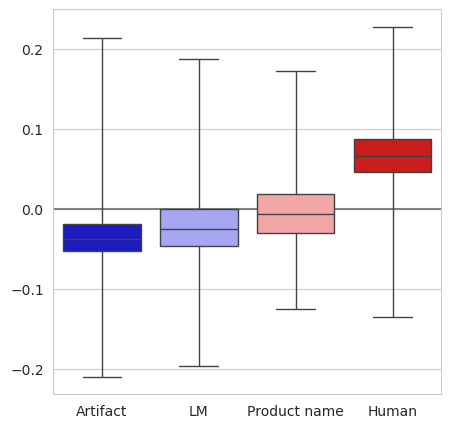

In [41]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.axhline(0, color="gray")
    sns.boxplot(paired_secs[to_plot_cols].rename(columns=col_to_label), palette="seismic", whis=(0, 100), fliersize=2, ax=ax) 
    #plt.xticks(rotation=45, ha="right")
    #plt.tight_layout()
    plt.savefig("../figures/entity_type_scores_fulltexts.pdf", bbox_inches="tight")
    plt.show()

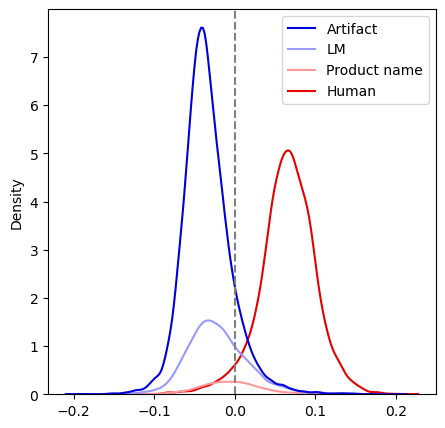

In [40]:
plt.figure(figsize=(5,5))
ax = sns.kdeplot(paired_secs[to_plot_cols].rename(columns=col_to_label), palette="seismic", cut=0)
ax.axvline(0, color="gray", linestyle="--")
#plt.savefig("../figures/entity_type_scores_kde_fulltexts.pdf", bbox_inches="tight")
plt.show()

<Axes: xlabel='count', ylabel='Count'>

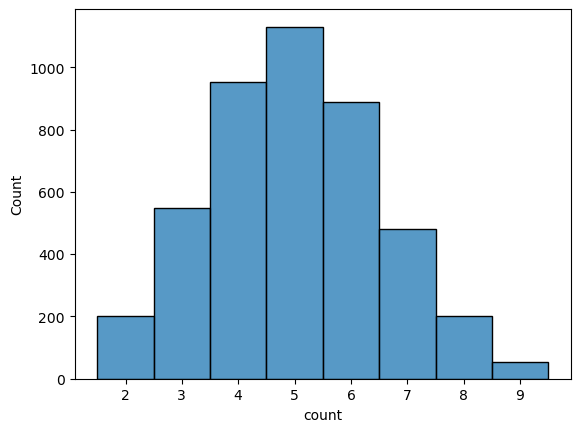

In [25]:
sns.histplot(paired_secs["paper_id"].value_counts(), discrete=True)

In [69]:
paired_secs.section_canonical.value_counts()

section_canonical
abstract        4453
introduction    3844
approach        3241
conclusion      3158
discussion      2759
results         1717
experiments     1368
related_work     884
data             865
Name: count, dtype: int64

In [71]:
pd.crosstab(paired_secs.domain, paired_secs.section_canonical)

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,999,692,624,218,771,260,816,95,412
Life Sciences,988,686,570,193,645,261,817,119,366
Physical Sciences,1440,1147,1173,313,761,609,1325,458,560
Social Sciences,1026,716,791,141,582,238,886,212,379


In [72]:
paired_secs.isna().sum()

paper_id                          0
section_canonical                 0
year                              0
domain                            0
contains_artifact                 0
contains_lm                       0
contains_propn_llm                0
contains_human                    0
num_artifact                      0
num_lm                            0
num_propn_llm                     0
num_human                         0
num_sents                         0
num_unique_entities               0
num_unique_entities_nonhum        0
avg_score                         0
avg_score_artifact              379
avg_score_lm                  15791
avg_score_lm_no_propn         16043
avg_score_propn_llm           21123
avg_score_human                3550
dtype: int64

## Alternative section groupings?

Trying to find the largest subset where the papers have as many common sections as possible.

In [43]:
pattern = paired_secs.groupby("paper_id")["section_canonical"].agg(lambda s: tuple(sorted(s)))
pattern.value_counts().head(10)

section_canonical
(abstract, approach, conclusion, discussion, introduction)                 282
(abstract, approach, conclusion, introduction)                             274
(abstract, conclusion, introduction)                                       205
(abstract, approach, conclusion, discussion, introduction, results)        196
(abstract, approach, discussion, introduction)                             153
(abstract, conclusion, discussion, introduction)                           144
(abstract, approach, conclusion, introduction, results)                    132
(abstract, approach, discussion, introduction, results)                    128
(abstract, approach, conclusion, discussion, experiments, introduction)    111
(abstract, discussion, introduction)                                       108
Name: count, dtype: int64

In [50]:
from collections import Counter

sets = paired_secs.groupby("paper_id")["section_canonical"].agg(frozenset)   # one frozenset of section names per id
counts = Counter(sets)

def support(S, counts):
    S = frozenset(S)
    return sum(n for s, n in counts.items() if S <= s)

imrad_cols = {"abstract", "introduction", "approach", "results", "discussion"}
print(support(imrad_cols, counts))

for s, n in counts.most_common(10):
    print(n, len(s), sorted(s))
rows = [{"sections": sorted(S), "n_sections": len(S), "n_ids": support(S, counts)}
        for S in counts]
tradeoff = (pd.DataFrame(rows)
              .sort_values(["n_sections", "n_ids"], ascending=False))
best_per_size = tradeoff.loc[tradeoff.groupby("n_sections")["n_ids"].idxmax()]
best_per_size.head(10)

858
282 5 ['abstract', 'approach', 'conclusion', 'discussion', 'introduction']
274 4 ['abstract', 'approach', 'conclusion', 'introduction']
205 3 ['abstract', 'conclusion', 'introduction']
196 6 ['abstract', 'approach', 'conclusion', 'discussion', 'introduction', 'results']
153 4 ['abstract', 'approach', 'discussion', 'introduction']
144 4 ['abstract', 'conclusion', 'discussion', 'introduction']
132 5 ['abstract', 'approach', 'conclusion', 'introduction', 'results']
128 5 ['abstract', 'approach', 'discussion', 'introduction', 'results']
111 6 ['abstract', 'approach', 'conclusion', 'discussion', 'experiments', 'introduction']
108 3 ['abstract', 'discussion', 'introduction']


,sections,n_sections,n_ids
1,"[abstract, introduction]",2,3844
6,"[abstract, conclusion, introduction]",3,2835
2,"[abstract, approach, conclusion, introduction]",4,2154
12,"[abstract, approach, conclusion, discussion, i...",5,1256
10,"[abstract, approach, conclusion, discussion, i...",6,603
57,"[abstract, approach, conclusion, discussion, e...",7,261
55,"[abstract, approach, conclusion, discussion, e...",8,125
14,"[abstract, approach, conclusion, data, discuss...",9,53


In [54]:
tradeoff.loc[tradeoff["n_sections"] == 4]

,sections,n_sections,n_ids
2,"[abstract, approach, conclusion, introduction]",4,2154
23,"[abstract, approach, discussion, introduction]",4,1804
0,"[abstract, conclusion, discussion, introduction]",4,1594
48,"[abstract, approach, conclusion, discussion]",4,1376
36,"[abstract, approach, introduction, results]",4,1248
9,"[abstract, conclusion, introduction, results]",4,1114
117,"[abstract, approach, conclusion, results]",4,1028
32,"[abstract, discussion, introduction, results]",4,1020
106,"[abstract, approach, experiments, introduction]",4,998
31,"[abstract, approach, discussion, results]",4,992


In [48]:
best_per_size.sections.tolist()

[['abstract', 'introduction'],
 ['abstract', 'conclusion', 'introduction'],
 ['abstract', 'approach', 'conclusion', 'introduction'],
 ['abstract', 'approach', 'conclusion', 'discussion', 'introduction'],
 ['abstract',
  'approach',
  'conclusion',
  'discussion',
  'introduction',
  'results'],
 ['abstract',
  'approach',
  'conclusion',
  'discussion',
  'experiments',
  'introduction',
  'results'],
 ['abstract',
  'approach',
  'conclusion',
  'discussion',
  'experiments',
  'introduction',
  'related_work',
  'results'],
 ['abstract',
  'approach',
  'conclusion',
  'data',
  'discussion',
  'experiments',
  'introduction',
  'related_work',
  'results']]

## Descrpitive statistics and plots

In [28]:
pstats = paired_secs.groupby("paper_id", observed=True).agg(
    year=("year", "first"),
    domain=("domain", "first"),
    contains_artifact=("contains_artifact", "any"),
    contains_lm=("contains_lm", "any"),
    contains_prod=("contains_propn_llm", "any"),
    contains_human=("contains_human", "any"),
    section_count=("section_canonical", "size")
)

conditions = [
    pstats["contains_prod"],
    pstats["contains_lm"],
    pstats["contains_artifact"]
]

choices = [
    "product_name",
    "lm",
    "artifact"
]

pstats["paper_type"] = np.select(conditions, choices, default="human_only")

pd.crosstab(pstats.domain, pstats.year, margins=True)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,All
domain,,,,,,,,,,,,
Health Sciences,51,57,63,60,122,136,142,96,105,132,35,999
Life Sciences,56,57,66,74,117,141,120,98,106,124,29,988
Physical Sciences,95,139,136,144,153,149,149,133,137,150,55,1440
Social Sciences,50,56,92,75,92,141,131,99,132,126,32,1026
All,252,309,357,353,484,567,542,426,480,532,151,4453


In [27]:
pstats.paper_type.value_counts(normalize=True)

paper_type
artifact        0.639569
lm              0.262744
product_name    0.097687
Name: proportion, dtype: float64

In [28]:
pd.crosstab(pstats.domain, pstats.paper_type, normalize="index")

paper_type,artifact,lm,product_name
domain,,,
Health Sciences,0.734735,0.109109,0.156156
Life Sciences,0.727733,0.209514,0.062753
Physical Sciences,0.520833,0.395139,0.084028
Social Sciences,0.628655,0.277778,0.093567


In [29]:
print(pd.crosstab(pstats.domain, pstats.paper_type, normalize="index").to_latex(float_format="%.2f"))

\begin{tabular}{lrrr}
\toprule
paper_type & artifact & lm & product_name \\
domain &  &  &  \\
\midrule
Health Sciences & 0.73 & 0.11 & 0.16 \\
Life Sciences & 0.73 & 0.21 & 0.06 \\
Physical Sciences & 0.52 & 0.40 & 0.08 \\
Social Sciences & 0.63 & 0.28 & 0.09 \\
\bottomrule
\end{tabular}



In [30]:
pstats.domain.value_counts(normalize=True)

domain
Physical Sciences    0.323377
Social Sciences      0.230406
Health Sciences      0.224343
Life Sciences        0.221873
Name: proportion, dtype: float64

In [31]:
pstats.section_count.describe()

count    4453.00000
mean        5.00539
std         1.52972
min         2.00000
25%         4.00000
50%         5.00000
75%         6.00000
max         9.00000
Name: section_count, dtype: float64

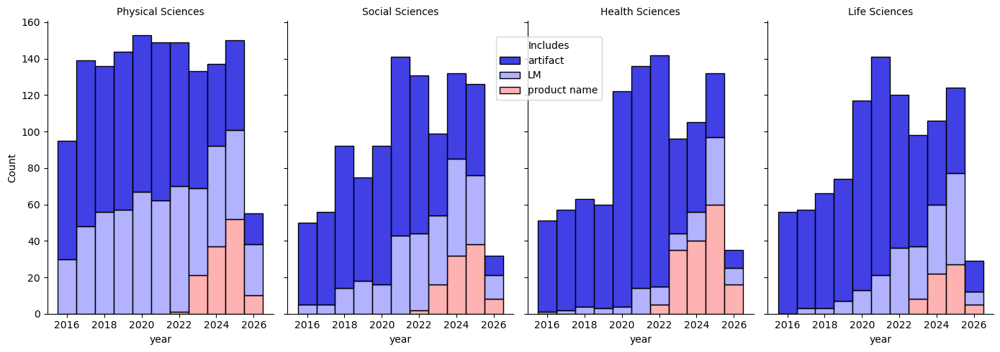

In [32]:
renamed = pstats.rename(columns={"paper_type": "Includes"})
renamed["Includes"] = renamed["Includes"].replace(legend_map)
renamed["year"] = renamed["year"].astype("category")
g = sns.displot(renamed, x="year", hue="Includes", col="domain", col_order=size_order, hue_order=entity_order_mapped,
                multiple="stack", palette=et_palette[:-1], height=5, aspect=0.7, facet_kws=dict(legend_out=False))
g.set_titles(col_template="{col_name}")
sns.move_legend(g, "center", bbox_to_anchor=(0.548, 0.8), frameon=True)
plt.savefig("../figures/displot-fulltexts.pdf", bbox_inches="tight")
plt.show()

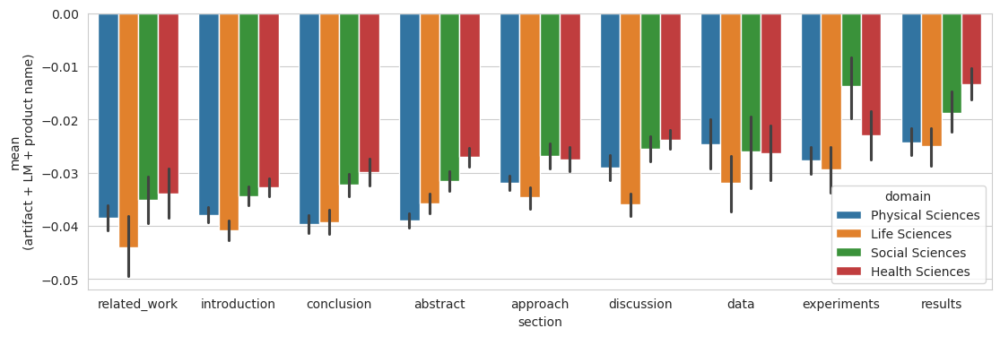

In [106]:
sec_sort_order = (paired_secs.groupby(["domain", "section_canonical"], observed=True)
    ["avg_score"].mean().unstack("domain").mean(axis=1).sort_values().index)

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.barplot(paired_secs, y="avg_score", x="section_canonical", hue="domain", hue_order=domain_order, order=sec_sort_order, ax=ax)
    ax.set_ylabel("mean\n(artifact + LM + product name)")
    ax.set_xlabel("section")
    plt.savefig("../figures/section_means.pdf", bbox_inches="tight")
    plt.show()

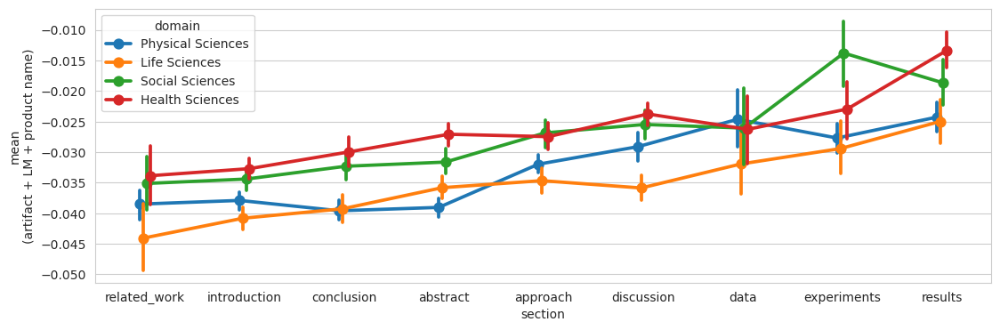

In [100]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.pointplot(paired_secs, y="avg_score", x="section_canonical", hue="domain", hue_order=domain_order, order=sec_sort_order, dodge=True, ax=ax)
    ax.set_ylabel("mean\n(artifact + LM + product name)")
    ax.set_xlabel("section")
    plt.savefig("../figures/section_means_pointplot.pdf", bbox_inches="tight")
    plt.show()

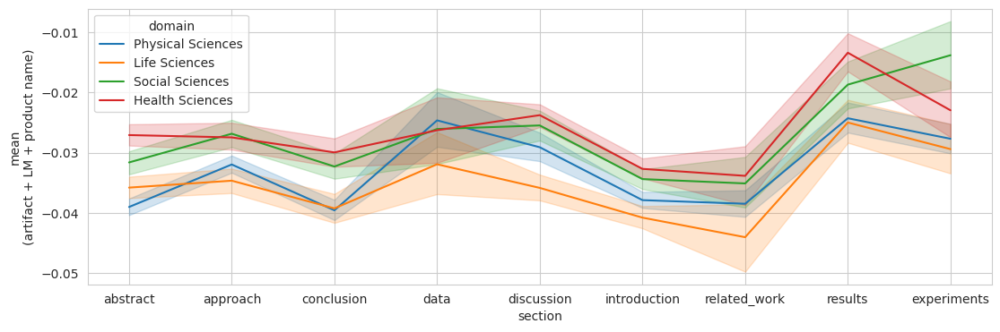

In [105]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.lineplot(paired_secs, y="avg_score", x="section_canonical", hue="domain", hue_order=domain_order, ax=ax) #dodge=True, order=sec_sort_order
    ax.set_ylabel("mean\n(artifact + LM + product name)")
    ax.set_xlabel("section")
    #plt.savefig("../figures/section_means_lineplot.pdf", bbox_inches="tight")
    plt.show()

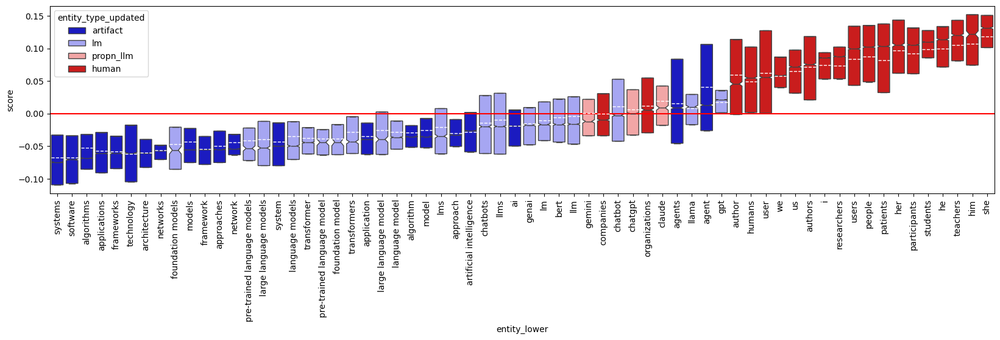

In [141]:
median_order = df_dedup.groupby("entity_lower", observed=True)["score"].median().sort_values().index
fig, ax = plt.subplots(figsize=(20, 4))
sns.boxplot(df_dedup, y="score", x="entity_lower",
            showmeans=True, meanline=True, meanprops={"color": "white"},
            whis=(25, 75), showfliers=False, notch=True,
            ax=ax, order=median_order, hue="entity_type_updated", hue_order=entity_order,
            dodge=False, palette=et_palette)
ax.axhline(0, color="red")
plt.xticks(rotation=90)
plt.show()

## Abstract vs other sections diff inspection

As the goal is to inspect if abstracts differ from the bodies, analyze the diff for each section separately.

In [35]:
def rank_biserial(d):
    d = d[d != 0]
    rk = stats.rankdata(np.abs(d))
    return (rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum()

In [43]:
abs_ = paired_secs.loc[paired_secs.section_canonical == "abstract", ["paper_id", "avg_score"]].rename(columns={"avg_score": "abstract_score"})
MIN_N = 20
rows = []
for (dom, sec), g in paired_secs[paired_secs.section_canonical != "abstract"].groupby(["domain", "section_canonical"], observed=True):
    m = g.merge(abs_[["paper_id", "abstract_score"]], on="paper_id")   # domain already fixed by the groupby
    d = (m["avg_score"] - m["abstract_score"]).to_numpy()
    if len(d) < MIN_N or np.all(d == 0):
        continue
    ci = stats.bootstrap((d,), np.median, confidence_level=0.95,
                         n_resamples=5000, random_state=0).confidence_interval
    r_ci = stats.bootstrap((d,), rank_biserial, confidence_level=0.95,
                         n_resamples=5000, random_state=0).confidence_interval
    rows.append({"domain": dom, "section": sec, "n": len(d),
                 "mean_diff": np.mean(d), "median_diff": np.median(d), 
                 "ci_low": ci.low, "ci_high": ci.high,
                 "rank_biserial": rank_biserial(d), "r_ci_low": r_ci.low, "r_ci_high": r_ci.high,
                 "p": stats.wilcoxon(d).pvalue})

paired_res = pd.DataFrame(rows)
paired_res["p_holm"] = multipletests(paired_res["p"], method="holm")[1]   # correct across all domain x section tests
paired_res["significant"] = paired_res["p_holm"] < 0.05
paired_res["section"] = pd.Categorical(paired_res["section"], keep_sections, ordered=True)
paired_res = paired_res.sort_values(["domain", "section"])
paired_res

,domain,section,n,mean_diff,median_diff,ci_low,ci_high,rank_biserial,r_ci_low,r_ci_high,p,p_holm,significant
3,Health Sciences,discussion,771,0.000052,-0.001143,-0.003564,0.001715,-0.012963,-0.092848,0.069520,7.551691e-01,1.000000e+00,False
4,Health Sciences,experiments,260,0.005373,0.004171,0.000012,0.009596,0.158444,0.013516,0.289834,2.678270e-02,3.908907e-01,False
2,Health Sciences,data,218,0.004223,0.004755,-0.001212,0.011659,0.093209,-0.056828,0.241202,2.327896e-01,1.000000e+00,False
0,Health Sciences,approach,692,0.001981,0.000981,-0.001468,0.004442,0.082927,-0.005497,0.166824,5.877366e-02,7.052839e-01,False
7,Health Sciences,results,412,0.010391,0.008707,0.005553,0.011746,0.364089,0.257490,0.464450,1.513723e-10,4.389797e-09,True
6,Health Sciences,related_work,95,-0.003536,-0.006441,-0.010922,0.005938,-0.167982,-0.386718,0.071475,1.551302e-01,1.000000e+00,False
5,Health Sciences,introduction,816,-0.004862,-0.004799,-0.007550,-0.002663,-0.219951,-0.296680,-0.145427,5.339704e-08,1.388323e-06,True
1,Health Sciences,conclusion,624,-0.000921,-0.001507,-0.004040,0.001203,-0.057692,-0.148870,0.034931,2.118206e-01,1.000000e+00,False
11,Life Sciences,discussion,645,-0.003241,-0.002772,-0.005066,-0.000821,-0.104471,-0.193287,-0.017779,2.152416e-02,3.496723e-01,False
12,Life Sciences,experiments,261,0.005143,0.004145,0.000497,0.009260,0.158901,0.018348,0.291743,2.605938e-02,3.908907e-01,False


In [38]:
paired_res.n.describe()

count      32.000000
mean      557.375000
std       319.235554
min        95.000000
25%       260.750000
50%       576.000000
75%       763.500000
max      1325.000000
Name: n, dtype: float64

In [84]:
def n_to_size(n, n_min, n_max, s_min=10, s_max=50):
    if n_max == n_min:
        return (s_min + s_max) / 2
    return s_min + (n - n_min) / (n_max - n_min) * (s_max - s_min)
    
def forestplot(res, save_as=""):
    res_plot = res.reset_index()

    n_min, n_max = res_plot.n.min(), res_plot.n.max()
    
    sig_color = "C3"      # red for significant
    ns_color = "0.6"       # grey for not significant
    alpha = 0.01
    
    fig, axes = plt.subplots(1, int(res.domain.nunique()), figsize=(2.2 * len(domain_order), 0.4 * res.section.nunique()),
                             sharey=True, sharex=True)
    axes = axes.flatten()
    
    for ax, sec in zip(axes, domain_order):
        sub = res_plot[res_plot.domain == sec].set_index("section").reindex(sec_anthro_order).reset_index()
        sub["y"] = range(len(sub))
    
        for mask, color in [(sub.p_holm < alpha, sig_color), (sub.p_holm >= alpha, ns_color)]:
            g = sub[mask]
            if g.empty:
                continue
            ax.errorbar(g.rank_biserial, g.y,
                        xerr=[g.rank_biserial - g.r_ci_low, g.r_ci_high - g.rank_biserial],
                        fmt="none", color=color, capsize=3, zorder=2)
            ax.scatter(g.rank_biserial, g.y, color=color,
                   s=n_to_size(g.n, n_min, n_max), zorder=2)

        # annotate n next to each point
        """
        for _, r in sub.iterrows():
            ax.annotate(f"n={r.n}", (r.ci_high, r.y), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=7, color="0.3")
        """
        vlines = [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5]
        ax.axvline(0, color="firebrick", ls="--")
        ax.set_xticks(vlines)
        ax.set_xticklabels(vlines, fontsize=8)
        for x in vlines:
            ax.axvline(x, color="0.8", ls="--", linewidth="0.9")
        ax.set_yticks(sub.y)
        ax.set_yticklabels(sec_anthro_order)
        ax.set_title(sec)
    
    # one shared legend for the whole figure
    handles = [plt.Line2D([0], [0], marker="o", color=sig_color, linestyle="", label=f"p (Holm-adjusted) < {alpha}"),
               plt.Line2D([0], [0], marker="o", color=ns_color, linestyle="", label="not significant")]
    fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))
    #axes[0].invert_yaxis()
    fig.supxlabel("Rank-biserial (r) (95% CI)", fontsize=10)
    fig.subplots_adjust(bottom=0.14)
    if save_as:
        plt.savefig(f"../figures/{save_as}", bbox_inches="tight")
    
    plt.tight_layout()
    plt.show()

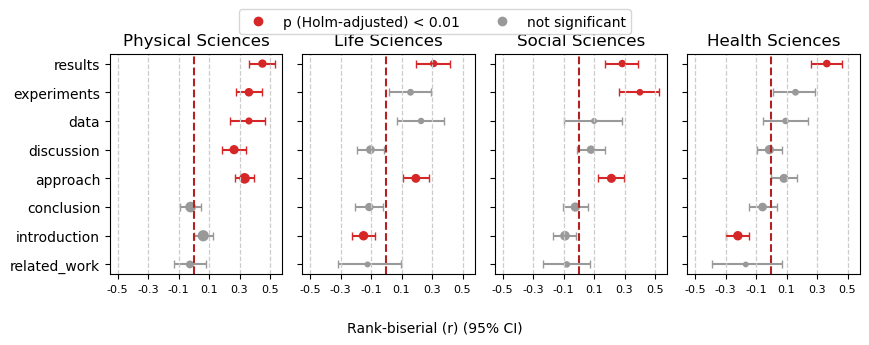

In [85]:
forestplot(paired_res, save_as="forestplot-paired-rank-biserial.pdf")

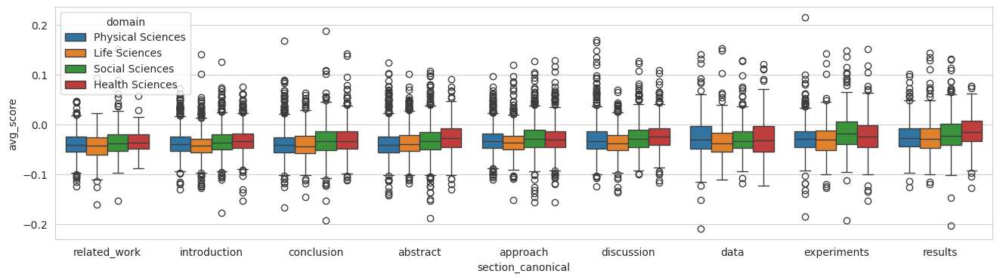

In [142]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(16,4))
    sns.boxplot(paired_secs, x="section_canonical", y="avg_score", order=sec_sort_order, hue="domain", hue_order=domain_order, ax=ax)
    plt.show()

In [107]:
def plot_scores_per_section_ordered(df, score_col, groupby_cols=["domain", "section_canonical"], unstack_col="domain"):
    display(df.groupby(groupby_cols, observed=True)[score_col].count().unstack(unstack_col))
    
    axis = 1 if unstack_col == "domain" else 0
    sec_sort_order = (df.groupby(groupby_cols, observed=True)
    [score_col].mean().unstack(unstack_col).mean(axis=axis).sort_values().index)

    median = df.groupby(groupby_cols, observed=True)[score_col].median().median()
    mean = df.groupby(groupby_cols, observed=True)[score_col].mean().mean()

    x = sec_sort_order
    y = domain_order
    if unstack_col != "domain":
        y, x = x, y
    
    ax = (df.groupby(groupby_cols, observed=True)
    [score_col].mean().unstack(unstack_col).loc[x, y]
    .plot.bar(figsize=(12, 3)))
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(score_col)
    ax.axhline(median, color="gray")
    ax.axhline(mean, color="lightgray", linestyle="--")
    plt.show()

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,999,988,1440,1026
approach,692,686,1147,716
conclusion,624,570,1173,791
data,218,193,313,141
discussion,771,645,761,582
experiments,260,261,609,238
introduction,816,817,1325,886
related_work,95,119,458,212
results,412,366,560,379


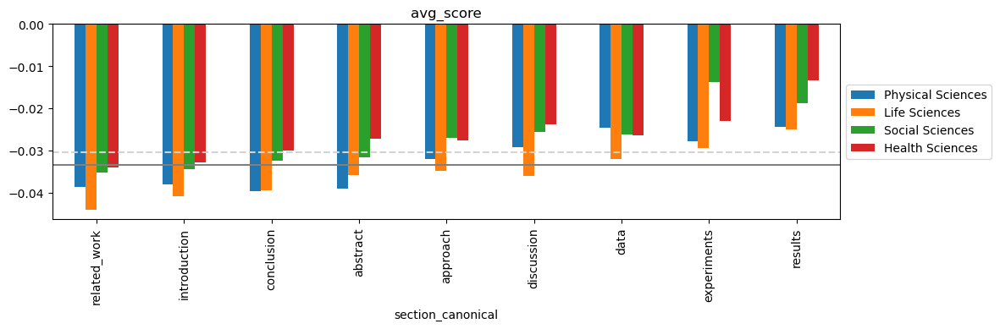

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,987,978,1408,1002
approach,685,677,1136,708
conclusion,612,563,1143,776
data,210,191,289,136
discussion,767,641,738,575
experiments,254,255,592,230
introduction,814,816,1321,881
related_work,91,116,444,209
results,397,361,540,367


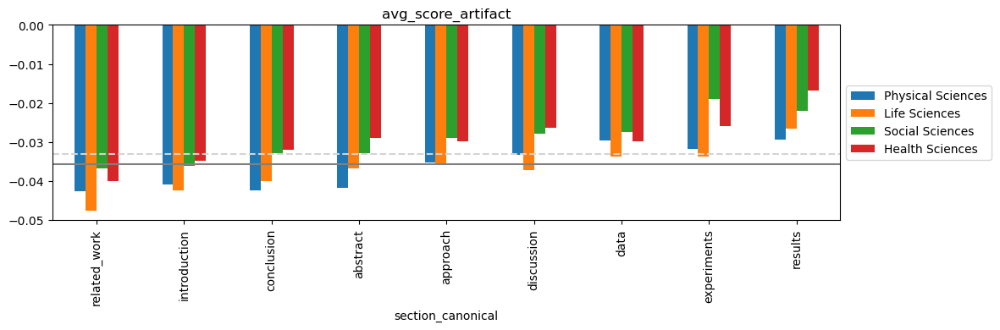

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,198,201,564,216
approach,160,179,495,204
conclusion,132,86,427,152
data,34,30,115,34
discussion,169,141,272,170
experiments,51,61,281,78
introduction,189,198,561,245
related_work,40,34,252,66
results,84,72,210,97


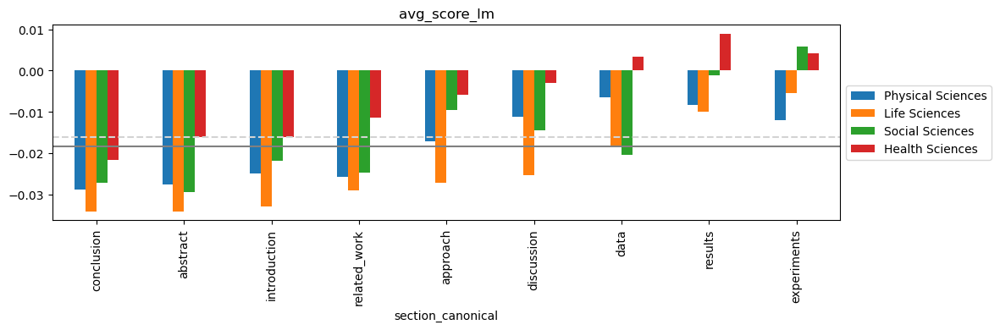

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,182,196,558,202
approach,138,175,488,197
conclusion,118,83,422,142
data,28,29,112,31
discussion,151,138,266,159
experiments,46,60,274,73
introduction,177,190,559,236
related_work,39,33,252,65
results,63,69,203,92


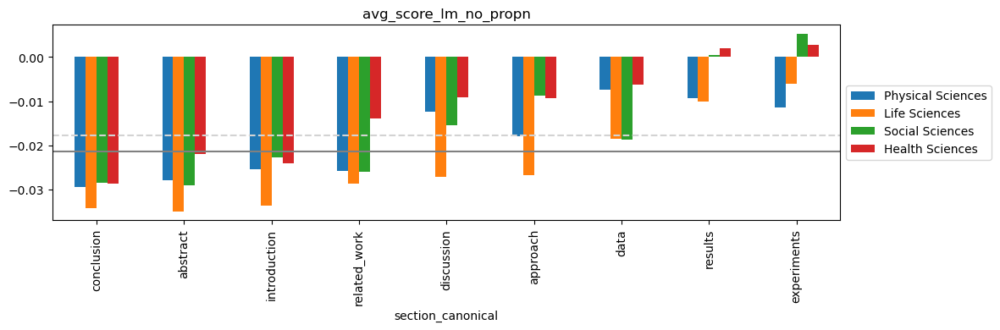

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,93,18,39,31
approach,69,25,55,42
conclusion,48,9,37,27
data,14,6,10,6
discussion,90,20,40,33
experiments,19,8,33,13
introduction,100,29,64,45
related_work,13,6,22,11
results,42,10,24,15


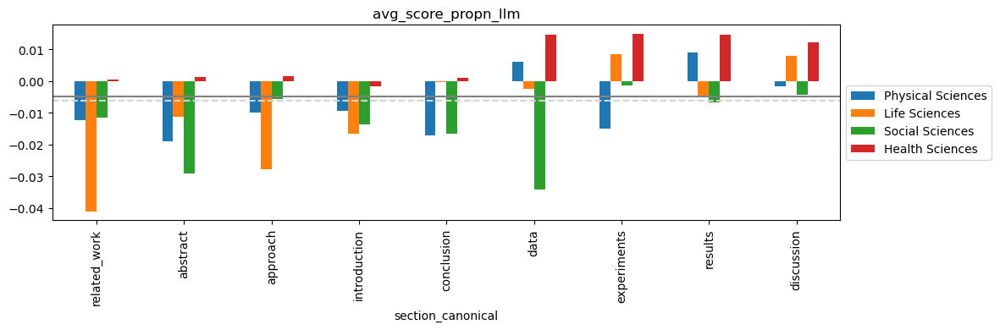

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,817,763,1157,800
approach,588,565,1004,633
conclusion,467,421,971,648
data,179,147,258,117
discussion,713,558,668,527
experiments,215,187,544,212
introduction,752,721,1209,819
related_work,75,88,369,181
results,314,279,452,321


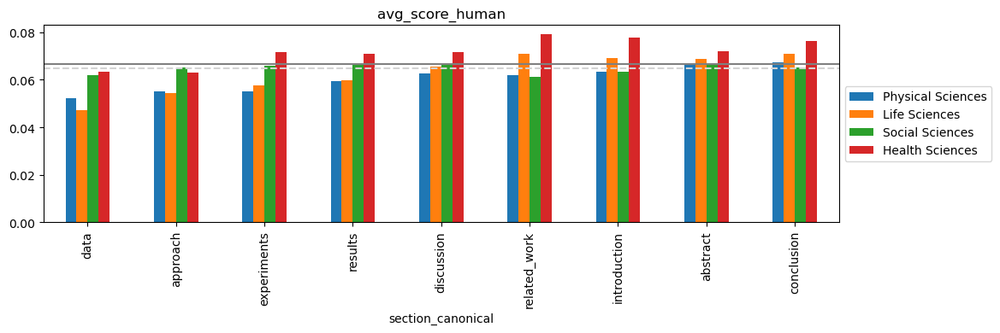

In [108]:
for score in avg_score_cols:
    plot_scores_per_section_ordered(paired_secs, score)

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,999,692,624,218,771,260,816,95,412
Life Sciences,988,686,570,193,645,261,817,119,366
Physical Sciences,1440,1147,1173,313,761,609,1325,458,560
Social Sciences,1026,716,791,141,582,238,886,212,379


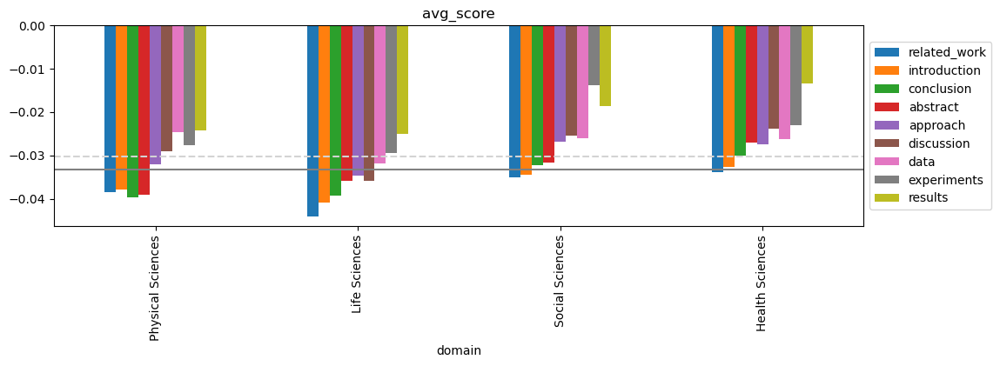

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,987,685,612,210,767,254,814,91,397
Life Sciences,978,677,563,191,641,255,816,116,361
Physical Sciences,1408,1136,1143,289,738,592,1321,444,540
Social Sciences,1002,708,776,136,575,230,881,209,367


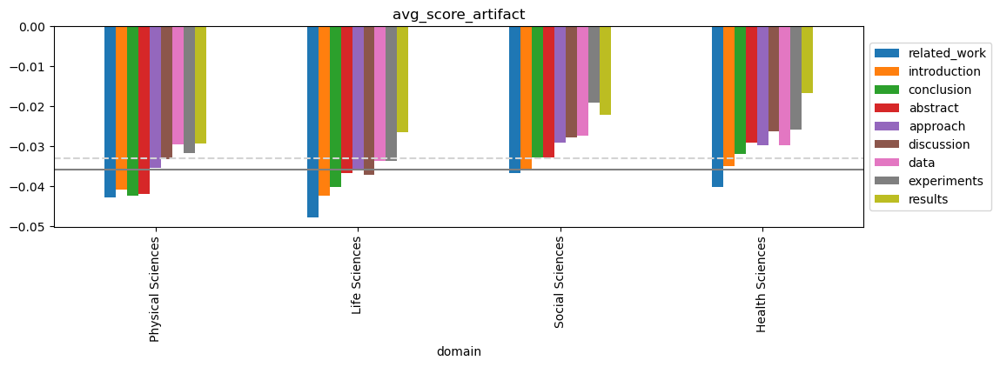

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,198,160,132,34,169,51,189,40,84
Life Sciences,201,179,86,30,141,61,198,34,72
Physical Sciences,564,495,427,115,272,281,561,252,210
Social Sciences,216,204,152,34,170,78,245,66,97


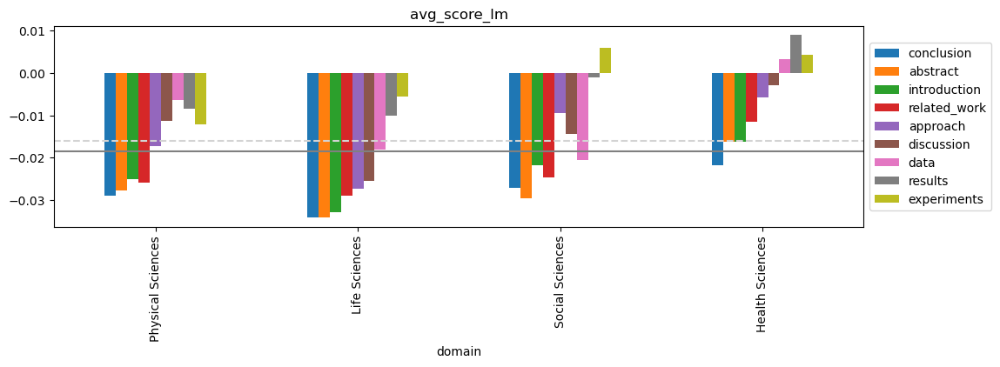

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,182,138,118,28,151,46,177,39,63
Life Sciences,196,175,83,29,138,60,190,33,69
Physical Sciences,558,488,422,112,266,274,559,252,203
Social Sciences,202,197,142,31,159,73,236,65,92


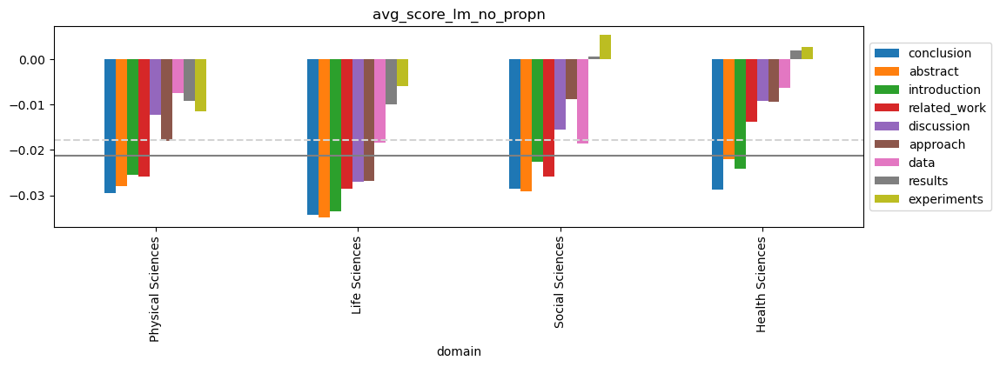

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,93,69,48,14,90,19,100,13,42
Life Sciences,18,25,9,6,20,8,29,6,10
Physical Sciences,39,55,37,10,40,33,64,22,24
Social Sciences,31,42,27,6,33,13,45,11,15


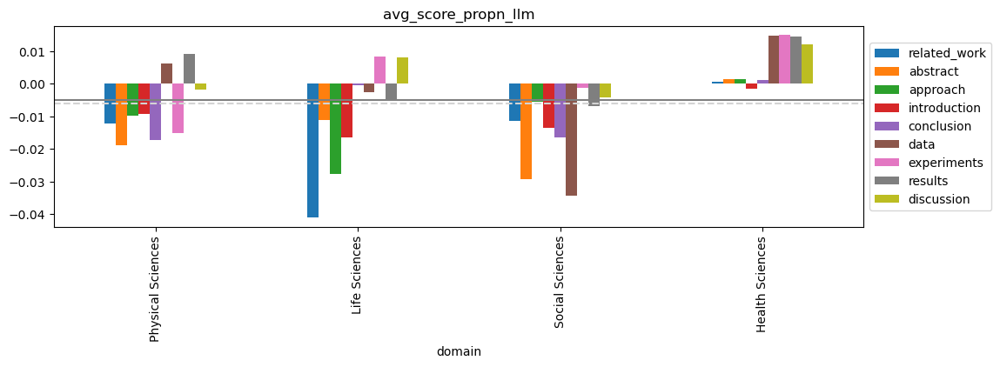

section_canonical,abstract,approach,conclusion,data,discussion,experiments,introduction,related_work,results
domain,,,,,,,,,
Health Sciences,817,588,467,179,713,215,752,75,314
Life Sciences,763,565,421,147,558,187,721,88,279
Physical Sciences,1157,1004,971,258,668,544,1209,369,452
Social Sciences,800,633,648,117,527,212,819,181,321


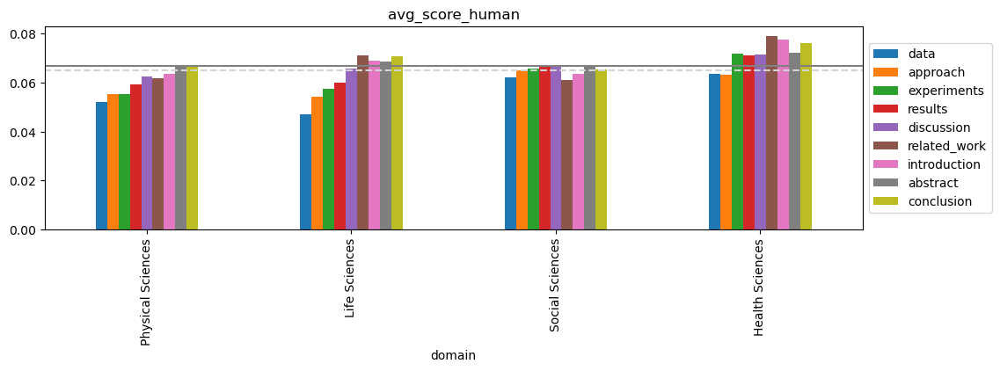

In [110]:
for score in avg_score_cols:
    plot_scores_per_section_ordered(paired_secs, score, unstack_col="section_canonical")

All domains seem to agree on that abstract, conclusion, introduction, and related work are the least anthropomorphized sections. On the contrary, experiments and results seem to be the most anthropomorphized. Other sections seem to have somewhat mixed results.

## Collect the IMRaD subset

In [29]:
imrad_order = ["abstract", "introduction", "approach", "results", "discussion"]
imrad_anthro_order = ["introduction", "abstract", "discussion", "approach", "results"]

In [30]:
imrad_targets = {"abstract", "introduction", "approach", "results", "discussion"}
subset = paired_secs[(paired_secs["section_canonical"].isin(imrad_targets)) & (~paired_secs["avg_score"].isna())]
counts = subset.groupby("paper_id", observed=True)["section_canonical"].nunique()
target_ids = counts[counts == len(imrad_targets)].index
len(target_ids)

858

In [31]:
imrad = subset[subset["paper_id"].isin(target_ids)]

In [32]:
imrad

,paper_id,section_canonical,year,domain,contains_artifact,contains_lm,contains_propn_llm,contains_human,num_artifact,num_lm,...,num_human,num_sents,num_unique_entities,num_unique_entities_nonhum,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
87,W2756381707,abstract,2018,Physical Sciences,True,True,False,True,8,2,...,2,12,9,7,-0.031057,-0.044285,0.021856,0.021856,NaN,0.116225
89,W2756381707,approach,2018,Physical Sciences,True,True,False,True,9,15,...,18,42,9,7,-0.021064,-0.054445,-0.001035,-0.001035,NaN,0.055835
91,W2756381707,discussion,2018,Physical Sciences,True,True,False,True,2,3,...,3,8,4,3,-0.033583,-0.044424,-0.026356,-0.026356,NaN,0.043645
93,W2756381707,introduction,2018,Physical Sciences,True,True,False,True,15,5,...,6,26,14,12,-0.042245,-0.059970,0.010929,0.010929,NaN,0.081750
95,W2756381707,results,2018,Physical Sciences,True,True,False,True,12,22,...,16,50,9,7,-0.004017,-0.016498,0.002790,0.002790,NaN,0.046542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31660,W7135057845,abstract,2026,Social Sciences,True,False,False,False,6,0,...,0,6,3,3,0.025068,0.025068,NaN,NaN,NaN,NaN
31661,W7135057845,approach,2026,Social Sciences,True,False,False,True,11,0,...,3,14,6,4,-0.033873,-0.033873,NaN,NaN,NaN,0.121833
31665,W7135057845,discussion,2026,Social Sciences,True,False,False,True,5,0,...,7,12,5,2,-0.018538,-0.018538,NaN,NaN,NaN,0.091679
31668,W7135057845,introduction,2026,Social Sciences,True,False,False,True,22,0,...,2,24,7,6,-0.012972,-0.012972,NaN,NaN,NaN,0.031202


In [33]:
wide = imrad.pivot(index=["paper_id", "domain"], columns="section_canonical", values="avg_score")[imrad_order]

In [34]:
diffs = wide[imrad_order[1:]].sub(wide["abstract"], axis=0)

In [ ]:
w = wide.reset_index()

# section minus abstract, one column per section, plus domain
diffs = w[imrad_order[1:]].sub(w["abstract"], axis=0)
diffs["domain"] = w["domain"]

# long format: one row per id x section
long = diffs.melt(id_vars="domain", var_name="section", value_name="diff").dropna()

def rank_biserial(d):
    d = d[d != 0]
    rk = stats.rankdata(np.abs(d))
    return (rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum()

rows = []
for (dom, sec), g in long.groupby(["domain", "section"]):
    d = g["diff"].to_numpy()
    if np.all(d == 0):
        continue
    ci = stats.bootstrap((d,), np.median, confidence_level=0.95,
                         n_resamples=5000, random_state=0).confidence_interval
    r_ci = stats.bootstrap((d,), rank_biserial, confidence_level=0.95,
                         n_resamples=5000, random_state=0).confidence_interval
    rows.append({"domain": dom, "section": sec, "n": len(d),
                 "median_diff": np.median(d), "ci_low": ci.low, "ci_high": ci.high,
                 "rank_biserial": rank_biserial(d), "r_ci_low": r_ci.low, "r_ci_high": r_ci.high,
                 "p": stats.wilcoxon(d).pvalue})

res = pd.DataFrame(rows)
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res["section"] = pd.Categorical(res["section"], imrad_order[1:], ordered=True)
res = res.sort_values(["domain", "section"]).set_index(["domain", "section"])
res.round(4)

n  median_diff  ci_low  ci_high  \
domain            section                                           
Health Sciences   introduction  212      -0.0101 -0.0140  -0.0057   
                  approach      212      -0.0000 -0.0037   0.0047   
                  results       212       0.0119  0.0084   0.0163   
                  discussion    212       0.0011 -0.0045   0.0065   
Life Sciences     introduction  171      -0.0061 -0.0094  -0.0024   
                  approach      171       0.0024 -0.0040   0.0090   
                  results       171       0.0088  0.0016   0.0155   
                  discussion    171      -0.0021 -0.0059   0.0036   
Physical Sciences introduction  258      -0.0030 -0.0056   0.0015   
                  approach      258       0.0079  0.0029   0.0102   
                  results       258       0.0122  0.0079   0.0159   
                  discussion    258       0.0074  0.0026   0.0106   
Social Sciences   introduction  217      -0.0025 -0.0062   0.0006   
                  approach      217       0.0044  0.0009   0.0072   
                  results       217       0.0064  0.0036   0.0109   
                  discussion    217       0.0011 -0.0026   0.0060   

                                rank_biserial  r_ci_low  r_ci_high       p  \
domain            section                                                    
Health Sciences   introduction        -0.3510   -0.4905    -0.1963  0.0000   
                  approach             0.0998   -0.0561     0.2541  0.2076   
                  results              0.5000    0.3602     0.6214  0.0000   
                  discussion           0.0615   -0.0923     0.2192  0.4377   
Life Sciences     introduction        -0.3390   -0.4939    -0.1682  0.0001   
                  approach             0.1168   -0.0572     0.2865  0.1852   
                  results              0.3537    0.1816     0.5024  0.0001   
                  discussion           0.0169   -0.1657     0.1872  0.8483   
Physical Sciences introduction        -0.0765   -0.2198     0.0616  0.2866   
                  approach             0.3016    0.1631     0.4317  0.0000   
                  results              0.4093    0.2776     0.5327  0.0000   
                  discussion           0.2470    0.1039     0.3739  0.0006   
Social Sciences   introduction        -0.1770   -0.3236    -0.0313  0.0238   
                  approach             0.1496   -0.0006     0.2974  0.0560   
                  results              0.3030    0.1565     0.4346  0.0001   
                  discussion           0.0369   -0.1125     0.1878  0.6374   

                                p_holm  
domain            section               
Health Sciences   introduction  0.0001  
                  approach      1.0000  
                  results       0.0000  
                  discussion    1.0000  
Life Sciences     introduction  0.0012  
                  approach      1.0000  
                  results       0.0007  
                  discussion    1.0000  
Physical Sciences introduction  1.0000  
                  approach      0.0003  
                  results       0.0000  
                  discussion    0.0053  
Social Sciences   introduction  0.1901  
                  approach      0.3921  
                  results       0.0012  
                  discussion    1.0000

/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


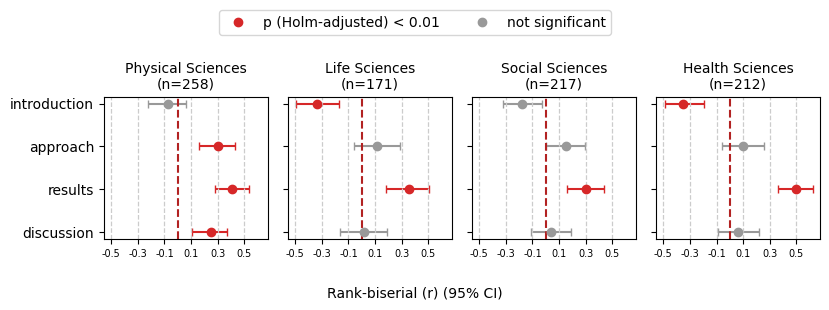

In [143]:
res_plot = res.reset_index()

sig_color = "C3"      # red for significant
ns_color = "0.6"       # grey for not significant
alpha = 0.01

n_per_domain = res_plot.groupby("domain")["n"].first()

fig, axes = plt.subplots(1, len(domain_order), figsize=(2.1 * len(domain_order), 0.39 * len(imrad_order[1:]) + 1),
                         sharey=True, sharex=True)

for ax, sec in zip(axes, domain_order):
    sub = res_plot[res_plot.domain == sec].set_index("section").reindex(imrad_order[1:]).reset_index()
    sub["y"] = range(len(sub))

    for mask, color in [(sub.p_holm < alpha, sig_color), (sub.p_holm >= alpha, ns_color)]:
        g = sub[mask]
        if g.empty:
            continue
        ax.errorbar(g.rank_biserial, g.y,
                    xerr=[g.rank_biserial - g.r_ci_low, g.r_ci_high - g.rank_biserial],
                    fmt="o", color=color, capsize=3, zorder=2)

    vlines = [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5]
    ax.axvline(0, color="firebrick", ls="--")
    ax.set_xticks(vlines)
    ax.set_xticklabels(vlines, fontsize=7)
    for x in vlines:
        ax.axvline(x, color="0.8", ls="--", linewidth="0.9")
    ax.set_yticks(sub.y)
    ax.set_yticklabels(imrad_order[1:])
    #ax.set_yticklabels([f"{dom}\n(n={n_per_domain[dom]})" for dom in domain_order], fontsize=8)
    ax.set_title(f"{sec}\n(n={n_per_domain[sec]})", fontsize=10)

# one shared legend for the whole figure
handles = [plt.Line2D([0], [0], marker="o", color=sig_color, linestyle="", label=f"p (Holm-adjusted) < {alpha}"),
           plt.Line2D([0], [0], marker="o", color=ns_color, linestyle="", label="not significant")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.17))
axes[0].invert_yaxis()
fig.supxlabel("Rank-biserial (r) (95% CI)", fontsize=10)
fig.subplots_adjust(bottom=0.16)
plt.savefig("../figures/forestplot-imrad-rank-biserial.pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()

In [80]:
body_mean = wide[imrad_order[1:]].mean(axis=1)
overall = wide["abstract"] - body_mean
print(overall.mean(), overall.std(), stats.wilcoxon(overall))

-0.0036662979487927915 0.023575522449855627 WilcoxonResult(statistic=147562.0, pvalue=4.3439176975945135e-07)


Test all IMRaD sections against each other

In [86]:
fres = stats.friedmanchisquare(*[wide[c] for c in imrad_order])          # rank-based
fres

FriedmanchisquareResult(statistic=222.56689976689995, pvalue=5.254453296555452e-47)

In [87]:
pg.pairwise_tests(data=subset, dv="avg_score", within="section_canonical", subject="paper_id",
                  parametric=False, padjust="holm")

,Contrast,A,B,Paired,Parametric,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,section_canonical,abstract,approach,True,False,151491.0,two-sided,6.419379e-06,1.925814e-05,holm,-0.148885
1,section_canonical,abstract,discussion,True,False,165052.0,two-sided,8.180323e-03,1.636065e-02,holm,-0.104550
2,section_canonical,abstract,introduction,True,False,142467.0,two-sided,8.673355e-09,3.469342e-08,holm,0.175394
3,section_canonical,abstract,results,True,False,111596.0,two-sided,1.431294e-23,1.288165e-22,holm,-0.381188
4,section_canonical,approach,discussion,True,False,172133.0,two-sided,9.504261e-02,9.504261e-02,holm,0.041071
5,section_canonical,approach,introduction,True,False,116217.0,two-sided,7.264833e-21,5.811866e-20,holm,0.335106
6,section_canonical,approach,results,True,False,137212.0,two-sided,9.263166e-11,4.631583e-10,holm,-0.247610
7,section_canonical,discussion,introduction,True,False,124489.0,two-sided,1.861913e-16,1.117148e-15,holm,0.282866
8,section_canonical,discussion,results,True,False,122602.0,two-sided,2.057086e-17,1.439960e-16,holm,-0.280084
9,section_canonical,introduction,results,True,False,80748.0,two-sided,4.207010e-46,4.207010e-45,holm,-0.558952


In [101]:
from scipy.stats import rankdata

def rank_biserial(x, y):
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]                       # zeros are dropped, as in the Wilcoxon test
    rk = rankdata(np.abs(d))
    return (rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum()

pairs = [("abstract", s) for s in imrad_order[1:]]
out = pd.DataFrame({
    "A": [a for a, _ in pairs], "B": [b for _, b in pairs],
    "rank_biserial": [rank_biserial(wide[a], wide[b]) for a, b in pairs],
    "share_A_higher": [(wide[a] > wide[b]).mean() for a, b in pairs],
})
out

,A,B,rank_biserial,share_A_higher
0,abstract,introduction,0.226796,0.593240
1,abstract,approach,-0.177821,0.440559
2,abstract,results,-0.394341,0.367133
3,abstract,discussion,-0.104222,0.472028


In [88]:
wide.corr(method="spearman")

section_canonical,abstract,introduction,approach,results,discussion
section_canonical,,,,,
abstract,1.000000,0.541235,0.404814,0.374798,0.442777
introduction,0.541235,1.000000,0.431309,0.410241,0.493245
approach,0.404814,0.431309,1.000000,0.400161,0.420882
results,0.374798,0.410241,0.400161,1.000000,0.464843
discussion,0.442777,0.493245,0.420882,0.464843,1.000000


In [89]:
wide.std()

section_canonical
abstract        0.028798
introduction    0.025172
approach        0.028490
results         0.034298
discussion      0.029850
dtype: float64

In [92]:
wide.rank(axis=1).mode()

section_canonical,abstract,introduction,approach,results,discussion
0,1.0,2.0,3.0,5.0,4.0


In [94]:
r = wide.rank(axis=1, method="min", ascending=False)   # 1 = highest score within id
k = wide.shape[1]

# share of ids in which each section gets each rank: rows = sections, columns = ranks
freq = (r.apply(lambda c: c.value_counts(normalize=True))
          .reindex(range(1, k + 1)).fillna(0).T)
freq

,1,2,3,4,5
section_canonical,,,,,
abstract,0.179487,0.181818,0.212121,0.185315,0.241259
introduction,0.081585,0.131702,0.209790,0.297203,0.279720
approach,0.203963,0.222611,0.237762,0.179487,0.156177
results,0.358974,0.229604,0.148019,0.124709,0.138695
discussion,0.175991,0.234266,0.192308,0.213287,0.184149


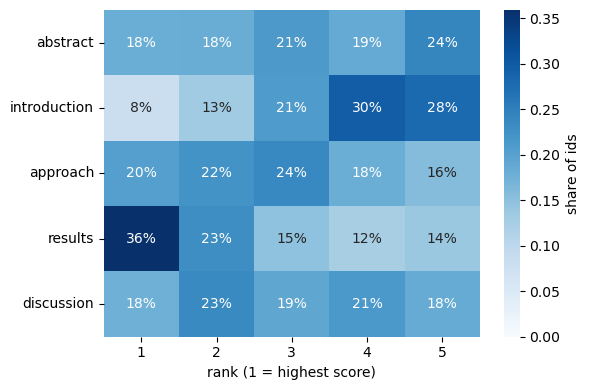

In [95]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(freq, annot=True, fmt=".0%", cmap="Blues", vmin=0, ax=ax,
            cbar_kws={"label": "share of ids"})
ax.set_xlabel("rank (1 = highest score)")
ax.set_ylabel("")
plt.tight_layout()

<Axes: ylabel='section_canonical'>

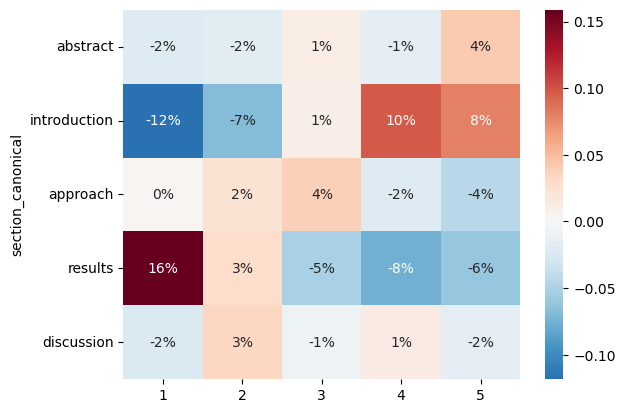

In [96]:
sns.heatmap(freq - 1/k, annot=True, fmt=".0%", cmap="RdBu_r", center=0)

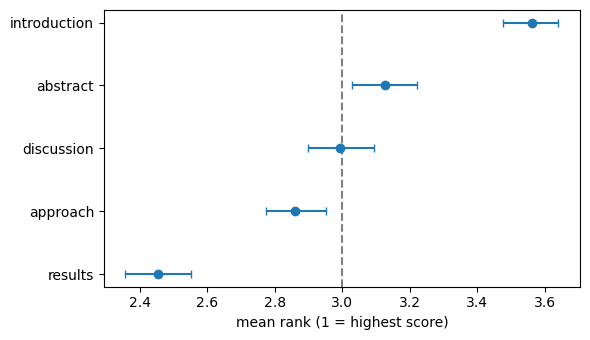

In [97]:
rng = np.random.default_rng(0)
n = len(r)
boot = np.array([r.values[rng.integers(0, n, n)].mean(axis=0) for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
mean_rank = r.mean().values

order = np.argsort(mean_rank)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(mean_rank[order], range(k),
            xerr=[mean_rank[order] - lo[order], hi[order] - mean_rank[order]],
            fmt="o", capsize=3)
ax.axvline((k + 1) / 2, ls="--", c="grey")          # expected mean rank under no differences
ax.set_yticks(range(k)); ax.set_yticklabels(r.columns[order])
ax.set_xlabel("mean rank (1 = highest score)")
plt.tight_layout()

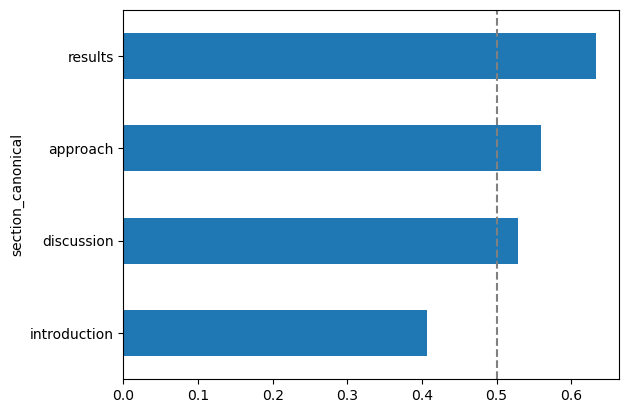

In [99]:
(wide.drop(columns="abstract").gt(wide["abstract"], axis=0).mean()
     .sort_values().plot(kind="barh"))
plt.axvline(0.5, ls="--", c="grey")

In [110]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests

def rank_biserial(d):
    d = np.asarray(d)
    d = d[d != 0]
    rk = rankdata(np.abs(d))
    return (rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum()

rows = []
for sec in imrad_order[1:]:
    d = (wide[sec] - wide["abstract"]).dropna().to_numpy()
    ci = stats.bootstrap((d,), np.median, confidence_level=0.95,
                         n_resamples=5000, random_state=0).confidence_interval
    rows.append({"section": sec, "n": len(d),
                 "median_diff": np.median(d), "ci_low": ci.low, "ci_high": ci.high,
                 "rank_biserial": rank_biserial(d),
                 "p": stats.wilcoxon(d).pvalue})

res = pd.DataFrame(rows).set_index("section")
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res.round(3)

,n,median_diff,ci_low,ci_high,rank_biserial,p,p_holm
section,,,,,,,
introduction,858,-0.005,-0.006,-0.003,-0.227,0.000,0.000
approach,858,0.004,0.002,0.007,0.178,0.000,0.000
results,858,0.010,0.008,0.013,0.394,0.000,0.000
discussion,858,0.002,-0.000,0.005,0.104,0.008,0.008


Text(0, 0.5, 'score: section minus abstract')

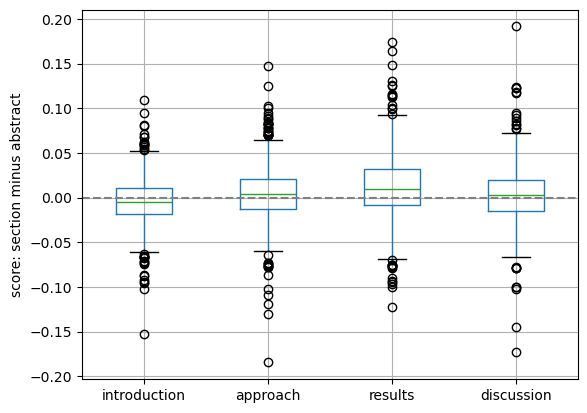

In [107]:
diffs = wide[imrad_order[1:]].sub(wide["abstract"], axis=0)
diffs.boxplot()
plt.axhline(0, color="grey", ls="--")
plt.ylabel("score: section minus abstract")

## More IMRaD inspection

In [44]:
## Try to get the sentence-level data from the paired IMRaD data

index_keys = ["paper_id", "section_canonical"]
mask = df_dedup.set_index(index_keys).index.isin(
    paired_secs.set_index(index_keys).index
)
paired_df = df_dedup[mask].copy()

In [45]:
len(paired_df) / len(df_dedup)

0.5061440017975968

In [48]:
paired_nohum = paired_df[paired_df["entity_type_updated"] != "human"].copy()

In [40]:
imrad.section_canonical.unique()

array(['abstract', 'approach', 'discussion', 'introduction', 'results'],
      dtype=object)

In [41]:
imrad_stats = imrad.groupby("paper_id", observed=True).agg(
    year=("year", "first"),
    domain=("domain", "first")
)
pd.crosstab(imrad_stats.domain, imrad_stats.year, margins=True)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,All
domain,,,,,,,,,,,,
Health Sciences,7,6,10,8,25,22,33,22,27,42,10,212
Life Sciences,3,7,8,11,21,28,25,10,21,32,5,171
Physical Sciences,5,18,18,18,29,23,32,32,29,39,15,258
Social Sciences,2,3,3,13,13,34,27,29,34,50,9,217
All,17,34,39,50,88,107,117,93,111,163,39,858


## Inspect which entities occur in which sections

In [53]:
counts_stripped = pd.crosstab(paired_nohum["section_canonical"], paired_nohum["entity_stripped"])

<Axes: xlabel='entity_stripped', ylabel='section_canonical'>

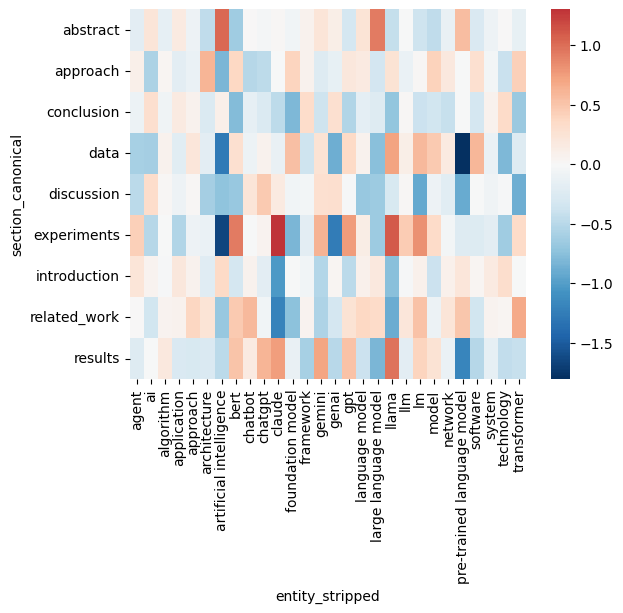

In [55]:
sns.heatmap(standardize(counts_stripped), cmap="RdBu_r", center=0, xticklabels=1)

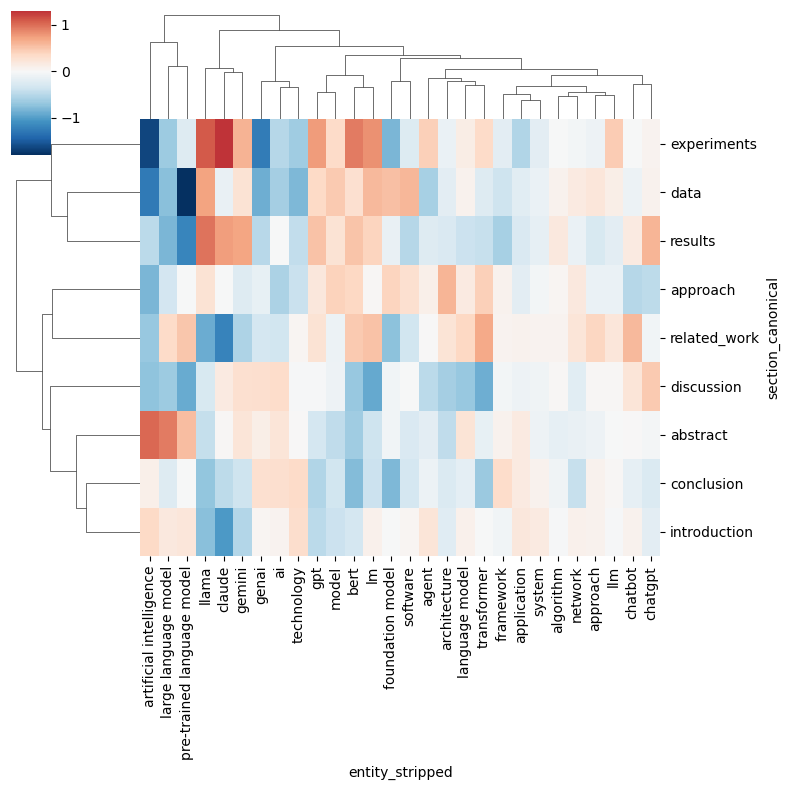

In [57]:
sns.clustermap(standardize(counts_stripped), cmap="RdBu_r", center=0, xticklabels=1, figsize=(8,8))

To avoid the dominance from terms that might occurr multiple times in a section, record the occurrence as boolean.

In [61]:
out = (
    pd.get_dummies(paired_nohum["entity_stripped"])
      .groupby([df["paper_id"], df["section_canonical"]], observed=True)
      .max()
      .reset_index()
)

In [64]:
term_cols = out.columns.difference(["paper_id", "section_canonical"])
mat = out.groupby("section_canonical")[term_cols].sum()

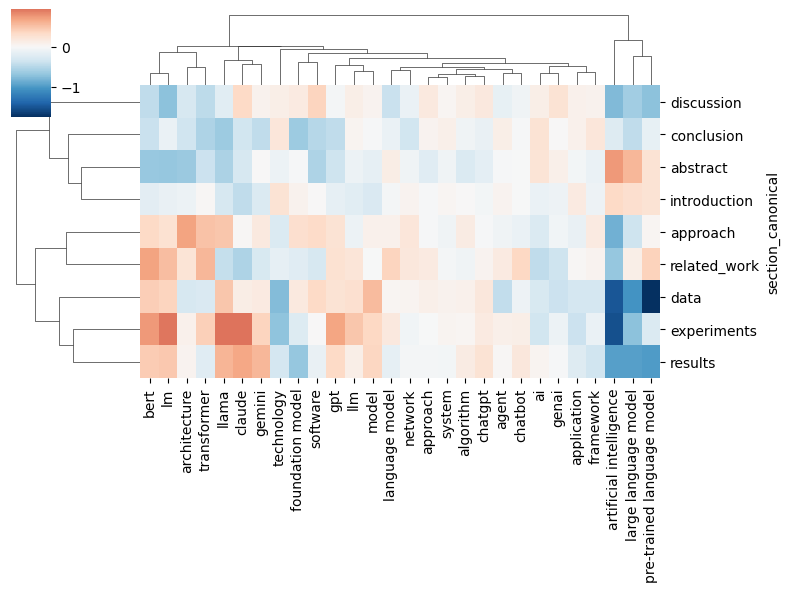

In [76]:
cg = sns.clustermap(standardize(mat), cmap="RdBu_r", center=0, xticklabels=1, figsize=(8,6))
cg.savefig("../figures/term-frequency-fulltexts-clustermap.pdf")

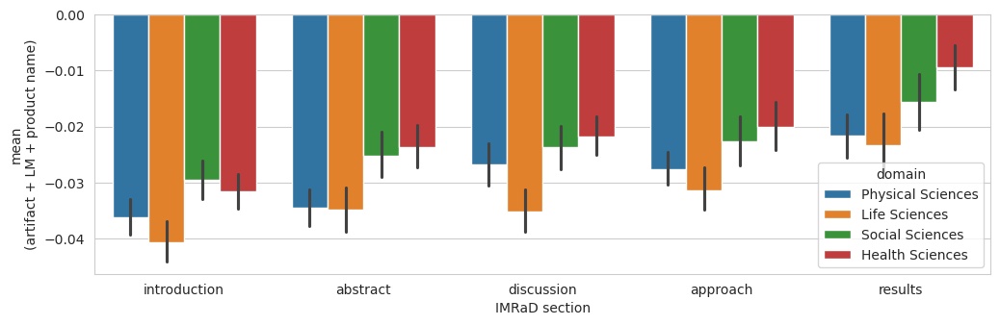

In [48]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(12, 3.5))
    sns.barplot(imrad, x="section_canonical", y="avg_score", hue="domain", hue_order=domain_order, order=imrad_anthro_order, ax=ax)
    ax.set_ylabel("mean\n(artifact + LM + product name)")
    ax.set_xlabel("IMRaD section")
    sns.move_legend(ax, "lower right")
    plt.savefig("../figures/imrad_means.pdf", bbox_inches="tight")
    plt.show()

## Section x domain plots

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,212,171,258,217
approach,212,171,258,217
discussion,212,171,258,217
introduction,212,171,258,217
results,212,171,258,217


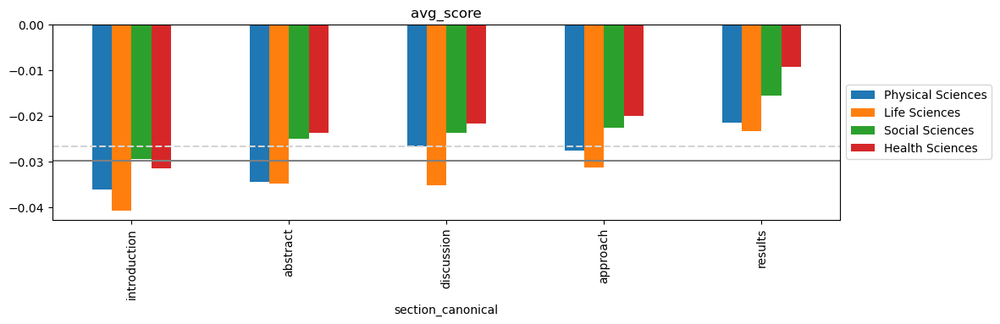

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,208,170,253,208
approach,208,166,253,211
discussion,212,170,246,214
introduction,211,171,257,216
results,201,168,250,208


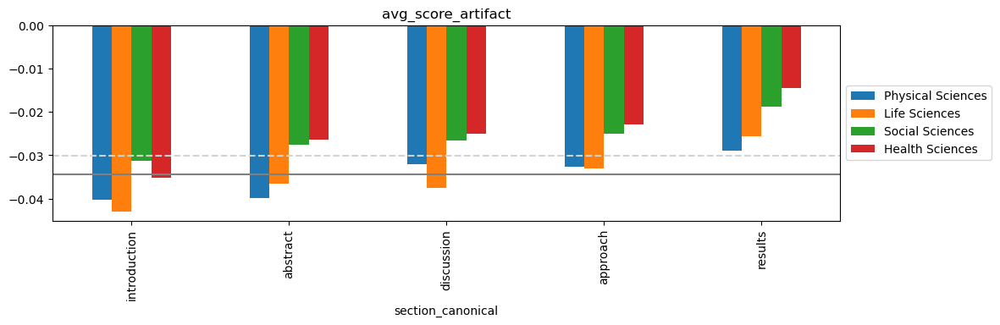

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,64,67,143,75
approach,62,61,137,87
discussion,67,55,126,78
introduction,65,69,142,93
results,57,46,108,65


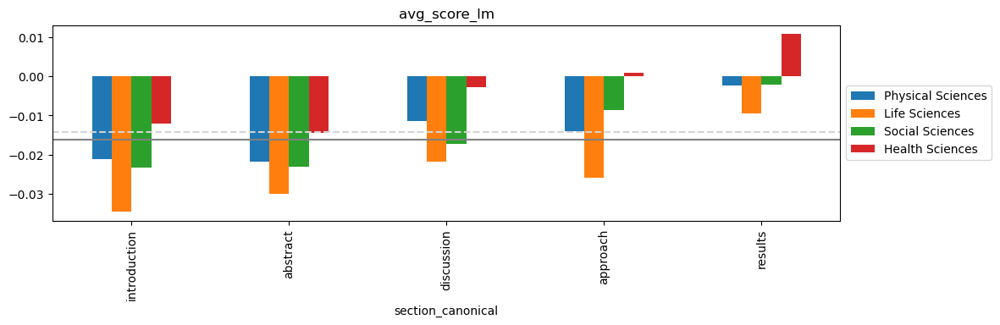

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,60,65,141,70
approach,52,59,134,85
discussion,60,54,124,74
introduction,63,69,142,92
results,41,44,103,64


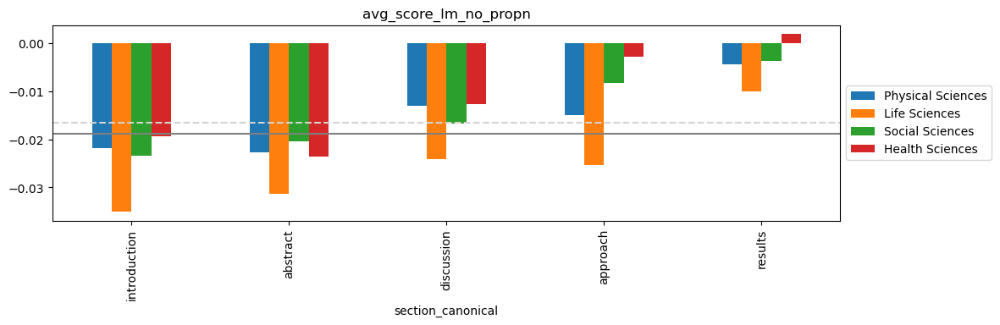

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,32,6,15,9
approach,32,8,20,14
discussion,36,8,16,14
introduction,41,8,19,14
results,28,5,16,6


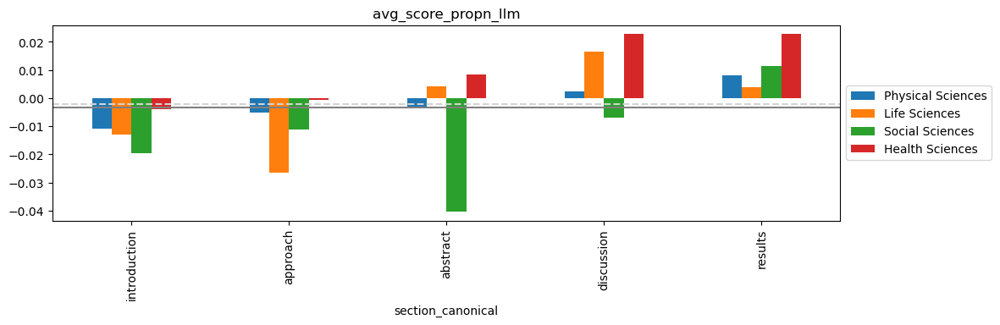

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,170,146,225,172
approach,187,149,228,197
discussion,202,151,232,198
introduction,203,157,245,203
results,157,138,209,183


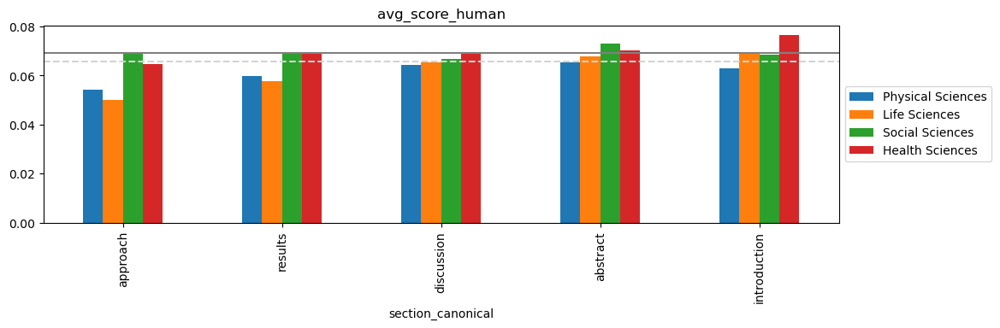

In [165]:
for score in avg_score_cols:
    plot_scores_per_section_ordered(imrad, score)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
section_canonical,,,,
abstract,212,171,258,217
approach,212,171,258,217
discussion,212,171,258,217
introduction,212,171,258,217
results,212,171,258,217


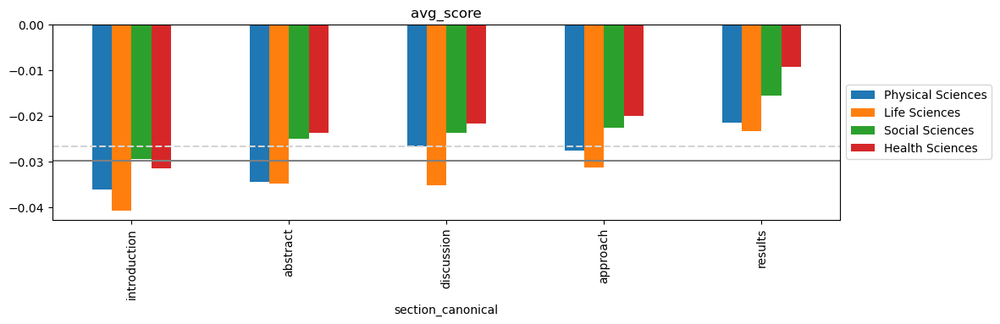

In [205]:
plot_scores_per_section_ordered(imrad, "avg_score")

section_canonical,abstract,approach,discussion,introduction,results
domain,,,,,
Health Sciences,212,212,212,212,212
Life Sciences,171,171,171,171,171
Physical Sciences,258,258,258,258,258
Social Sciences,217,217,217,217,217


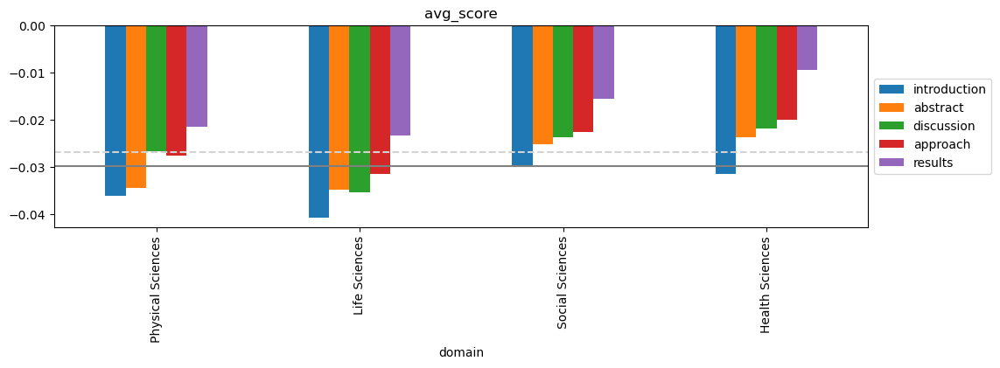

In [206]:
plot_scores_per_section_ordered(imrad, "avg_score", unstack_col="section_canonical")

## Inspect the IMRaD data

<Axes: xlabel='section_canonical', ylabel='avg_score'>

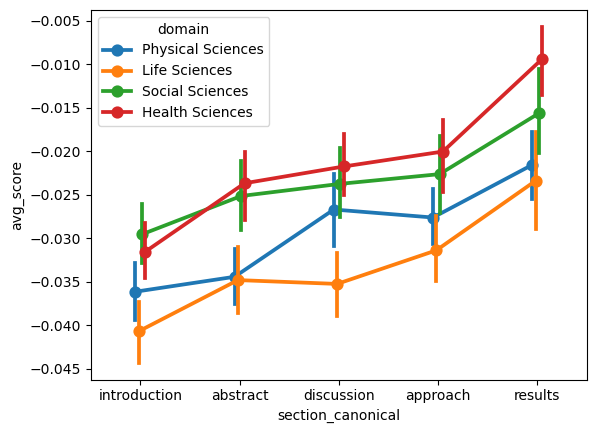

In [20]:
sns.pointplot(imrad, x="section_canonical", y="avg_score", hue="domain", dodge=True, order=imrad_anthro_order, hue_order=domain_order)

In [21]:
pg.normality(imrad, dv='avg_score', group='domain')      # Shapiro-Wilk per domain

,W,pval,normal
domain,,,
Physical Sciences,0.943085,7.240911e-22,False
Life Sciences,0.923932,2.304381e-20,False
Social Sciences,0.942800,4.791220e-20,False
Health Sciences,0.977606,1.010504e-11,False


In [22]:
pg.homoscedasticity(imrad, dv='avg_score', group='domain')  # Levene's test

,W,pval,equal_var
levene,3.11748,0.025058,False


In [25]:
pg.sphericity(imrad, dv='avg_score', within='section_canonical', subject='paper_id')  # Mauchly's test

SpherResults(spher=False, W=0.8620259272177659, chi2=127.00365329826387, dof=9, pval=4.897963448019076e-23)

In [26]:
pg.mixed_anova(data=imrad, dv="avg_score", within="section_canonical",
               subject="paper_id", between="domain")

,Source,SS,DF1,DF2,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,domain,0.087104,3,854,0.029035,12.958695,2.772766e-08,NaN,0.043540,NaN,NaN,NaN,NaN
1,section_canonical,0.131249,4,3416,0.032812,65.494965,1.889930e-53,4.708609e-50,0.071229,0.93455,False,0.862026,4.897963e-23
2,Interaction,0.009259,12,3416,0.000772,1.540170,1.024430e-01,NaN,0.005381,NaN,NaN,NaN,NaN


In [28]:
pg.pairwise_tests(data=imrad, dv='avg_score', between='domain',
                   padjust='holm', effsize='hedges')

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,domain,Health Sciences,Life Sciences,False,True,8.990107,1843.656504,two-sided,5.966785e-19,3.580071e-18,holm,6.109e+15,0.412134
1,domain,Health Sciences,Physical Sciences,False,True,6.612486,2276.193183,two-sided,4.693911e-11,1.877564e-10,holm,1.047e+08,0.273524
2,domain,Health Sciences,Social Sciences,False,True,1.580600,2136.289057,two-sided,1.141177e-01,1.141177e-01,holm,0.168,0.068173
3,domain,Life Sciences,Physical Sciences,False,True,-3.004563,1879.860145,two-sided,2.694785e-03,5.389569e-03,holm,4.341,-0.131362
4,domain,Life Sciences,Social Sciences,False,True,-7.189905,1901.933546,two-sided,9.277617e-13,4.638809e-12,holm,5.143e+09,-0.324765
5,domain,Physical Sciences,Social Sciences,False,True,-4.730394,2250.809186,two-sided,2.379680e-06,7.139039e-06,holm,2970.627,-0.195812


In [29]:
pg.pairwise_tests(data=imrad, dv='avg_score', within='section_canonical', subject='paper_id',
                   padjust='holm', effsize='hedges')

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,section_canonical,abstract,approach,True,True,-4.034636,857.0,two-sided,5.957142e-05,1.787143e-04,holm,118.705,-0.148885
1,section_canonical,abstract,discussion,True,True,-2.912475,857.0,two-sided,3.678877e-03,7.357754e-03,holm,2.579,-0.104550
2,section_canonical,abstract,introduction,True,True,5.395648,857.0,two-sided,8.839628e-08,3.535851e-07,holm,6.034e+04,0.175394
3,section_canonical,abstract,results,True,True,-10.164676,857.0,two-sided,5.398270e-23,4.858443e-22,holm,5.007e+19,-0.381188
4,section_canonical,approach,discussion,True,True,1.087699,857.0,two-sided,2.770340e-01,2.770340e-01,holm,0.069,0.041071
5,section_canonical,approach,introduction,True,True,9.006077,857.0,two-sided,1.359520e-18,1.087616e-17,holm,2.281e+15,0.335106
6,section_canonical,approach,results,True,True,-6.653969,857.0,two-sided,5.084387e-11,2.542193e-10,holm,8.464e+07,-0.247610
7,section_canonical,discussion,introduction,True,True,8.042001,857.0,two-sided,2.929035e-15,2.050325e-14,holm,1.2e+12,0.282866
8,section_canonical,discussion,results,True,True,-7.504928,857.0,two-sided,1.539739e-13,9.238433e-13,holm,2.46e+10,-0.280084
9,section_canonical,introduction,results,True,True,-14.708160,857.0,two-sided,7.838483e-44,7.838483e-43,holm,2.21e+40,-0.558952


In [51]:
# Domain differences (collapsing across sections, or per section)
pg.kruskal(data=imrad, dv='avg_score', between='domain')

,Source,ddof1,H,p_unc
Kruskal,domain,3,131.368902,2.741957e-28


In [52]:
# Pairwise follow-up
pg.pairwise_tests(data=imrad, dv='avg_score', between='domain',
                   parametric=False, padjust='holm', effsize="CLES")

,Contrast,A,B,Paired,Parametric,U_val,alternative,p_unc,p_corr,p_adjust,CLES
0,domain,Health Sciences,Life Sciences,False,False,576777.0,two-sided,8.942310e-25,5.365386e-24,holm,0.636408
1,domain,Health Sciences,Physical Sciences,False,False,810909.0,two-sided,7.725797e-15,3.090319e-14,holm,0.593030
2,domain,Health Sciences,Social Sciences,False,False,613060.0,two-sided,8.041294e-03,8.041294e-03,holm,0.533049
3,domain,Life Sciences,Physical Sciences,False,False,501816.0,two-sided,4.064953e-04,8.129906e-04,holm,0.454976
4,domain,Life Sciences,Social Sciences,False,False,368011.0,two-sided,5.165330e-15,2.582665e-14,holm,0.396703
5,domain,Physical Sciences,Social Sciences,False,False,617113.0,two-sided,6.747963e-07,2.024389e-06,holm,0.440905


In [59]:
pg.pairwise_tests(data=imrad, dv='avg_score', between='domain',
                   parametric=False, padjust='holm')

,Contrast,A,B,Paired,Parametric,U_val,alternative,p_unc,p_corr,p_adjust,hedges
0,domain,Health Sciences,Life Sciences,False,False,576777.0,two-sided,8.942310e-25,5.365386e-24,holm,0.412134
1,domain,Health Sciences,Physical Sciences,False,False,810909.0,two-sided,7.725797e-15,3.090319e-14,holm,0.273524
2,domain,Health Sciences,Social Sciences,False,False,613060.0,two-sided,8.041294e-03,8.041294e-03,holm,0.068173
3,domain,Life Sciences,Physical Sciences,False,False,501816.0,two-sided,4.064953e-04,8.129906e-04,holm,-0.131362
4,domain,Life Sciences,Social Sciences,False,False,368011.0,two-sided,5.165330e-15,2.582665e-14,holm,-0.324765
5,domain,Physical Sciences,Social Sciences,False,False,617113.0,two-sided,6.747963e-07,2.024389e-06,holm,-0.195812


In [67]:
for domain in domain_order:
    print(domain)
    sub = pg.pairwise_tests(data=imrad[imrad["domain"] == domain], dv='avg_score', within='section_canonical', subject="paper_id",
                   parametric=False, padjust='holm', effsize="CLES")
    sub["diff"] = sub["CLES"] - 0.5
    sub["abs_diff"] = abs(sub["diff"])
    display(sub.sort_values("abs_diff", ascending=False))

Physical Sciences


,Contrast,A,B,Paired,Parametric,W_val,alternative,p_unc,p_corr,p_adjust,CLES,diff,abs_diff
9,section_canonical,introduction,results,True,False,8370.0,two-sided,3.727587e-12,3.727587e-11,holm,0.359158,-0.140842,0.140842
3,section_canonical,abstract,results,True,False,9868.0,two-sided,1.208137e-08,1.087323e-07,holm,0.375774,-0.124226,0.124226
5,section_canonical,approach,introduction,True,False,10973.0,two-sided,1.774288e-06,1.242002e-05,holm,0.608227,0.108227,0.108227
7,section_canonical,discussion,introduction,True,False,10642.0,two-sided,4.338944e-07,3.471155e-06,holm,0.588997,0.088997,0.088997
0,section_canonical,abstract,approach,True,False,11667.0,two-sided,2.679487e-05,1.607692e-04,holm,0.412640,-0.087360,0.087360
1,section_canonical,abstract,discussion,True,False,12580.0,two-sided,5.857075e-04,2.928537e-03,holm,0.428370,-0.071630,0.071630
8,section_canonical,discussion,results,True,False,13381.0,two-sided,5.596649e-03,2.238660e-02,holm,0.446623,-0.053377,0.053377
6,section_canonical,approach,results,True,False,13527.0,two-sided,8.077034e-03,2.423110e-02,holm,0.448696,-0.051304,0.051304
2,section_canonical,abstract,introduction,True,False,15427.0,two-sided,2.867851e-01,5.735702e-01,holm,0.514557,0.014557,0.014557
4,section_canonical,approach,discussion,True,False,16628.0,two-sided,9.488279e-01,9.488279e-01,holm,0.508067,0.008067,0.008067


Life Sciences


,Contrast,A,B,Paired,Parametric,W_val,alternative,p_unc,p_corr,p_adjust,CLES,diff,abs_diff
9,section_canonical,introduction,results,True,False,3397.0,two-sided,1.054380e-09,1.054380e-08,holm,0.345405,-0.154595,0.154595
5,section_canonical,approach,introduction,True,False,4508.0,two-sided,1.147404e-05,1.032664e-04,holm,0.620977,0.120977,0.120977
3,section_canonical,abstract,results,True,False,4752.0,two-sided,6.046098e-05,4.232269e-04,holm,0.405048,-0.094952,0.094952
8,section_canonical,discussion,results,True,False,4537.0,two-sided,1.407936e-05,1.126349e-04,holm,0.409596,-0.090404,0.090404
7,section_canonical,discussion,introduction,True,False,5475.0,two-sided,3.781318e-03,1.890659e-02,holm,0.575664,0.075664,0.075664
2,section_canonical,abstract,introduction,True,False,4860.0,two-sided,1.208352e-04,7.250111e-04,holm,0.564174,0.064174,0.064174
6,section_canonical,approach,results,True,False,5765.0,two-sided,1.434302e-02,5.737208e-02,holm,0.440614,-0.059386,0.059386
0,section_canonical,abstract,approach,True,False,6494.0,two-sided,1.854538e-01,3.709077e-01,holm,0.450669,-0.049331,0.049331
4,section_canonical,approach,discussion,True,False,6312.0,two-sided,1.085236e-01,3.255709e-01,holm,0.540953,0.040953,0.040953
1,section_canonical,abstract,discussion,True,False,7229.0,two-sided,8.489283e-01,8.489283e-01,holm,0.488903,-0.011097,0.011097


Social Sciences


,Contrast,A,B,Paired,Parametric,W_val,alternative,p_unc,p_corr,p_adjust,CLES,diff,abs_diff
9,section_canonical,introduction,results,True,False,6068.0,two-sided,5.024385e-10,5.024385e-09,holm,0.373399,-0.126601,0.126601
3,section_canonical,abstract,results,True,False,8243.0,two-sided,1.090794e-04,7.635555e-04,holm,0.416743,-0.083257,0.083257
8,section_canonical,discussion,results,True,False,8179.0,two-sided,8.196845e-05,6.557476e-04,holm,0.427849,-0.072151,0.072151
5,section_canonical,approach,introduction,True,False,7954.0,two-sided,2.895171e-05,2.605654e-04,holm,0.570961,0.070961,0.070961
6,section_canonical,approach,results,True,False,9506.0,two-sided,1.222855e-02,6.114273e-02,holm,0.440336,-0.059664,0.059664
7,section_canonical,discussion,introduction,True,False,8904.0,two-sided,1.601638e-03,9.609827e-03,holm,0.557625,0.057625,0.057625
2,section_canonical,abstract,introduction,True,False,9733.0,two-sided,2.380069e-02,9.520278e-02,holm,0.543651,0.043651,0.043651
0,section_canonical,abstract,approach,True,False,10057.0,two-sided,5.607811e-02,1.682343e-01,holm,0.473316,-0.026684,0.026684
1,section_canonical,abstract,discussion,True,False,11390.0,two-sided,6.377426e-01,6.377426e-01,holm,0.487078,-0.012922,0.012922
4,section_canonical,approach,discussion,True,False,10695.0,two-sided,2.219266e-01,4.438531e-01,holm,0.512391,0.012391,0.012391


Health Sciences


,Contrast,A,B,Paired,Parametric,W_val,alternative,p_unc,p_corr,p_adjust,CLES,diff,abs_diff
9,section_canonical,introduction,results,True,False,3176.0,two-sided,1.167381e-19,1.167381e-18,holm,0.282062,-0.217938,0.217938
3,section_canonical,abstract,results,True,False,5645.0,two-sided,2.771400e-10,2.494260e-09,holm,0.376268,-0.123732,0.123732
8,section_canonical,discussion,results,True,False,5829.0,two-sided,1.026142e-09,8.209138e-09,holm,0.378627,-0.121373,0.121373
7,section_canonical,discussion,introduction,True,False,6600.0,two-sided,1.579088e-07,9.474527e-07,holm,0.615032,0.115032,0.115032
6,section_canonical,approach,results,True,False,6605.0,two-sided,1.627672e-07,9.474527e-07,holm,0.384990,-0.115010,0.115010
5,section_canonical,approach,introduction,True,False,6482.0,two-sided,7.656198e-08,5.359339e-07,holm,0.604931,0.104931,0.104931
2,section_canonical,abstract,introduction,True,False,7327.0,two-sided,9.419124e-06,3.767649e-05,holm,0.593361,0.093361,0.093361
0,section_canonical,abstract,approach,True,False,10162.0,two-sided,2.077593e-01,6.232778e-01,holm,0.490188,-0.009812,0.009812
1,section_canonical,abstract,discussion,True,False,10595.0,two-sided,4.380252e-01,8.760503e-01,holm,0.492613,-0.007387,0.007387
4,section_canonical,approach,discussion,True,False,10629.0,two-sided,4.608119e-01,8.760503e-01,holm,0.495061,-0.004939,0.004939


In [71]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests

results = []

for d1, d2 in combinations(domain_order, 2):
    x = imrad.loc[imrad['domain'] == d1, 'avg_score']
    y = imrad.loc[imrad['domain'] == d2, 'avg_score']
    res = pg.mwu(x, y)
    res['A'], res['B'] = d1, d2
    results.append(res)

pairwise_rbc = pd.concat(results, ignore_index=True)
pairwise_rbc['p_holm'] = multipletests(pairwise_rbc['p_val'], method='holm')[1]

pairwise_rbc

,U_val,alternative,p_val,RBC,CLES,A,B,p_holm
0,601134.0,two-sided,4.064953e-04,0.090048,0.545024,Physical Sciences,Life Sciences,8.129906e-04
1,617113.0,two-sided,6.747963e-07,-0.118190,0.440905,Physical Sciences,Social Sciences,2.024389e-06
2,556491.0,two-sided,7.725797e-15,-0.186060,0.406970,Physical Sciences,Health Sciences,3.090319e-14
3,368011.0,two-sided,5.165330e-15,-0.206595,0.396703,Life Sciences,Social Sciences,2.582665e-14
4,329523.0,two-sided,8.942310e-25,-0.272817,0.363592,Life Sciences,Health Sciences,5.365386e-24
5,537040.0,two-sided,8.041294e-03,-0.066099,0.466951,Social Sciences,Health Sciences,8.041294e-03


In [32]:
# Section differences (repeated measures)
pg.friedman(data=imrad, dv='avg_score', within='section_canonical', subject='paper_id')

,Source,W,ddof1,Q,p_unc
Friedman,section_canonical,0.06485,4,222.5669,5.254453e-47


In [64]:
# Are there differences between-section scores for different entity types?
for score in avg_score_cols:
    print(score)
    results = []
    for domain in domain_order:
        sub = imrad[imrad["domain"] == domain]
        res = pg.friedman(sub, dv=score, within="section_canonical", subject="paper_id")
        results.append(res)
    results_df = pd.concat(results, keys=domain_order)
    results_df["significant"] = results_df["p_unc"] < 0.05
    display(results_df)
    print("="*60)

avg_score


,,Source,W,ddof1,Q,p_unc,significant
Physical Sciences,Friedman,section_canonical,0.063007,4,65.023256,2.544339e-13,True
Life Sciences,Friedman,section_canonical,0.057919,4,39.616374,5.195746e-08,True
Social Sciences,Friedman,section_canonical,0.043530,4,37.784332,1.241420e-07,True
Health Sciences,Friedman,section_canonical,0.122268,4,103.683019,1.616195e-21,True


avg_score_artifact


,,Source,W,ddof1,Q,p_unc,significant
Physical Sciences,Friedman,section_canonical,0.043800,4,40.295652,3.759898e-08,True
Life Sciences,Friedman,section_canonical,0.061869,4,40.338650,3.683667e-08,True
Social Sciences,Friedman,section_canonical,0.032742,4,25.931313,3.266993e-05,True
Health Sciences,Friedman,section_canonical,0.114624,4,89.865306,1.406430e-18,True


avg_score_lm


,,Source,W,ddof1,Q,p_unc,significant
Physical Sciences,Friedman,section_canonical,0.050794,4,17.066667,0.001876,True
Life Sciences,Friedman,section_canonical,0.104000,4,14.560000,0.005706,True
Social Sciences,Friedman,section_canonical,0.045211,4,7.414634,0.115533,False
Health Sciences,Friedman,section_canonical,0.159168,4,29.286957,0.000007,True


... (2 outputs left out)

avg_score_propn_llm


,,Source,W,ddof1,Q,p_unc,significant
Physical Sciences,Friedman,section_canonical,0.1120,4,2.24,0.691713,False
Life Sciences,Friedman,section_canonical,0.3000,4,2.40,0.662627,False
Social Sciences,Friedman,section_canonical,0.3000,4,2.40,0.662627,False
Health Sciences,Friedman,section_canonical,0.0495,4,3.96,0.411446,False


avg_score_human


,,Source,W,ddof1,Q,p_unc,significant
Physical Sciences,Friedman,section_canonical,0.025609,4,18.233708,0.001111,True
Life Sciences,Friedman,section_canonical,0.068907,4,30.594595,0.000004,True
Social Sciences,Friedman,section_canonical,0.007307,4,4.413245,0.352959,False
Health Sciences,Friedman,section_canonical,0.026849,4,13.209756,0.010295,True


## Inspect the selected sections

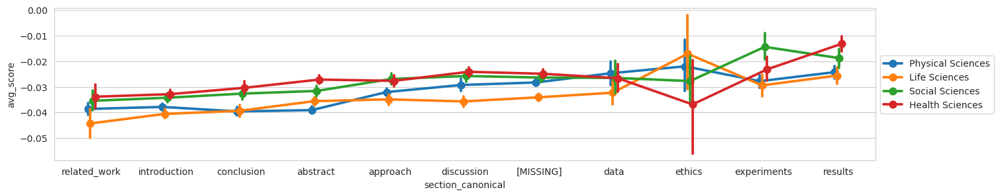

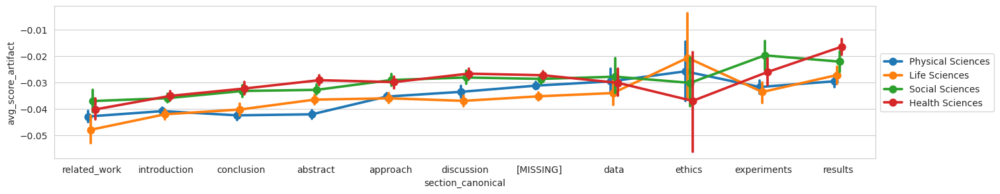

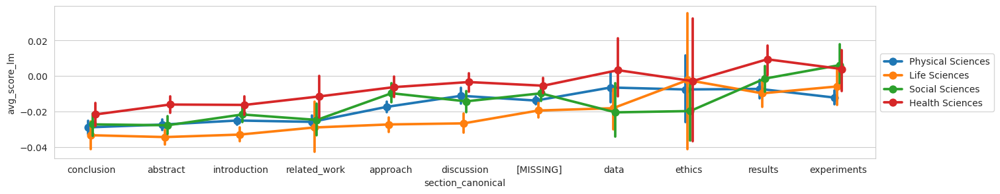

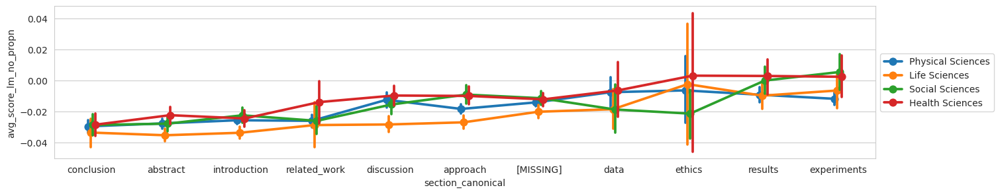

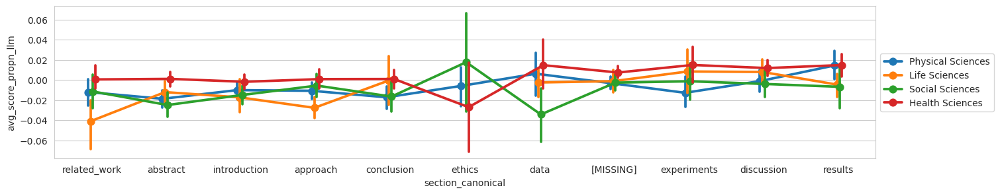

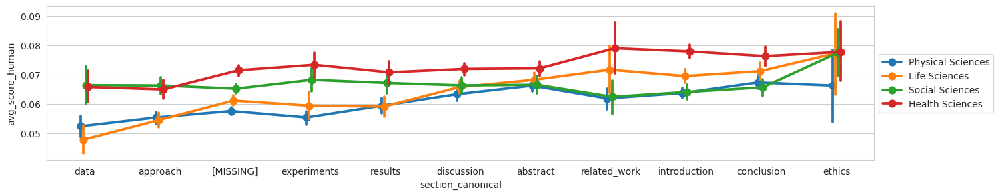

In [48]:
for score in avg_score_cols:
    sec_sort_order = (secs_filtered.groupby(["domain", "section_canonical"], observed=True)
        [score].mean().unstack("domain").mean(axis=1).sort_values().index)
    with sns.axes_style("whitegrid"):
        fig, ax = plt.subplots(figsize=(16, 3))
        sns.pointplot(secs_filtered, x="section_canonical", y=score, hue="domain", dodge=True, order=sec_sort_order, hue_order=domain_order, ax=ax)
        ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
        plt.show()

## Inspect the full data

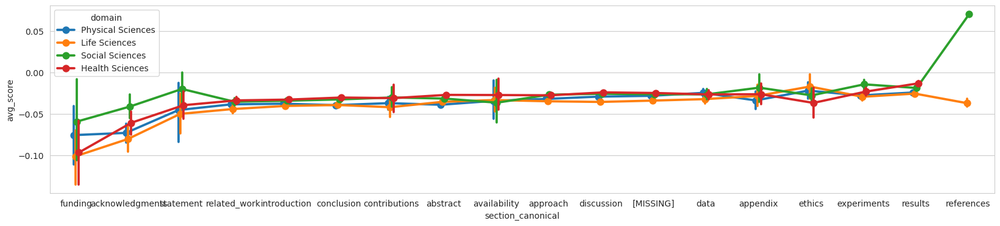

In [43]:
with sns.axes_style("whitegrid"):
    sec_sort_order_all = (secs.groupby(["domain", "section_canonical"], observed=True)
        ["avg_score"].mean().unstack("domain").mean(axis=1).sort_values().index)
    fig, ax = plt.subplots(figsize=(20, 4))
    sns.pointplot(secs, x="section_canonical", y="avg_score", hue="domain", dodge=True, order=sec_sort_order_all, hue_order=domain_order, ax=ax)
    plt.show()

## Significance of the differences in abstracts and full-texts

In [177]:
from scipy.stats import ttest_rel, shapiro, wilcoxon, rankdata

In [178]:
def desc_effect_size(r):
    if abs(r) > 0.5:
        note = "large"
    elif abs(r) > 0.3:
        note = "medium"
    elif abs(r) > 0.1:
        note = "small"
    else:
        note = "negligible"
    return note

In [179]:
def rank_biserial(x, y):
    diff = x - y
    ranks = rankdata(np.abs(diff), nan_policy="omit")
    W_pos = ranks[diff > 0].sum()
    W_neg = ranks[diff < 0].sum()

    # rank-biserial correlation: (W+ - W-) / total rank sum
    r = (W_pos - W_neg) / (W_pos + W_neg)
    return r

def bootstrap_rank_biserial_ci(x, y, n_boot=2000, ci=95, random_state=0):
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)
    rng = np.random.default_rng(random_state)

    boot_rs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)  # resample pairs jointly, keeps pairing intact
        boot_rs[i] = rank_biserial(x[idx], y[idx])

    lower = np.nanpercentile(boot_rs, (100 - ci) / 2)
    upper = np.nanpercentile(boot_rs, 100 - (100 - ci) / 2)
    point = rank_biserial(x, y)
    return point, lower, upper

In [180]:
def wilcoxon_with_rank_biserial(x, y, name, n_boot=2000):
    assert len(x) == len(y)
    res = wilcoxon(x, y, nan_policy="omit")
    if res.pvalue > 0.05:
        print("p-value is not significant")
        return
    try:
        zstat = res.zstatistic
    except AttributeError:
        zstat = None
    if zstat:
        print(res, f"zstatistic={zstat}")
        n = (x != y).sum()
        r_rank_biserial = res.zstatistic / np.sqrt(n)
        print("z-based:", r_rank_biserial)
    else:
        print(res)

    r, ci_low, ci_high = bootstrap_rank_biserial_ci(x, y, n_boot=n_boot)
    print(f"r_rb = {r:.3f} ({desc_effect_size(r)}), 95% CI [{ci_low:.3f}, {ci_high:.3f}]")

In [165]:
for domain in paired.domain.unique():
    print(domain.upper())
    subset = paired[paired["domain"] == domain]
    for ent in ("artifact", "lm_no_propn", "lm", "propn_llm", "human"):
        print(f"Results for {ent}:")
        a = subset[f"avg_score_{ent}_abs"]
        b = subset[f"avg_score_{ent}_body"]
        wilcoxon_with_rank_biserial(a, b, domain)
        print()
    print("="*20)
    print()

SOCIAL SCIENCES
Results for artifact:
WilcoxonResult(statistic=245551.0, pvalue=0.009554901282709489)
r_rb = -0.093 (negligible), 95% CI [-0.158, -0.022]

Results for lm_no_propn:
WilcoxonResult(statistic=4265.0, pvalue=3.737619477896409e-13)
r_rb = -0.588 (large), 95% CI [-0.706, -0.468]

Results for lm:
WilcoxonResult(statistic=4771.0, pvalue=9.304157053086978e-15)
r_rb = -0.604 (large), 95% CI [-0.718, -0.485]

Results for propn_llm:
WilcoxonResult(statistic=104.0, pvalue=0.0038599325343966484)
r_rb = -0.581 (large), 95% CI [-0.883, -0.202]

Results for human:
p-value is not significant


PHYSICAL SCIENCES
Results for artifact:
WilcoxonResult(statistic=333698.0, pvalue=3.2048424977662726e-30)
r_rb = -0.349 (medium), 95% CI [-0.404, -0.293]

Results for lm_no_propn:
WilcoxonResult(statistic=45084.0, pvalue=5.930813752301349e-18)
r_rb = -0.422 (medium), 95% CI [-0.505, -0.332]

Results for lm:
WilcoxonResult(statistic=44599.0, pvalue=1.3417131053498162e-19)
r_rb = -0.440 (medium), 95%

## Temporal changes

Differences between years are inspected to see if the conclusions drawn from this data sample are similar than with the other corpus including only abstracts in a much larger scale.

In [143]:
paired_secs.columns

Index(['paper_id', 'section_canonical', 'year', 'domain', 'contains_artifact',
       'contains_lm', 'contains_propn_llm', 'contains_human', 'num_artifact',
       'num_lm', 'num_propn_llm', 'num_human', 'num_sents',
       'num_unique_entities', 'num_unique_entities_nonhum', 'avg_score',
       'avg_score_artifact', 'avg_score_lm', 'avg_score_lm_no_propn',
       'avg_score_propn_llm', 'avg_score_human'],
      dtype='object')

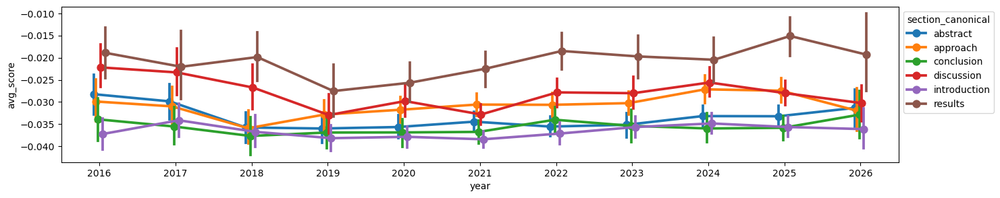

In [152]:
fig, ax = plt.subplots(figsize=(16,3))
sns.pointplot(paired_secs, x="year", y="avg_score", hue="section_canonical", dodge=True, ax=ax, hue_order=["abstract", "approach", "conclusion", "discussion", "introduction", "results"])
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

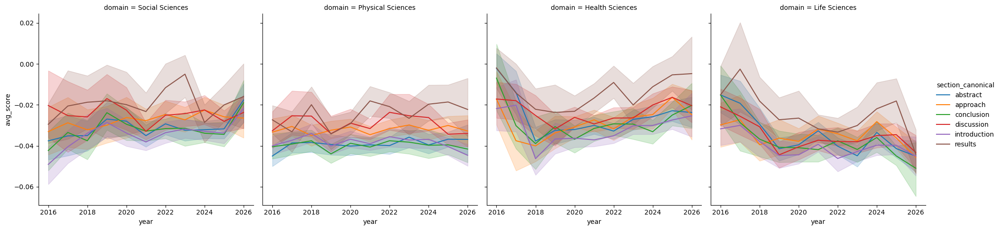

In [168]:
sns.relplot(paired_secs, x="year", y="avg_score", col="domain", hue="section_canonical", kind="line", hue_order=["abstract", "approach", "conclusion", "discussion", "introduction", "results"])

<Axes: xlabel='year', ylabel='avg_score'>

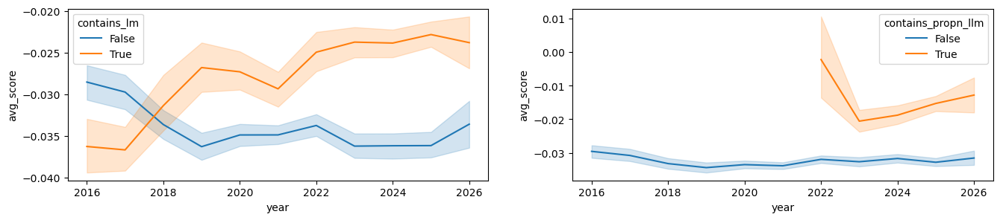

In [156]:
fig, axes = plt.subplots(1, 2, figsize=(16,3))
sns.lineplot(paired_secs, x="year", y="avg_score", hue="contains_lm", ax=axes[0])
sns.lineplot(paired_secs, x="year", y="avg_score", hue="contains_propn_llm", ax=axes[1])

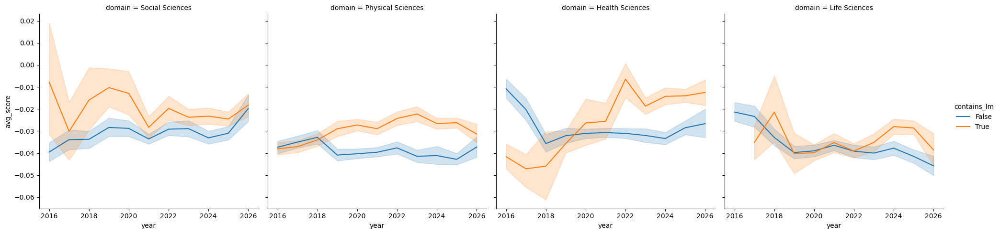

In [157]:
sns.relplot(paired_secs, x="year", y="avg_score", col="domain", hue="contains_lm", kind="line")

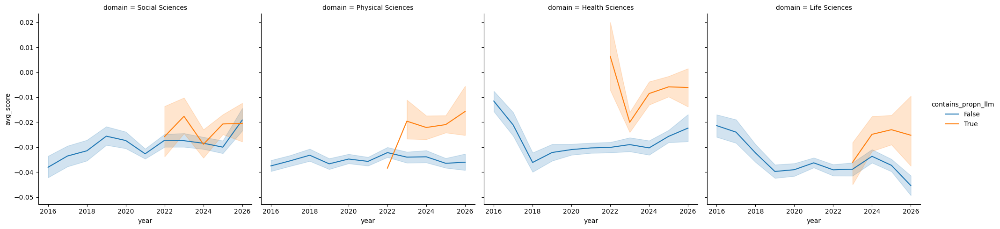

In [159]:
sns.relplot(paired_secs, x="year", y="avg_score", col="domain", hue="contains_propn_llm", kind="line")

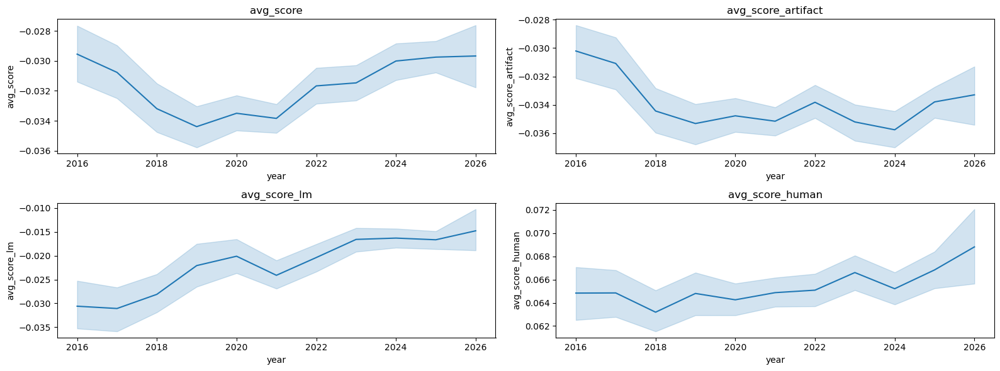

In [160]:
fig, axes = plt.subplots(2, 2, figsize=(16,6))
axes = axes.flatten()
for i, col_id in enumerate(("", "_artifact", "_lm", "_human")):
    col_name = f"avg_score{col_id}"
    axes[i].set_title(col_name)
    sns.lineplot(paired_secs, x="year", y=col_name, ax=axes[i])
plt.tight_layout()
plt.show()

In [166]:
docs["post_chatgpt"] = docs["year"] > 2022

/tmp/kapyahos/968383/ipykernel_1199448/95008490.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  docs["post_chatgpt"] = docs["year"] > 2022


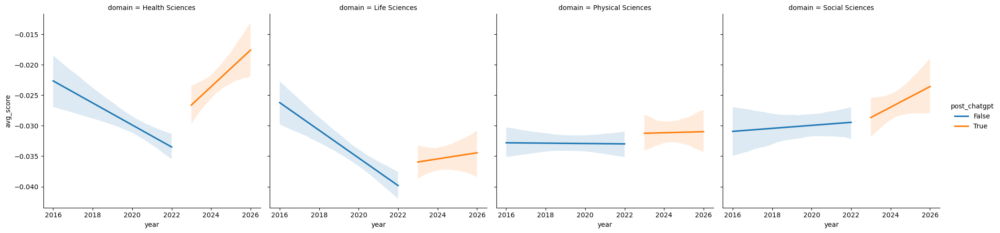

In [167]:
sns.lmplot(docs, x="year", y="avg_score", hue="post_chatgpt", col="domain", scatter=False)

In [56]:
df["score"].describe()

count    1.011876e+06
mean    -8.106971e-04
std      7.135170e-02
min     -2.385768e-01
25%     -5.363908e-02
50%     -1.254785e-02
75%      4.982493e-02
max      2.952445e-01
Name: score, dtype: float64

In [45]:
docs.dropna(subset=["avg_score", "year"]).isna().sum()

year                     0
domain                   0
has_abstract             0
has_body                 0
contains_lm              0
contains_artifact        0
contains_human           0
num_lm                   0
num_artifact             0
num_human                0
num_sents                0
avg_score                0
avg_score_lm          2953
avg_score_artifact       3
avg_score_human         42
dtype: int64

The following plot shows how the average scores have evolved in papers that either contain or do not contain LM terms, all domains together. As average_score contains both artifact and LM terms, the trend is expected to go up when more LM terms are introduced.

<Axes: xlabel='year', ylabel='avg_score'>

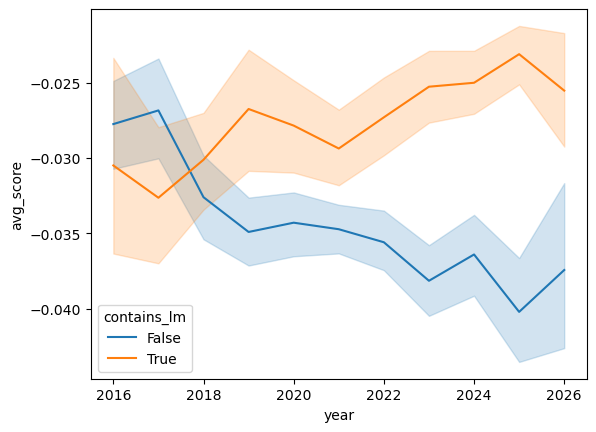

In [73]:
sns.lineplot(docs, x="year", y="avg_score", hue="contains_lm")

The same but with domain-level aggregation.

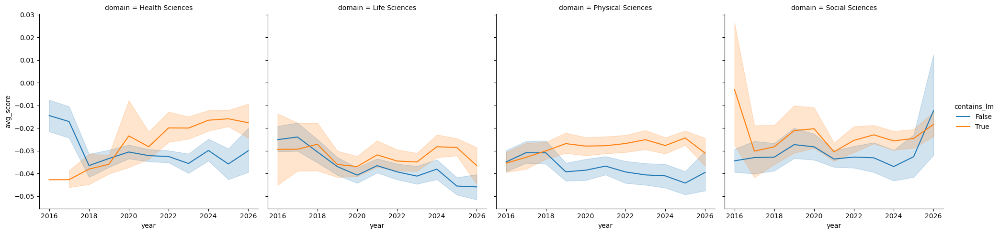

In [75]:
sns.relplot(docs, x="year", y="avg_score", col="domain", hue="contains_lm", kind="line")

The following plot might be more interesting as it supports the earlier findings of LM papers anthropomorphizing more in general; the average score here points only to the average of artifact terms, i.e. LM terms excluded. Still, there seems to be an upward trend for the papers that do include LM terms, too.

<Axes: xlabel='year', ylabel='avg_score_artifact'>

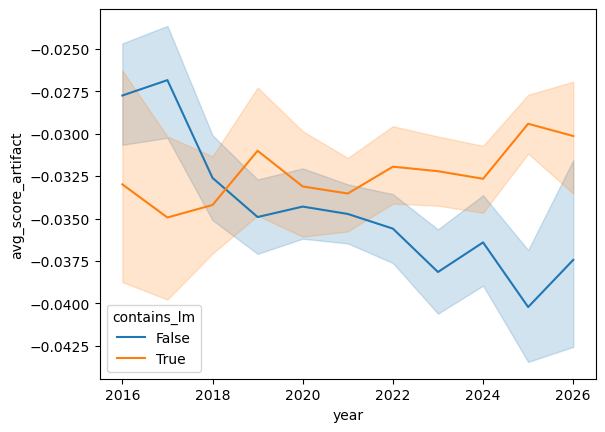

In [78]:
sns.lineplot(docs, x="year", y="avg_score_artifact", hue="contains_lm")

But, if the differences are plotted on domain-level, the gap doesn't necessarily look as dramatic.

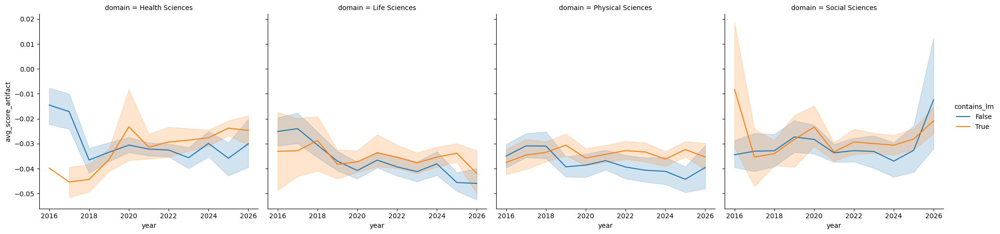

In [81]:
sns.relplot(docs, x="year", y="avg_score_artifact", col="domain", hue="contains_lm", kind="line")

The following is also somewhat interesting; it seems like the papers that contain LM terms treat human terms as less human-like than papers that do not include LM terms.

<Axes: xlabel='year', ylabel='avg_score_human'>

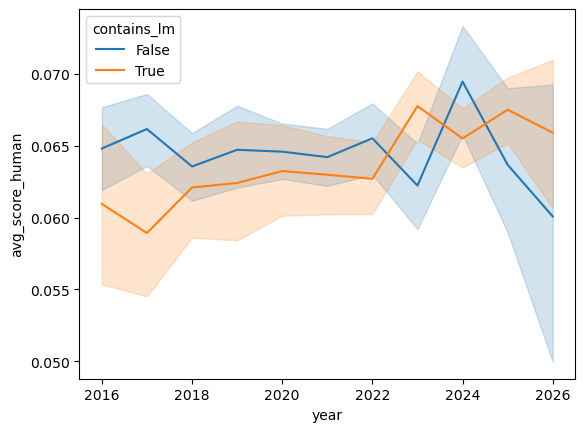

In [79]:
sns.lineplot(docs, x="year", y="avg_score_human", hue="contains_lm")

However, when domain-level differences for the phenomenon are inspected, it doesn't seem like the pattern is visible in other domains than Life Sciences.

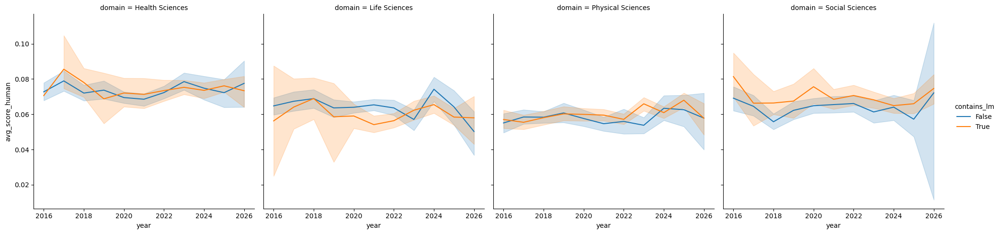

In [80]:
sns.relplot(docs, x="year", y="avg_score_human", col="domain", hue="contains_lm", kind="line")

If individual terms are inspected, can rising trends be seen?

In [72]:
df_dedup["post_chatgpt"] = df_dedup["year"] > 2022

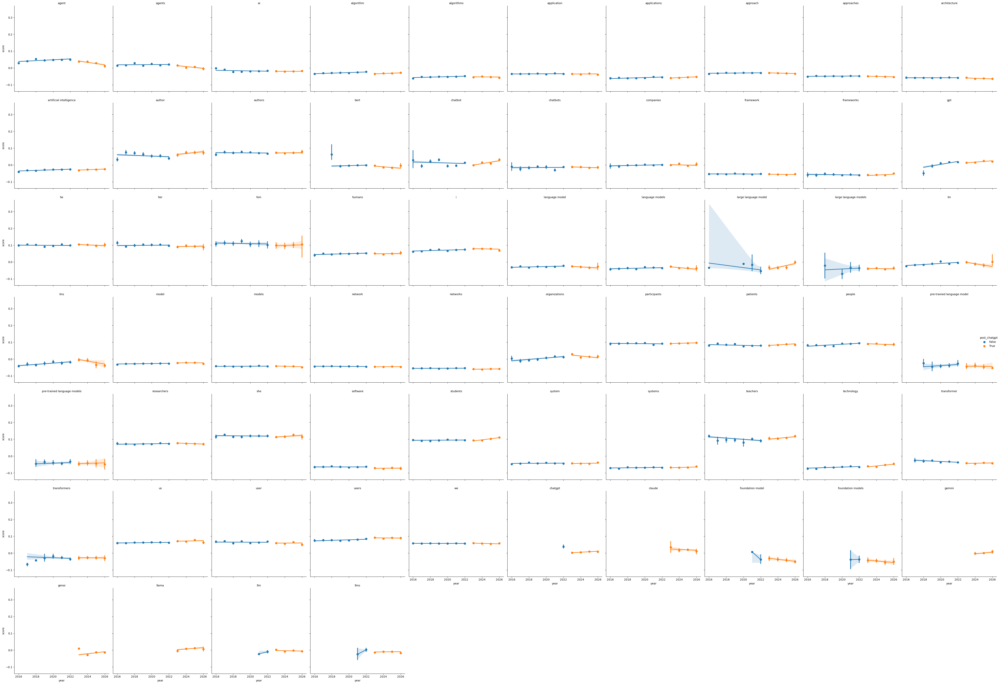

In [73]:
g = sns.lmplot(df_dedup, x="year", y="score", hue="post_chatgpt", col="entity_lower", x_estimator=np.mean, col_wrap=10)
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

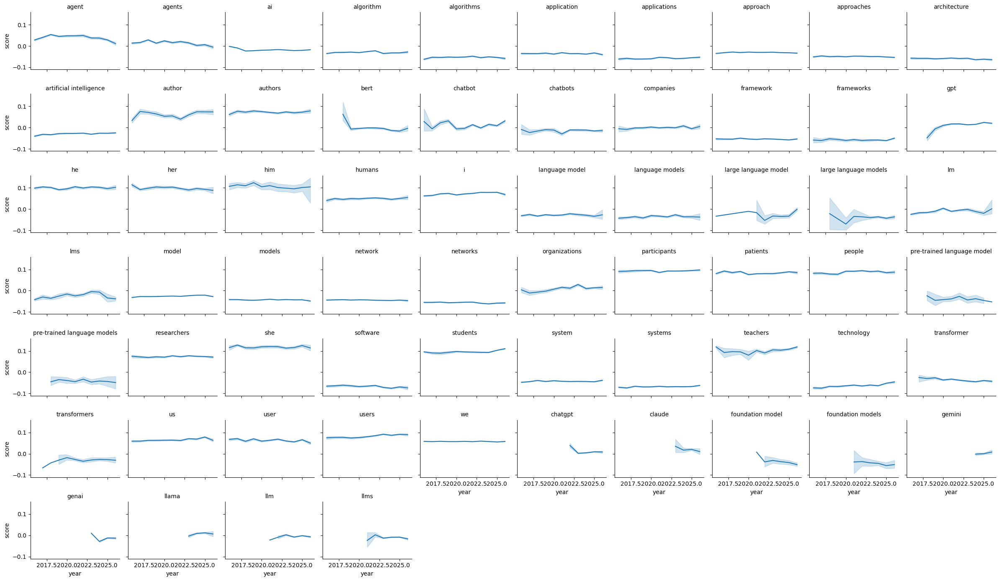

In [87]:
g = sns.relplot(
    data=df_dedup,
    x="year", y="score", col="entity_lower", col_wrap=10,
    kind="line", height=2, aspect=1.2, facet_kws={"sharey": True}
)
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

This data does not support the claim that certain terms would get more anthropomorphized through time; it rather seems that each term has a steady level of human-likeness. This gives reason to believe that the popularity of the terms might be a more plausible explanation for the rise of anthropomorphism.

## Temporal changes in term usage

In [170]:
paired_secs.columns

Index(['paper_id', 'section_canonical', 'year', 'domain', 'contains_artifact',
       'contains_lm', 'contains_propn_llm', 'contains_human', 'num_artifact',
       'num_lm', 'num_propn_llm', 'num_human', 'num_sents',
       'num_unique_entities', 'num_unique_entities_nonhum', 'avg_score',
       'avg_score_artifact', 'avg_score_lm', 'avg_score_lm_no_propn',
       'avg_score_propn_llm', 'avg_score_human'],
      dtype='object')

In [204]:
paired_secs["art_lm_ratio"] = paired_secs["num_artifact"] / (paired_secs["num_lm"] + paired_secs["num_propn_llm"])
paired_secs["art_lm_ratio"] = paired_secs["art_lm_ratio"].replace([np.inf, -np.inf], np.nan)

In [205]:
paired_secs["art_lm_ratio"].describe()

count    6498.000000
mean        4.437199
std         9.727786
min         0.000000
25%         0.666667
50%         1.545455
75%         4.000000
max       209.333333
Name: art_lm_ratio, dtype: float64

<Axes: xlabel='year'>

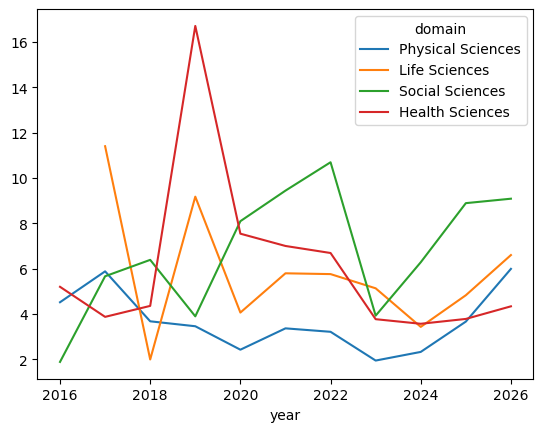

In [206]:
paired_secs.groupby(["year", "domain"], observed=True)["art_lm_ratio"].mean().unstack("domain")[domain_order].plot()

In [201]:
grouped = paired_secs.groupby('paper_id').agg(art_sum=('num_artifact', 'sum'),
                                              lm_sum=('num_lm', 'sum'),
                                              prod_sum=('num_propn_llm', 'sum'),
                                              year=('year', 'first'),
                                              domain=('domain', 'first'))

grouped['ratio'] = grouped['art_sum'] / (grouped['lm_sum'] + grouped['prod_sum'])
grouped['ratio'] = grouped['ratio'].replace([np.inf, -np.inf], np.nan)

In [202]:
grouped["ratio"].describe()

count    1605.000000
mean       16.565617
std        34.875119
min         0.000000
25%         1.144928
50%         2.777778
75%        11.857143
max       344.000000
Name: ratio, dtype: float64

<Axes: xlabel='year'>

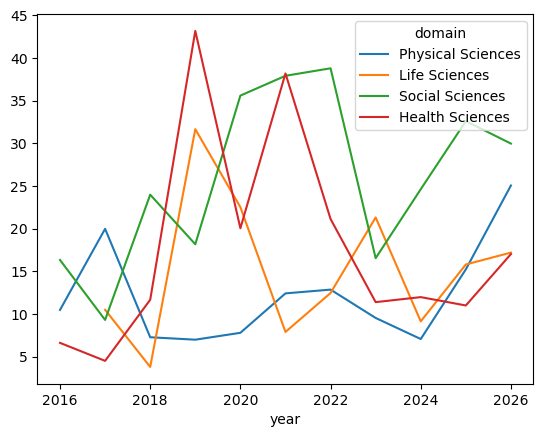

In [203]:
grouped.groupby(["year", "domain"], observed=True)["ratio"].mean().unstack("domain")[domain_order].plot()

In [174]:
paired_secs.groupby(["year", "paper_id", "section_canonical"])["contains_lm"].mean()

year  paper_id     section_canonical
2016  W2210838531  abstract             1.0
                   approach             0.0
                   conclusion           0.0
                   discussion           0.0
                   introduction         1.0
                                       ... 
2026  W7150908008  abstract             0.0
                   approach             0.0
                   conclusion           0.0
                   discussion           0.0
                   introduction         1.0
Name: contains_lm, Length: 22289, dtype: float64

<Axes: xlabel='year'>

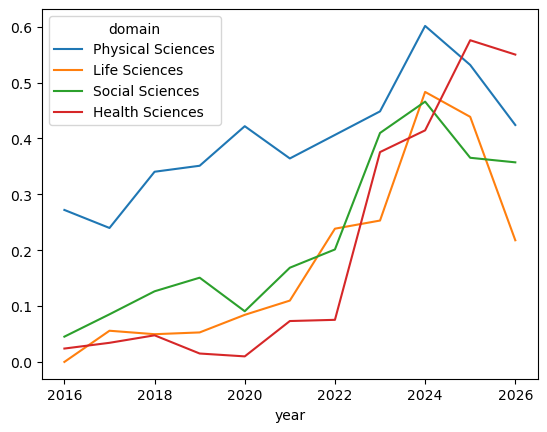

In [179]:
paired_secs.groupby(["year", "domain"], observed=True)["contains_lm"].mean().unstack("domain")[domain_order].plot()

<Axes: xlabel='year'>

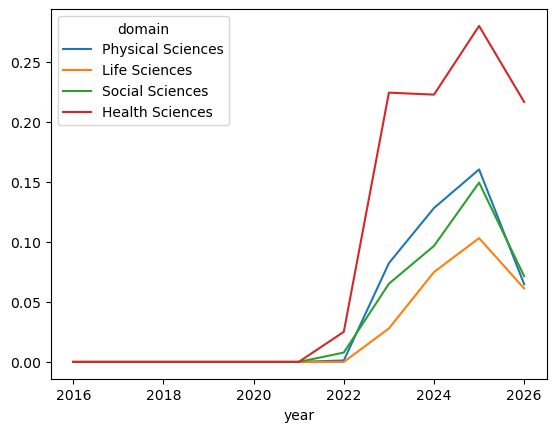

In [180]:
paired_secs.groupby(["year", "domain"], observed=True)["contains_propn_llm"].mean().unstack("domain")[domain_order].plot()

## Section-level plots

How do abstracts and bodies compare? (Both in general and in the paired data)

<Axes: xlabel='year', ylabel='avg_score'>

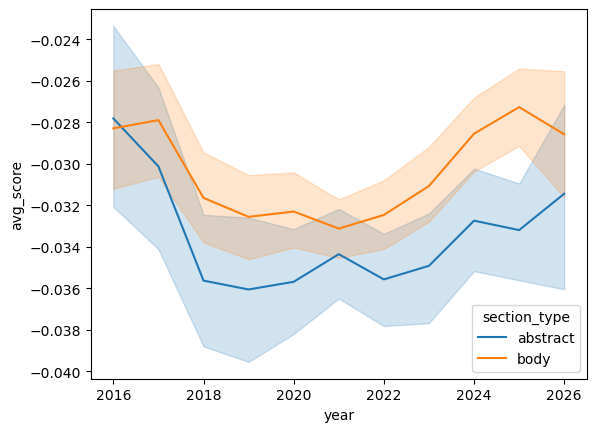

In [89]:
sns.lineplot(docs_per_section, x="year", y="avg_score", hue="section_type")

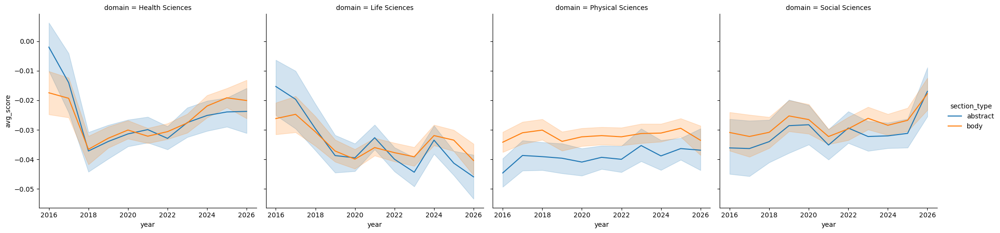

In [88]:
sns.relplot(docs_per_section, x="year", y="avg_score", col="domain", hue="section_type", kind="line")

<Axes: xlabel='year', ylabel='avg_score'>

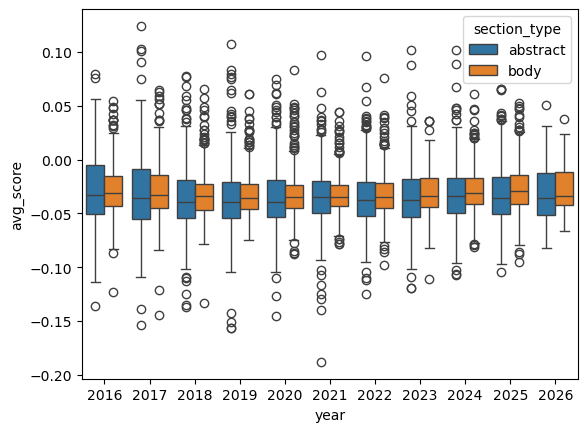

In [71]:
sns.boxplot(docs_per_section, x="year", y="avg_score", hue="section_type")

In [112]:
paired.columns

Index(['year', 'domain', 'contains_lm_abs', 'contains_artifact_abs',
       'contains_human_abs', 'num_lm_abs', 'num_artifact_abs', 'num_human_abs',
       'num_sents_abs', 'avg_score_abs', 'avg_score_lm_abs',
       'avg_score_artifact_abs', 'avg_score_human_abs', 'contains_lm_body',
       'contains_artifact_body', 'contains_human_body', 'num_lm_body',
       'num_artifact_body', 'num_human_body', 'num_sents_body',
       'avg_score_body', 'avg_score_lm_body', 'avg_score_artifact_body',
       'avg_score_human_body'],
      dtype='object')

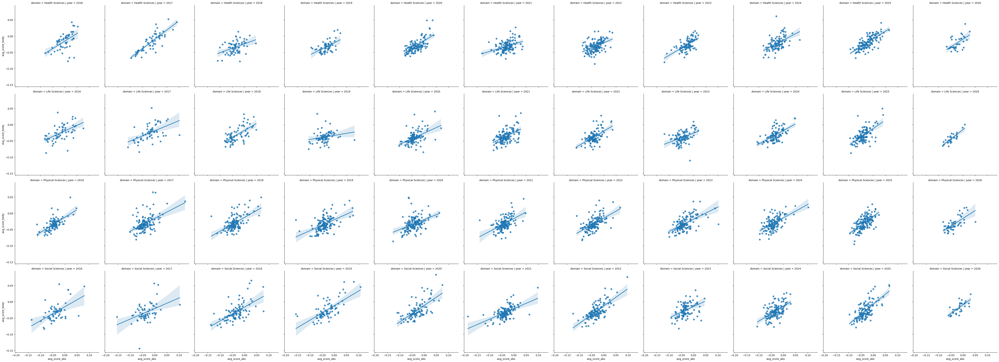

In [125]:
sns.lmplot(paired, x="avg_score_abs", y="avg_score_body", row="domain", col="year")

In [75]:
paired["avg_score_abs"].corr(paired["avg_score_body"])

0.5804413524350238

In [77]:
subset = paired.dropna(subset=["avg_score_abs", "avg_score_body"])
linregress(subset["avg_score_abs"], subset["avg_score_body"])

LinregressResult(slope=0.4164828464011619, intercept=-0.01648516263122732, rvalue=0.5804413524350238, pvalue=0.0, stderr=0.008650608622066515, intercept_stderr=0.0003886885245090644)

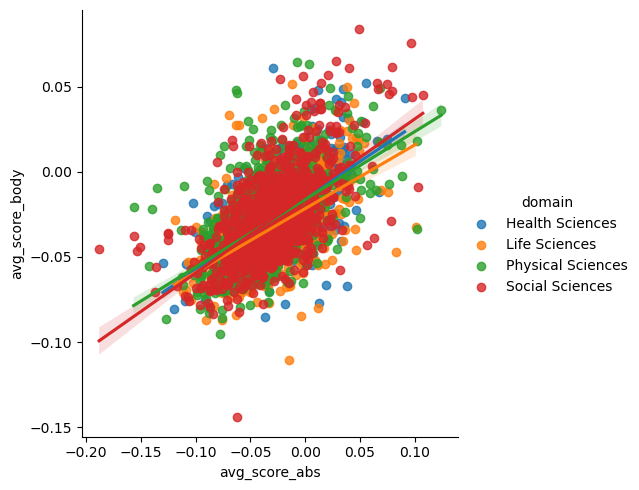

In [118]:
sns.lmplot(paired, x="avg_score_abs", y="avg_score_body", hue="domain")

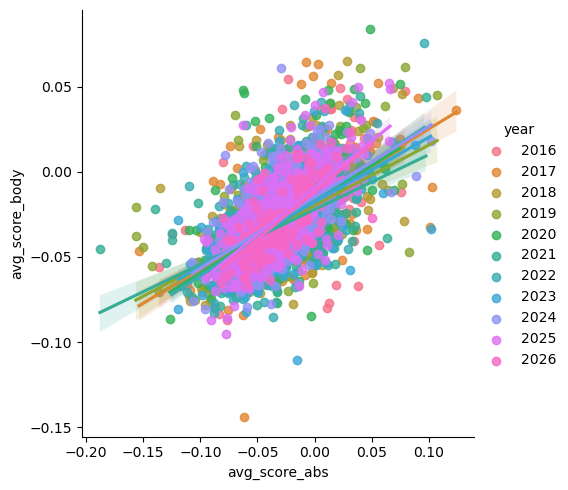

In [119]:
ax = sns.lmplot(paired, x="avg_score_abs", y="avg_score_body", hue="year")

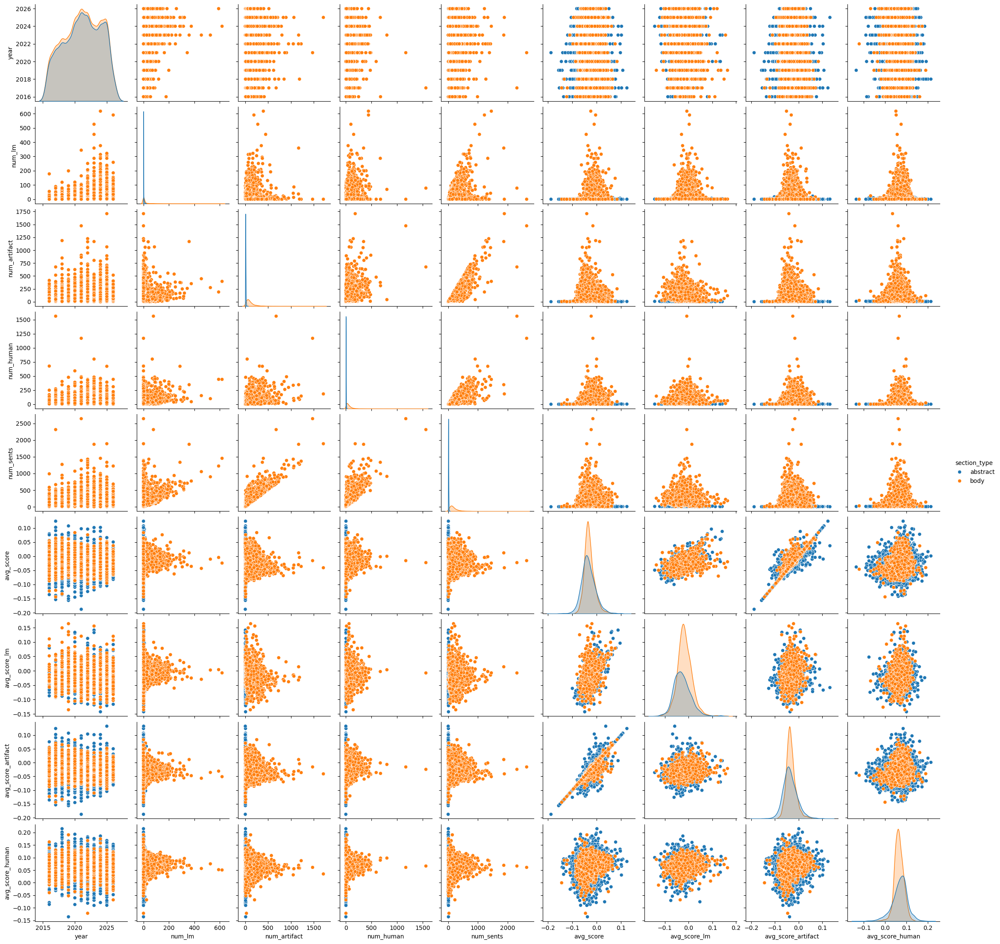

In [100]:
sns.pairplot(docs_per_section.select_dtypes(exclude="bool"), hue="section_type")

### Correlation matrices

In [101]:
docs_per_section.corr(method="pearson", numeric_only=True).style.background_gradient(axis=None)

,year,contains_lm,contains_artifact,contains_human,num_lm,num_artifact,num_human,num_sents,avg_score,avg_score_lm,avg_score_artifact,avg_score_human
year,1.000000,0.328531,0.000252,-0.003309,0.206533,0.118036,0.043818,0.134089,0.002176,0.049591,-0.050865,0.023217
contains_lm,0.328531,1.000000,-0.068541,0.135635,0.411186,0.138007,0.199868,0.245531,0.123369,nan,0.010530,0.011362
contains_artifact,0.000252,-0.068541,1.000000,-0.005625,0.021996,0.077202,0.062545,0.079059,-0.049129,-0.008060,nan,-0.025968
contains_human,-0.003309,0.135635,-0.005625,1.000000,0.088852,0.188571,0.193833,0.215390,0.058433,0.015013,0.052147,nan
num_lm,0.206533,0.411186,0.021996,0.088852,1.000000,0.185498,0.353836,0.447492,0.156261,0.196333,0.040791,0.013757
num_artifact,0.118036,0.138007,0.077202,0.188571,0.185498,1.000000,0.563082,0.911281,0.009958,0.000428,0.028423,-0.066924
num_human,0.043818,0.199868,0.062545,0.193833,0.353836,0.563082,1.000000,0.820021,0.146808,0.140943,0.125228,0.017523
num_sents,0.134089,0.245531,0.079059,0.215390,0.447492,0.911281,0.820021,1.000000,0.092159,0.103196,0.074230,-0.035193
avg_score,0.002176,0.123369,-0.049129,0.058433,0.156261,0.009958,0.146808,0.092159,1.000000,0.607652,0.932319,0.159465
avg_score_lm,0.049591,nan,-0.008060,0.015013,0.196333,0.000428,0.140943,0.103196,0.607652,1.000000,0.225549,0.130436


In [102]:
docs_per_section.corr(method="spearman", numeric_only=True).style.background_gradient(axis=None)

,year,contains_lm,contains_artifact,contains_human,num_lm,num_artifact,num_human,num_sents,avg_score,avg_score_lm,avg_score_artifact,avg_score_human
year,1.000000,0.334698,-0.001536,-0.006227,0.347550,0.102848,0.021119,0.137685,0.024082,0.083051,-0.032662,0.037573
contains_lm,0.334698,1.000000,-0.068541,0.135635,0.974240,0.096396,0.231699,0.258553,0.142817,nan,0.019566,-0.003427
contains_artifact,-0.001536,-0.068541,1.000000,-0.005625,-0.051275,0.209865,0.092146,0.161843,-0.028110,0.003263,nan,-0.032286
contains_human,-0.006227,0.135635,-0.005625,1.000000,0.143696,0.279826,0.533254,0.385254,0.061454,0.017806,0.055882,nan
num_lm,0.347550,0.974240,-0.051275,0.143696,1.000000,0.146771,0.289318,0.323149,0.178156,0.326476,0.035255,-0.008968
num_artifact,0.102848,0.096396,0.209865,0.279826,0.146771,1.000000,0.754969,0.940802,0.039219,0.070401,0.071371,-0.132727
num_human,0.021119,0.231699,0.092146,0.533254,0.289318,0.754969,1.000000,0.881038,0.163370,0.193976,0.148909,-0.072368
num_sents,0.137685,0.258553,0.161843,0.385254,0.323149,0.940802,0.881038,1.000000,0.123231,0.189936,0.103866,-0.105882
avg_score,0.024082,0.142817,-0.028110,0.061454,0.178156,0.039219,0.163370,0.123231,1.000000,0.620805,0.933185,0.163564
avg_score_lm,0.083051,nan,0.003263,0.017806,0.326476,0.070401,0.193976,0.189936,0.620805,1.000000,0.254103,0.137999


In [103]:
docs_per_section.groupby("section_type").corr(numeric_only=True).style.background_gradient(axis=None)

In [105]:
paired.select_dtypes(include=["float64", "bool"]).corr().style.background_gradient(axis=None)

,contains_lm_abs,contains_artifact_abs,contains_human_abs,avg_score_abs,avg_score_lm_abs,avg_score_artifact_abs,avg_score_human_abs,contains_lm_body,contains_artifact_body,contains_human_body,avg_score_body,avg_score_lm_body,avg_score_artifact_body,avg_score_human_body
contains_lm_abs,1.000000,-0.147863,0.135267,0.066661,nan,-0.036503,0.035108,0.703374,-0.001532,0.017050,0.230125,0.106295,0.068507,0.009255
contains_artifact_abs,-0.147863,1.000000,-0.048156,-0.055585,-0.039825,nan,-0.026562,-0.093670,0.074677,0.003352,-0.077455,-0.095566,-0.006442,-0.056848
contains_human_abs,0.135267,-0.048156,1.000000,0.058930,-0.033803,0.051256,nan,0.097623,0.029797,0.104934,0.114912,0.063675,0.096148,0.054288
avg_score_abs,0.066661,-0.055585,0.058930,1.000000,0.707805,0.929383,0.121440,0.057794,0.033716,0.014785,0.580441,0.308675,0.560745,0.217841
avg_score_lm_abs,nan,-0.039825,-0.033803,0.707805,1.000000,0.158953,0.093876,-0.022003,-0.016025,-0.080649,0.451082,0.441416,0.306422,0.153734
avg_score_artifact_abs,-0.036503,nan,0.051256,0.929383,0.158953,1.000000,0.110944,-0.014896,0.036533,0.023676,0.509013,0.172752,0.538341,0.202960
avg_score_human_abs,0.035108,-0.026562,nan,0.121440,0.093876,0.110944,1.000000,0.030186,-0.017399,0.005859,0.106330,0.124672,0.090910,0.353240
contains_lm_body,0.703374,-0.093670,0.097623,0.057794,-0.022003,-0.014896,0.030186,1.000000,0.031285,0.033794,0.178342,nan,0.051072,0.004638
contains_artifact_body,-0.001532,0.074677,0.029797,0.033716,-0.016025,0.036533,-0.017399,0.031285,1.000000,0.051339,-0.044058,-0.036569,nan,0.012814
contains_human_body,0.017050,0.003352,0.104934,0.014785,-0.080649,0.023676,0.005859,0.033794,0.051339,1.000000,-0.021123,-0.008997,-0.014361,nan


In [106]:
paired.select_dtypes(include=["int64", "bool"]).corr().style.background_gradient(axis=None)

,year,contains_lm_abs,contains_artifact_abs,contains_human_abs,num_lm_abs,num_artifact_abs,num_human_abs,num_sents_abs,contains_lm_body,contains_artifact_body,contains_human_body,num_lm_body,num_artifact_body,num_human_body,num_sents_body
year,1.000000,0.265975,0.007462,-0.004876,0.289167,0.140549,0.013120,0.236844,0.382185,-0.000248,-0.008600,0.279821,0.195305,0.070250,0.229950
contains_lm_abs,0.265975,1.000000,-0.147863,0.135267,0.724102,-0.232147,0.083329,0.137165,0.703374,-0.001532,0.017050,0.603330,-0.104934,0.147652,0.127225
contains_artifact_abs,0.007462,-0.147863,1.000000,-0.048156,-0.115526,0.233005,-0.023953,0.133722,-0.093670,0.074677,0.003352,-0.099198,0.112967,-0.034894,0.041500
contains_human_abs,-0.004876,0.135267,-0.048156,1.000000,0.098644,-0.000456,0.533932,0.264240,0.097623,0.029797,0.104934,0.093131,-0.032208,0.252677,0.102875
num_lm_abs,0.289167,0.724102,-0.115526,0.098644,1.000000,-0.181751,0.102960,0.297755,0.514832,-0.000863,0.007085,0.723024,-0.088053,0.105975,0.149622
num_artifact_abs,0.140549,-0.232147,0.233005,-0.000456,-0.181751,1.000000,0.112789,0.791225,-0.117617,0.012411,0.016636,-0.150994,0.448644,0.001601,0.278683
num_human_abs,0.013120,0.083329,-0.023953,0.533932,0.102960,0.112789,1.000000,0.554785,0.054032,0.009335,0.069681,0.114116,0.031265,0.431794,0.225579
num_sents_abs,0.236844,0.137165,0.133722,0.264240,0.297755,0.791225,0.554785,1.000000,0.134082,0.013723,0.045792,0.215995,0.344211,0.225858,0.382952
contains_lm_body,0.382185,0.703374,-0.093670,0.097623,0.514832,-0.117617,0.054032,0.134082,1.000000,0.031285,0.033794,0.481758,0.089050,0.186575,0.250379
contains_artifact_body,-0.000248,-0.001532,0.074677,0.029797,-0.000863,0.012411,0.009335,0.013723,0.031285,1.000000,0.051339,0.008532,0.049190,0.040146,0.052783


In [104]:
paired.corr(numeric_only=True).style.background_gradient(axis=None)

,year,contains_lm_abs,contains_artifact_abs,contains_human_abs,num_lm_abs,num_artifact_abs,num_human_abs,num_sents_abs,avg_score_abs,avg_score_lm_abs,avg_score_artifact_abs,avg_score_human_abs,contains_lm_body,contains_artifact_body,contains_human_body,num_lm_body,num_artifact_body,num_human_body,num_sents_body,avg_score_body,avg_score_lm_body,avg_score_artifact_body,avg_score_human_body
year,1.000000,0.265975,0.007462,-0.004876,0.289167,0.140549,0.013120,0.236844,-0.014948,0.076614,-0.056477,0.014934,0.382185,-0.000248,-0.008600,0.279821,0.195305,0.070250,0.229950,0.023063,0.035359,-0.044357,0.036768
contains_lm_abs,0.265975,1.000000,-0.147863,0.135267,0.724102,-0.232147,0.083329,0.137165,0.066661,nan,-0.036503,0.035108,0.703374,-0.001532,0.017050,0.603330,-0.104934,0.147652,0.127225,0.230125,0.106295,0.068507,0.009255
contains_artifact_abs,0.007462,-0.147863,1.000000,-0.048156,-0.115526,0.233005,-0.023953,0.133722,-0.055585,-0.039825,nan,-0.026562,-0.093670,0.074677,0.003352,-0.099198,0.112967,-0.034894,0.041500,-0.077455,-0.095566,-0.006442,-0.056848
contains_human_abs,-0.004876,0.135267,-0.048156,1.000000,0.098644,-0.000456,0.533932,0.264240,0.058930,-0.033803,0.051256,nan,0.097623,0.029797,0.104934,0.093131,-0.032208,0.252677,0.102875,0.114912,0.063675,0.096148,0.054288
num_lm_abs,0.289167,0.724102,-0.115526,0.098644,1.000000,-0.181751,0.102960,0.297755,0.130228,0.268150,-0.021059,0.044000,0.514832,-0.000863,0.007085,0.723024,-0.088053,0.105975,0.149622,0.257234,0.202622,0.056835,0.042226
num_artifact_abs,0.140549,-0.232147,0.233005,-0.000456,-0.181751,1.000000,0.112789,0.791225,-0.046908,-0.065748,-0.001816,-0.036448,-0.117617,0.012411,0.016636,-0.150994,0.448644,0.001601,0.278683,-0.070139,-0.100579,0.003285,-0.026327
num_human_abs,0.013120,0.083329,-0.023953,0.533932,0.102960,0.112789,1.000000,0.554785,0.116360,0.068961,0.102691,0.071269,0.054032,0.009335,0.069681,0.114116,0.031265,0.431794,0.225579,0.181853,0.123705,0.164033,0.133649
num_sents_abs,0.236844,0.137165,0.133722,0.264240,0.297755,0.791225,0.554785,1.000000,0.064049,0.125675,0.033371,0.016448,0.134082,0.013723,0.045792,0.215995,0.344211,0.225858,0.382952,0.123032,0.076903,0.094683,0.051779
avg_score_abs,-0.014948,0.066661,-0.055585,0.058930,0.130228,-0.046908,0.116360,0.064049,1.000000,0.707805,0.929383,0.121440,0.057794,0.033716,0.014785,0.103013,-0.073386,0.113576,0.019072,0.580441,0.308675,0.560745,0.217841
avg_score_lm_abs,0.076614,nan,-0.039825,-0.033803,0.268150,-0.065748,0.068961,0.125675,0.707805,1.000000,0.158953,0.093876,-0.022003,-0.016025,-0.080649,0.184153,-0.066048,0.075392,0.059401,0.451082,0.441416,0.306422,0.153734


### Pointplots

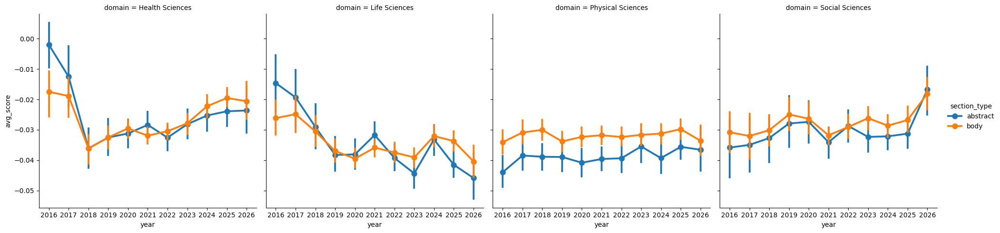

In [47]:
sns.catplot(docs_per_section, x="year", y="avg_score", kind="point", col="domain", hue="section_type")

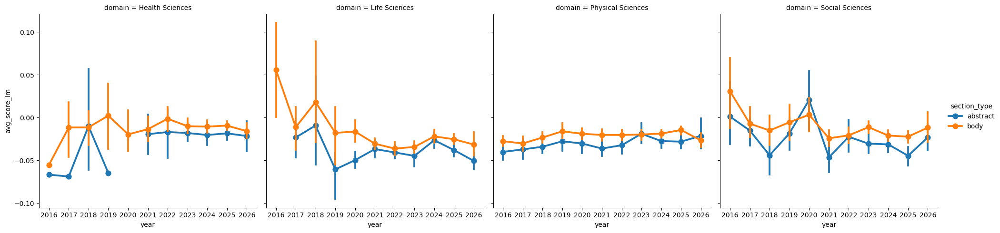

In [48]:
sns.catplot(docs_per_section, x="year", y="avg_score_lm", kind="point", col="domain", hue="section_type")

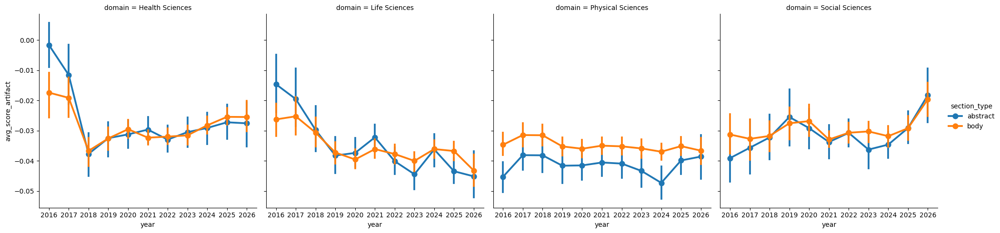

In [49]:
sns.catplot(docs_per_section, x="year", y="avg_score_artifact", kind="point", col="domain", hue="section_type")

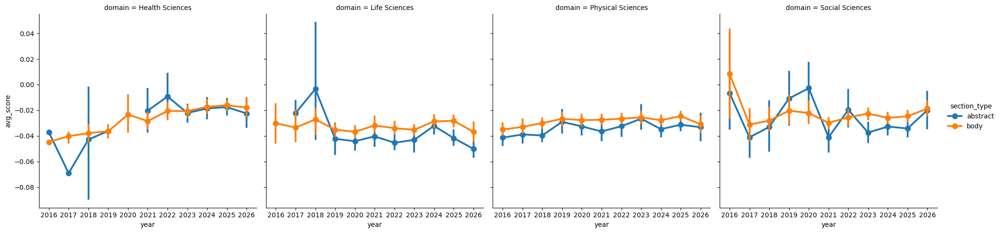

In [50]:
sns.catplot(docs_per_section[docs_per_section["contains_lm"] == True], x="year", y="avg_score", kind="point", col="domain", hue="section_type")

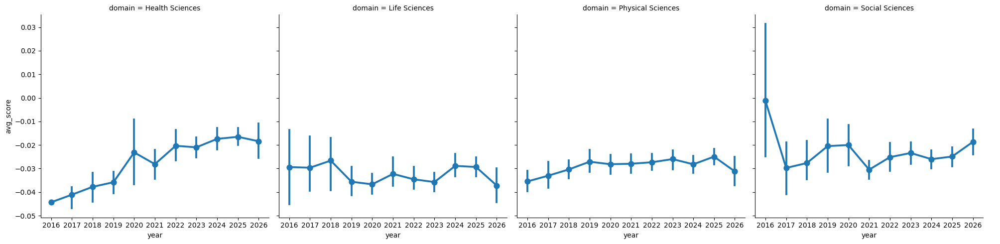

In [52]:
sns.catplot(docs[docs["contains_lm"] == True], x="year", y="avg_score", kind="point", col="domain")

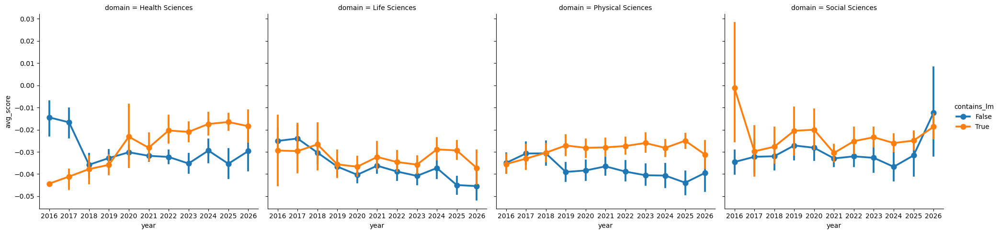

In [54]:
sns.catplot(docs, x="year", y="avg_score", kind="point", col="domain", hue="contains_lm")

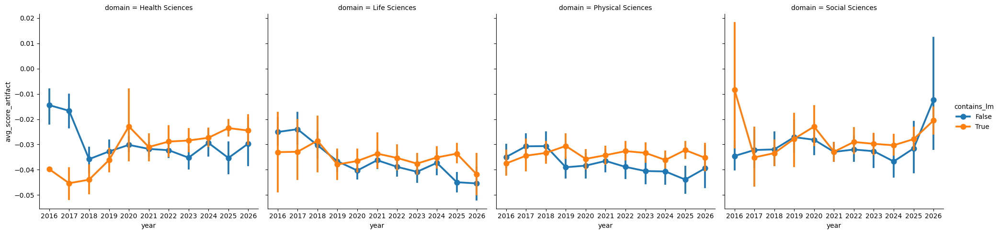

In [55]:
sns.catplot(docs, x="year", y="avg_score_artifact", kind="point", col="domain", hue="contains_lm")

## Entities per section

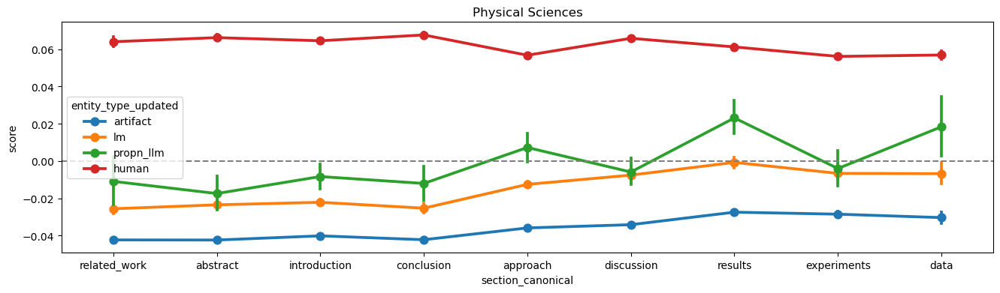

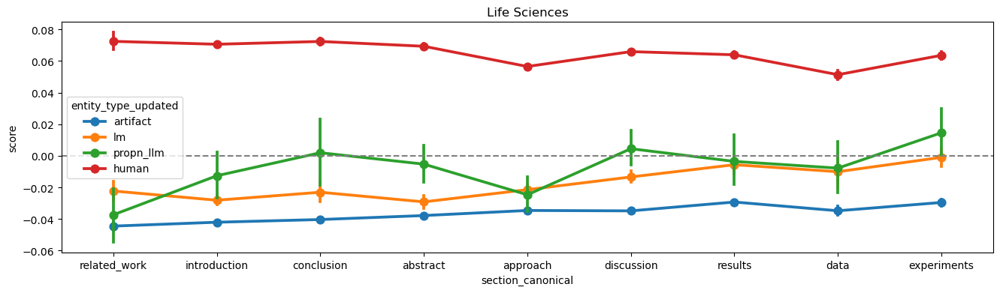

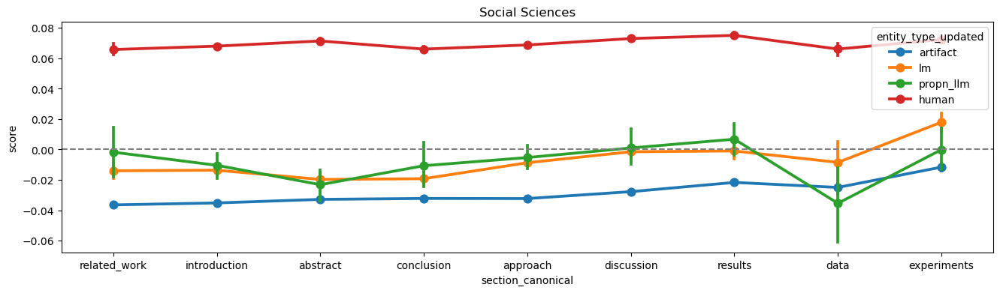

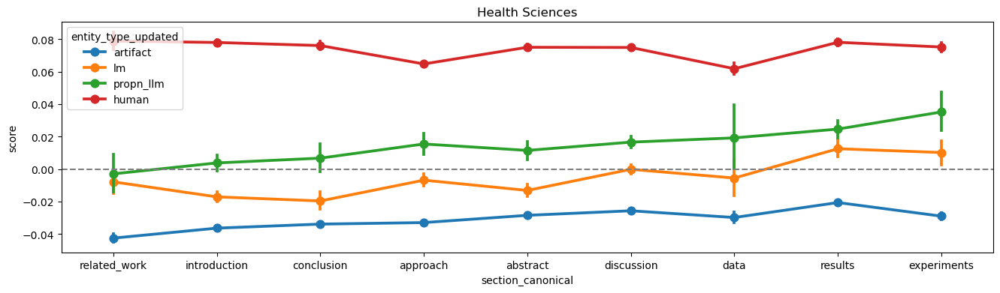

In [179]:
for domain in domain_order:
    sub = paired_df[paired_df["domain"] == domain]
    order = sub.groupby('section_canonical')['score'].mean().sort_values().index
    fig, ax = plt.subplots(figsize=(16, 4))
    sns.pointplot(sub, x="section_canonical", y="score", hue="entity_type_updated", ax=ax, order=order, hue_order=entity_order)
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(domain)

In [35]:
def standardize(table):
    row_totals = table.sum(axis=1)
    col_totals = table.sum(axis=0)
    grand_total = table.sum().sum()
    
    E = np.outer(row_totals, col_totals) / grand_total
    E = pd.DataFrame(E, index=table.index, columns=table.columns)
    
    lift = table / E
    log_lift = np.log(lift.mask(lift == 0, np.nan))
    return log_lift

<Axes: xlabel='entity_lower', ylabel='section_canonical'>

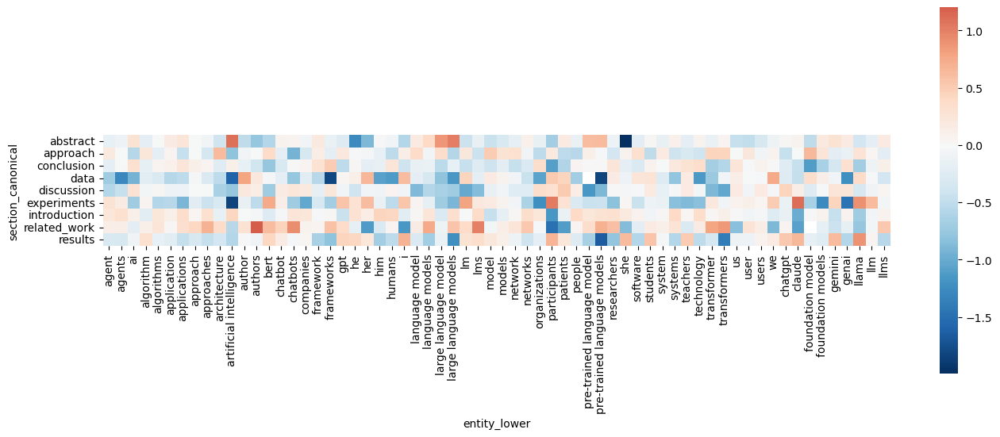

In [42]:
fig, ax = plt.subplots(figsize=(16,6))
sns.heatmap(standardize(pd.crosstab(paired_df["section_canonical"], paired_df["entity_lower"])), yticklabels=1, cmap="RdBu_r", square=True, ax=ax, center=0)

<Axes: xlabel='entity_lower', ylabel='section_canonical'>

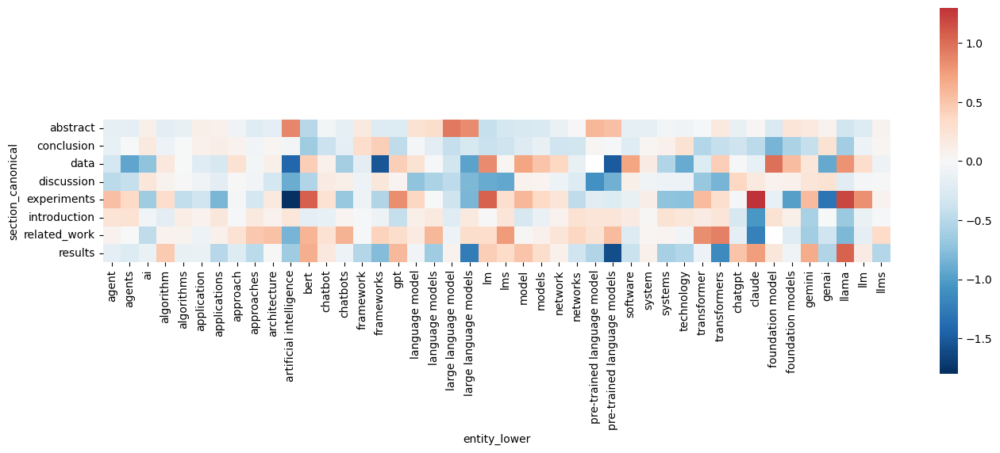

In [75]:
fig, ax = plt.subplots(figsize=(16,6))
sns.heatmap(standardize(pd.crosstab(paired_nohum["section_canonical"], paired_nohum["entity_lower"])), yticklabels=1, cmap="RdBu_r", square=True, ax=ax, center=0)

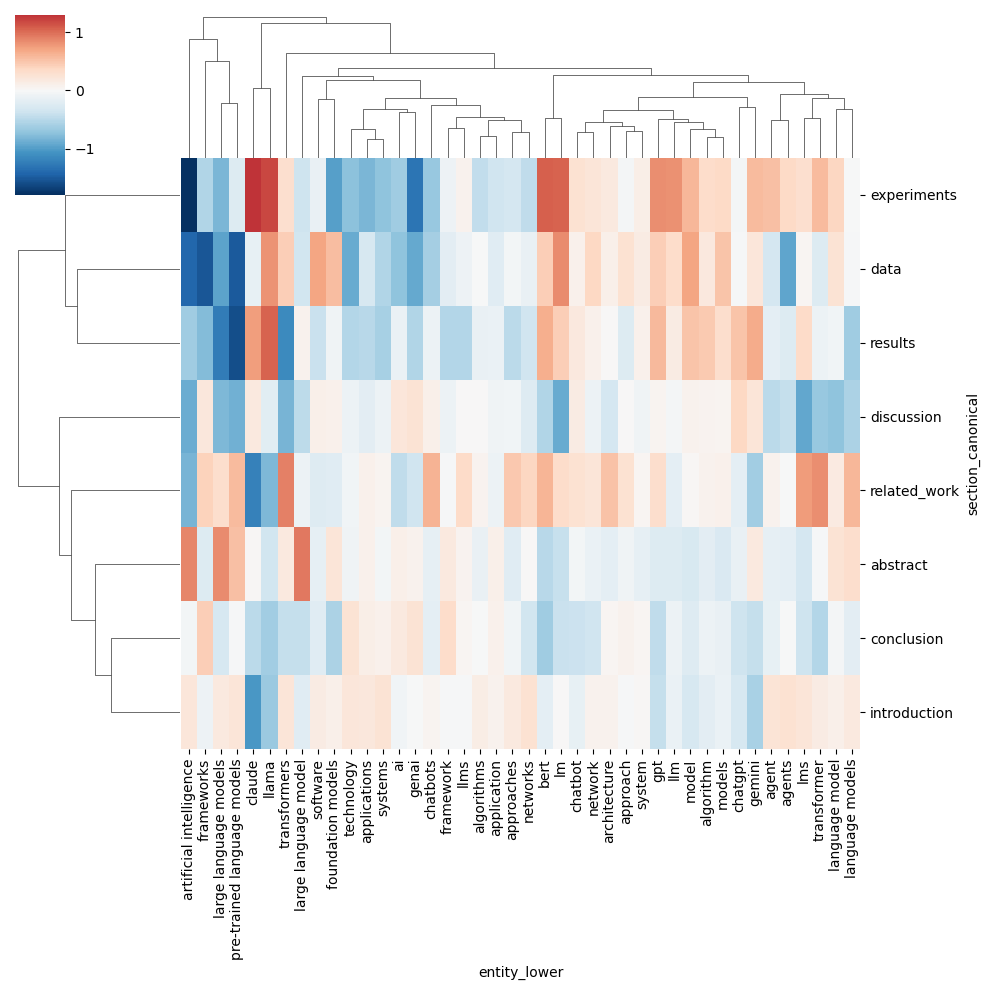

In [76]:
sns.clustermap(standardize(pd.crosstab(paired_nohum["section_canonical"], paired_nohum["entity_lower"])).dropna(axis=1), cmap="RdBu_r", xticklabels=1, center=0)

Physical Sciences


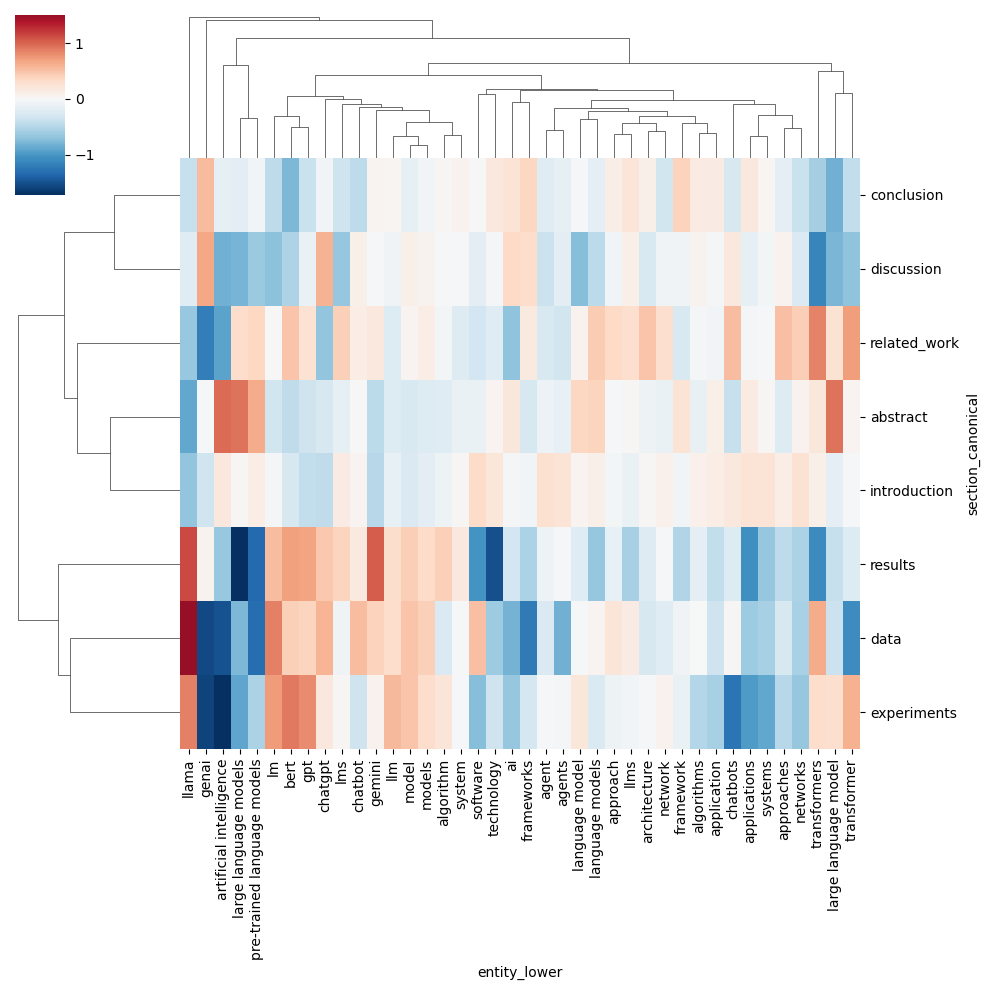

Life Sciences


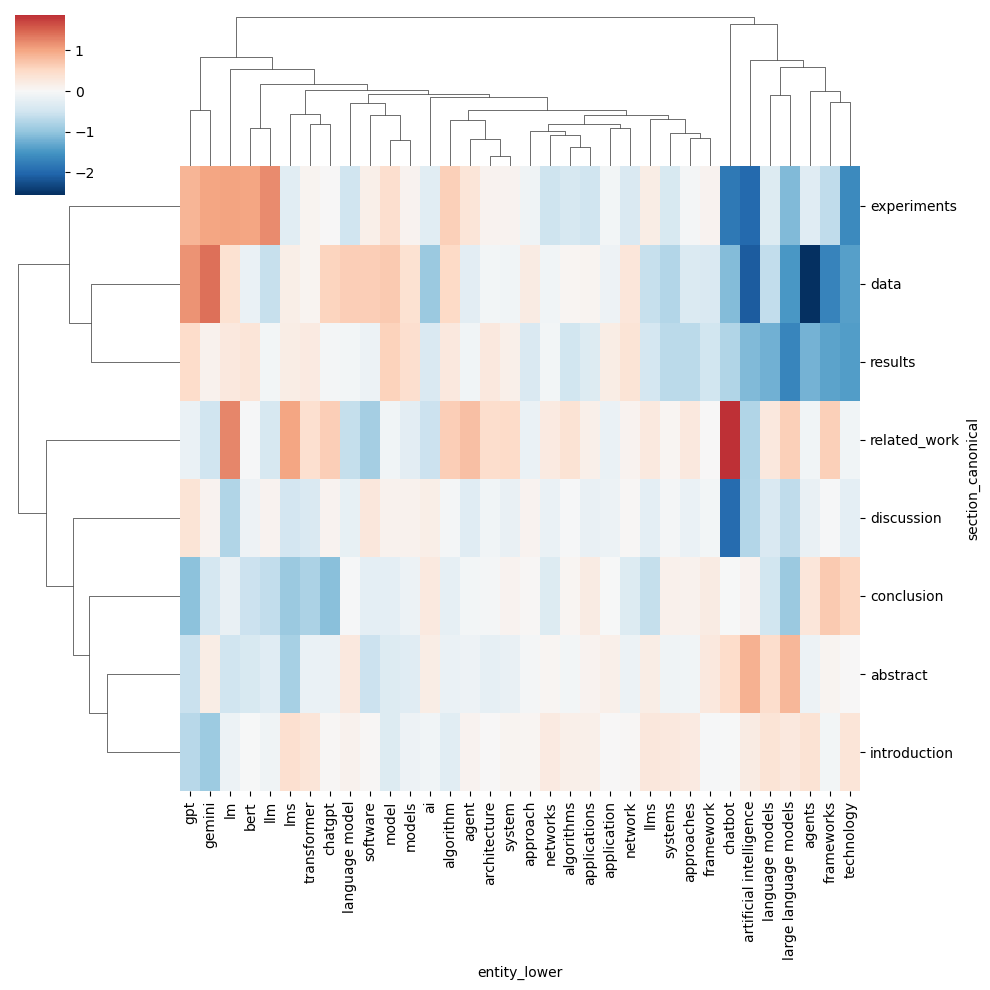

Social Sciences


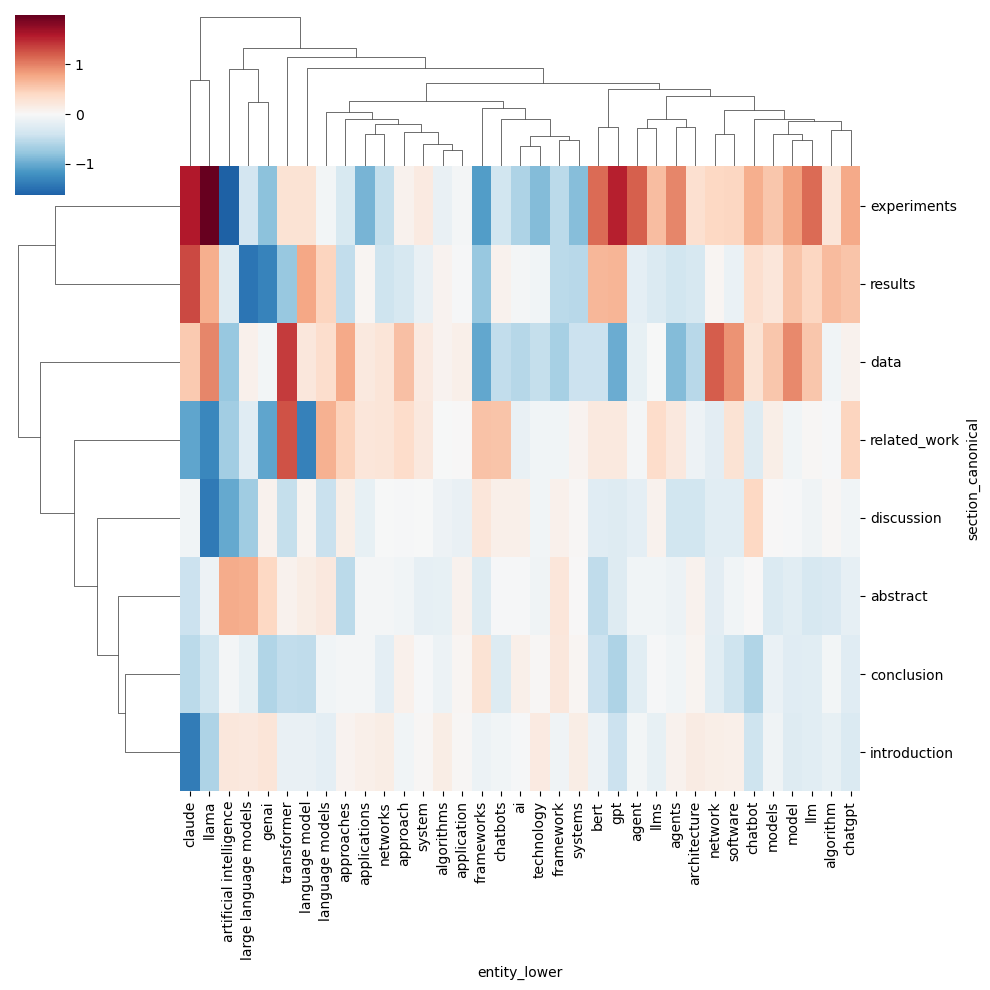

Health Sciences


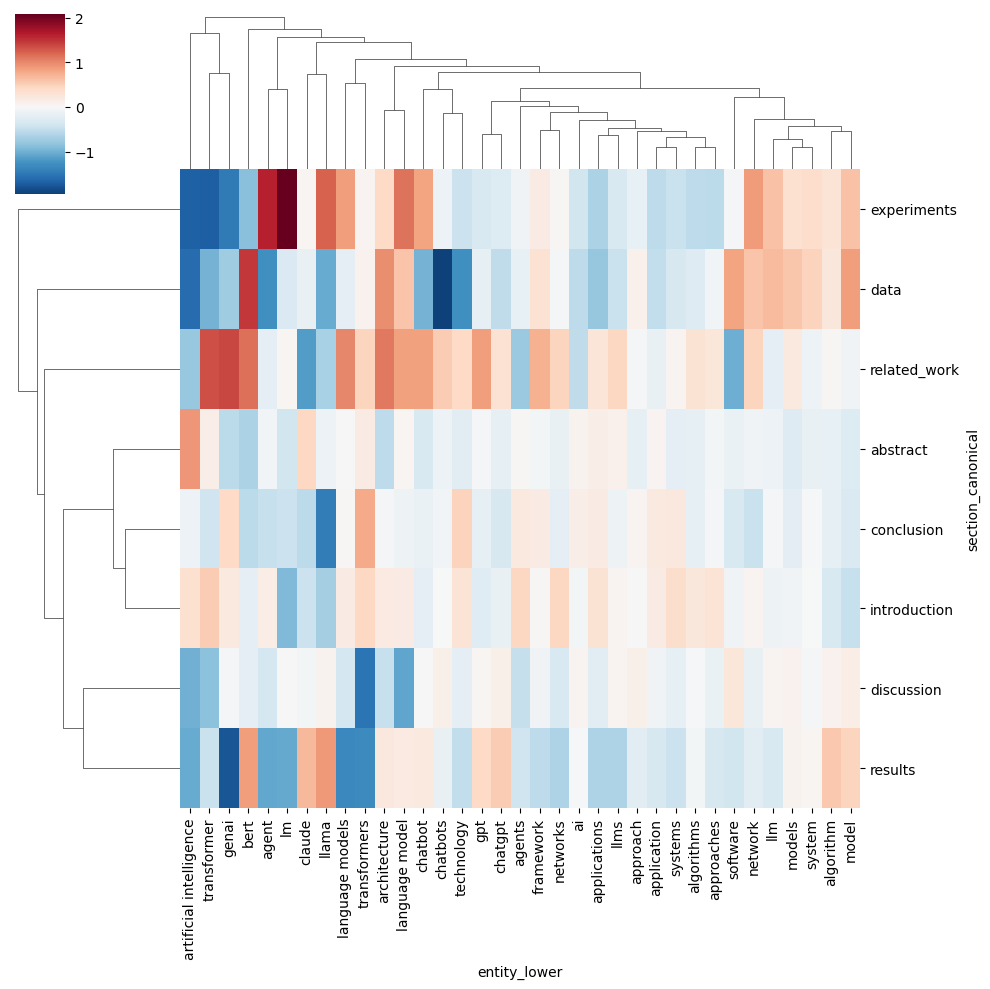

In [77]:
for domain in domain_order:
    print(domain)
    sns.clustermap(standardize(pd.crosstab(paired_nohum[paired_nohum["domain"] == domain]["section_canonical"], paired_nohum[paired_nohum["domain"] == domain]["entity_lower"])).dropna(axis=1),
                   cmap="RdBu_r", xticklabels=1, center=0)
    plt.show()

## Inspect proportions of humanlike predictions

In [91]:
dedup_subset = df_dedup[(df_dedup["entity_type_updated"] != "human") & (df_dedup["section_canonical"].isin(keep_sections))].copy()

In [ ]:
import matplotlib.colors as mcolors

In [76]:
def plot_humanlike_props(df):

    # Step 1: per id-section-entity mean
    grouped = df.groupby(['paper_id', 'section_canonical', 'entity_lower'], observed=True)['humanlike'].mean().reset_index()
    grouped = grouped.rename(columns={'humanlike': 'humanlike_mean', 'paper_id': 'id', 'entity_lower': 'entity', 'section_canonical': 'section'})
    
    # Step 2: section x entity summary — mean proportion AND count of ids behind it
    summary = grouped.groupby(['section', 'entity'], observed=True)['humanlike_mean'].agg(['mean', 'count']).reset_index()
    
    # Step 3: pivot both into matrices
    pivot_mean = summary.pivot(index='entity', columns='section', values='mean')
    pivot_mean = pivot_mean.loc[pivot_mean.mean(axis=1).sort_values(ascending=False).index]
    pivot_count = summary.pivot(index='entity', columns='section', values='count').fillna(0).loc[pivot_mean.index]

    display(pivot_mean.mean().sort_values())
    
    # Step 4: plot side by side
    fig, axes = plt.subplots(1, 2, figsize=(20, 12), gridspec_kw={'wspace': 0.05})
    
    # --- Left: mean proportion, with NaNs shown as distinct grey ---
    ax0 = axes[0]
    ax0.set_facecolor('grey')  # cells masked out (NaN) will show this background
    sns.heatmap(
        pivot_mean,
        cmap="RdBu_r",        # diverging colormap makes 0.5 visually distinct from extremes
        vmin=0, vmax=1,
        square=True,
        center=0.5,
        linewidths=0.3,
        linecolor='white',
        cbar_kws={'label': 'Mean proportion of condition=True', 'shrink': 0.6},
        mask=pivot_mean.isna(),   # explicitly mask NaNs so they fall through to facecolor
        ax=ax0
    )
    ax0.set_title('Mean condition proportion (grey = no data)')
    
    # --- Right: counts, to sanity-check reliability of each cell ---
    # --- Right panel: counts, two-tier coloring ---
    ax1 = axes[1]
    
    min_count = 10
    
    below_mask = pivot_count >= min_count   # mask OUT (hide) cells >= threshold in this layer
    above_mask = pivot_count < min_count    # mask OUT (hide) cells < threshold in this layer
    
    # Layer 1: cells below threshold, flat warning color
    sns.heatmap(
        pivot_count,
        mask=below_mask,
        square=True,
        cmap=mcolors.ListedColormap(['#e74c3c']),  # solid red/orange for "unreliable"
        cbar=False,
        linewidths=0.3, linecolor='white',
        annot=True, fmt='.0f', annot_kws={'size': 6, 'color': 'white'},
        ax=ax1
    )
    
    # Layer 2: cells at/above threshold, Blues scaled only among themselves
    sns.heatmap(
        pivot_count,
        mask=above_mask,
        square=True,
        cmap='Blues',
        vmin=min_count, vmax=pivot_count.max().max(),
        linewidths=0.3, linecolor='white',
        cbar_kws={'label': f'Count ({min_count} shown in blue scale)', 'shrink': 0.6},
        annot=True, fmt='.0f', annot_kws={'size': 6},
        ax=ax1
    )
    
    ax1.set_title(f'Count of ids per section/entity (red = below {min_count})')

    #plt.tight_layout()
    plt.show()

section
conclusion      0.194624
related_work    0.215172
introduction    0.223826
abstract        0.225513
approach        0.240431
discussion      0.259776
data            0.264750
results         0.283790
experiments     0.290715
dtype: float64

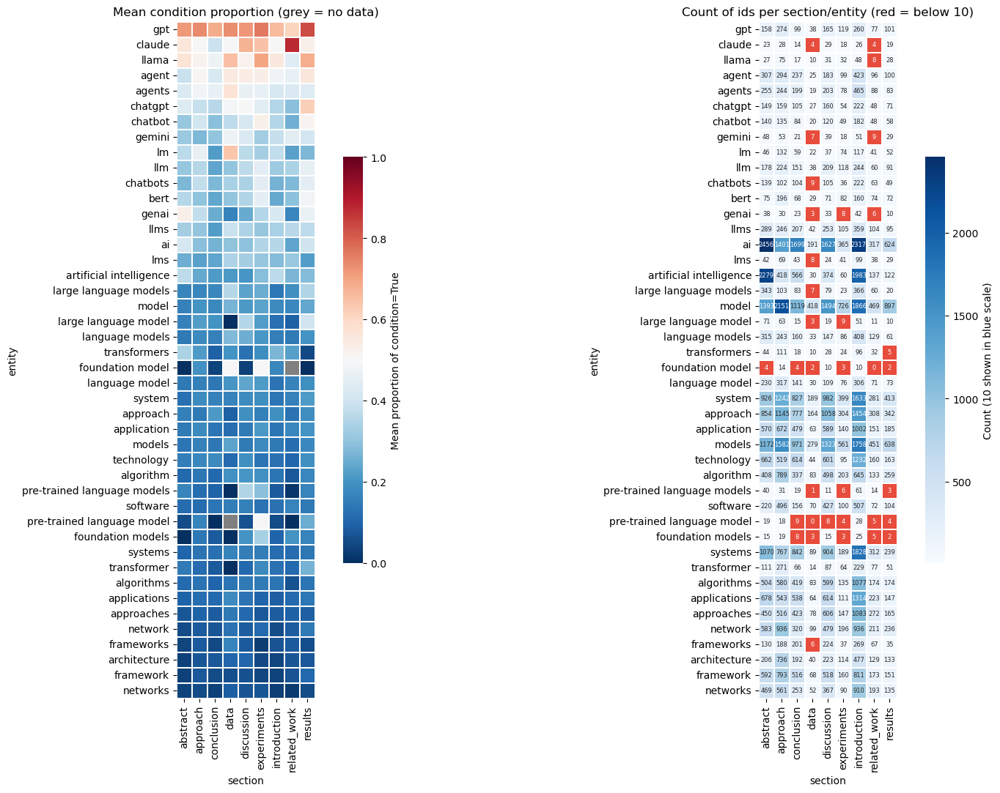

In [77]:
plot_humanlike_props(dedup_subset)

PHYSICAL SCIENCES


section
conclusion      0.176936
abstract        0.200890
related_work    0.202920
introduction    0.213633
approach        0.224328
discussion      0.239177
data            0.261036
results         0.274738
experiments     0.278255
dtype: float64

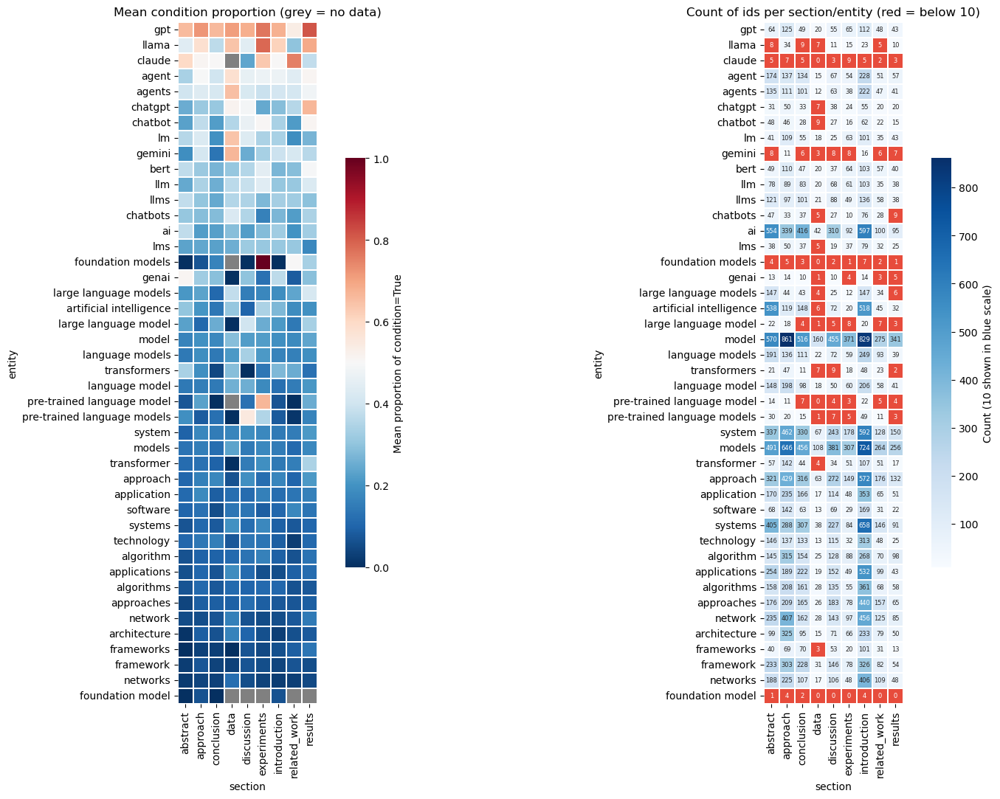

LIFE SCIENCES


section
introduction    0.190432
related_work    0.195752
conclusion      0.217379
discussion      0.219713
approach        0.229317
abstract        0.251260
results         0.251615
data            0.279268
experiments     0.301338
dtype: float64

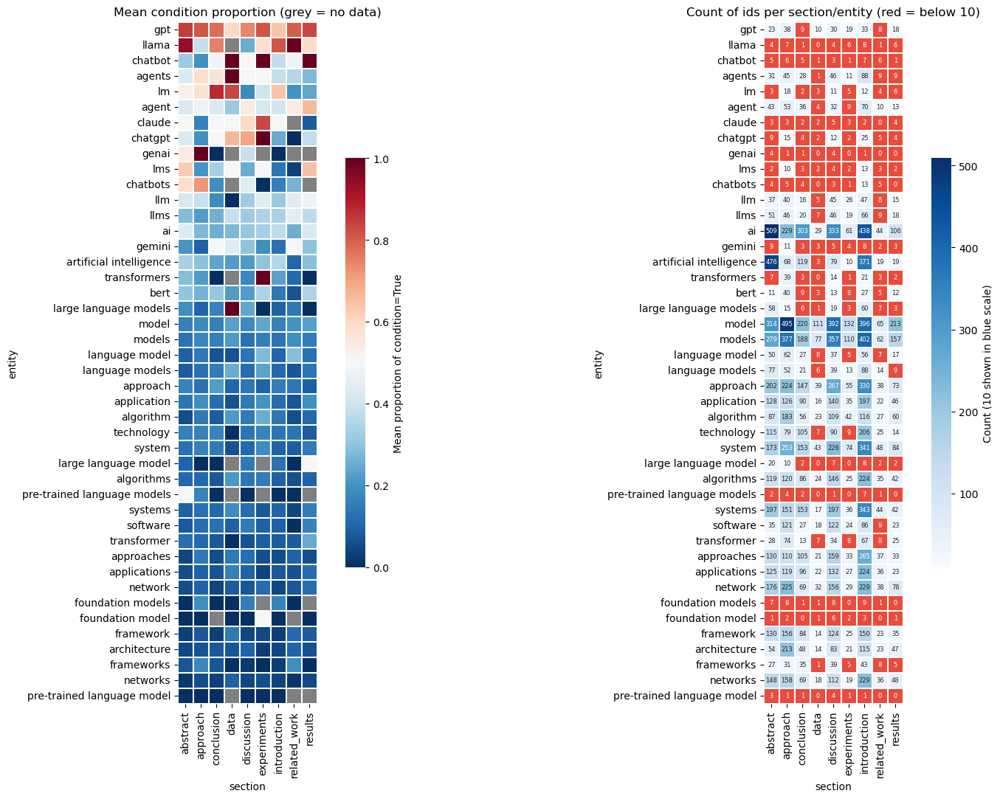

SOCIAL SCIENCES


section
conclusion      0.191843
abstract        0.207953
introduction    0.234541
data            0.239374
related_work    0.242122
approach        0.259800
experiments     0.273450
discussion      0.274015
results         0.293765
dtype: float64

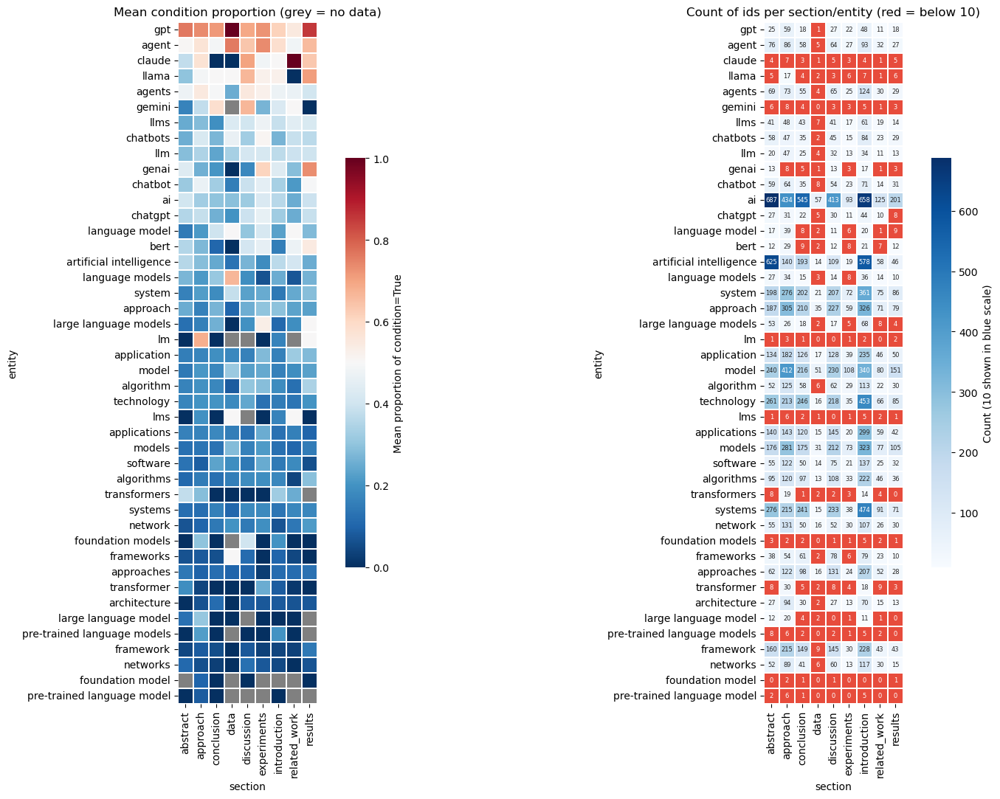

HEALTH SCIENCES


section
conclusion      0.235016
approach        0.254908
related_work    0.256769
introduction    0.258370
abstract        0.277703
data            0.302122
discussion      0.308557
experiments     0.328686
results         0.350851
dtype: float64

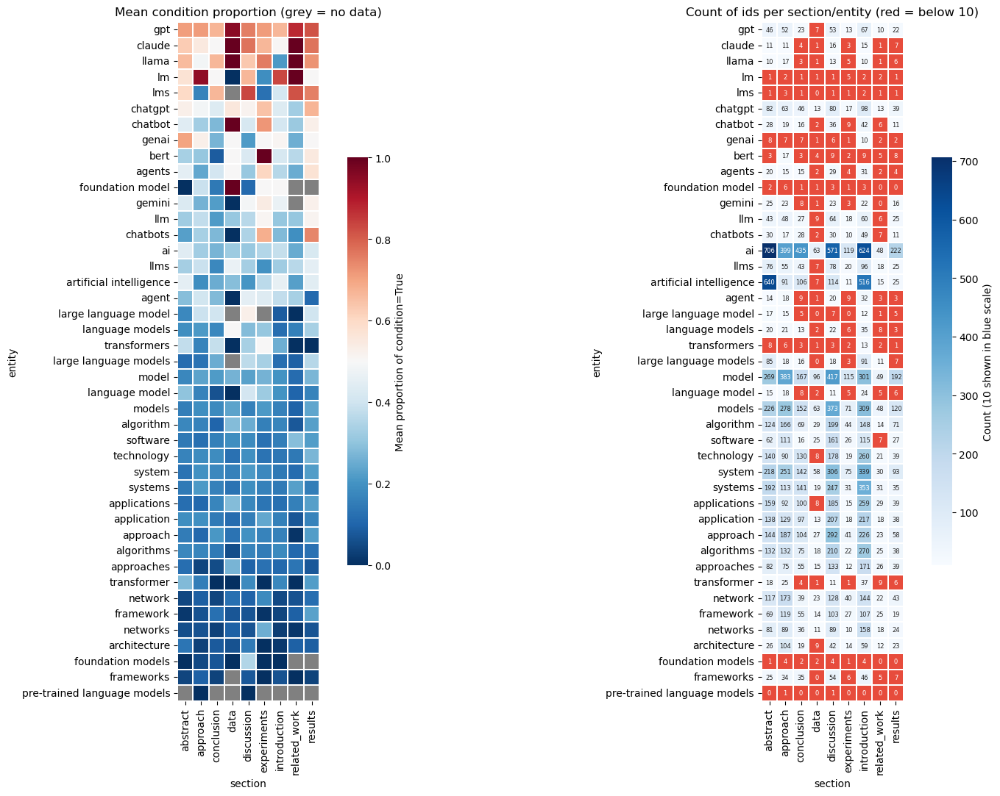

In [78]:
for domain in domain_order:
    print(domain.upper())
    plot_humanlike_props(dedup_subset[dedup_subset["domain"] == domain])

In [79]:
def plot_humanlike_props_et(df):

    # Step 1: per id-section-entity mean
    grouped = df.groupby(['paper_id', 'section_canonical', 'entity_type_updated'], observed=True)['humanlike'].mean().reset_index()
    grouped = grouped.rename(columns={'humanlike': 'humanlike_mean', 'paper_id': 'id', 'entity_type_updated': 'entity', 'section_canonical': 'section'})
    
    # Step 2: section x entity summary — mean proportion AND count of ids behind it
    summary = grouped.groupby(['section', 'entity'], observed=True)['humanlike_mean'].agg(['mean', 'count']).reset_index()
    
    # Step 3: pivot both into matrices
    pivot_mean = summary.pivot(index='entity', columns='section', values='mean')
    pivot_mean = pivot_mean.loc[pivot_mean.mean(axis=1).sort_values(ascending=False).index]
    pivot_count = summary.pivot(index='entity', columns='section', values='count').fillna(0).loc[pivot_mean.index]

    display(pivot_mean.mean().sort_values())
    
    # Step 4: plot side by side
    fig, axes = plt.subplots(1, 2, figsize=(20, 12), gridspec_kw={'wspace': 0.05})
    
    # --- Left: mean proportion, with NaNs shown as distinct grey ---
    ax0 = axes[0]
    ax0.set_facecolor('grey')  # cells masked out (NaN) will show this background
    sns.heatmap(
        pivot_mean,
        cmap="RdBu_r",        # diverging colormap makes 0.5 visually distinct from extremes
        vmin=0, vmax=1,
        square=True,
        center=0.5,
        linewidths=0.3,
        linecolor='white',
        cbar_kws={'label': 'Mean proportion of condition=True', 'shrink': 0.6},
        mask=pivot_mean.isna(),   # explicitly mask NaNs so they fall through to facecolor
        ax=ax0
    )
    ax0.set_title('Mean condition proportion (grey = no data)')
    
    # --- Right: counts, to sanity-check reliability of each cell ---
    # --- Right panel: counts, two-tier coloring ---
    ax1 = axes[1]
    
    min_count = 10
    
    below_mask = pivot_count >= min_count   # mask OUT (hide) cells >= threshold in this layer
    above_mask = pivot_count < min_count    # mask OUT (hide) cells < threshold in this layer
    
    # Layer 1: cells below threshold, flat warning color
    sns.heatmap(
        pivot_count,
        mask=below_mask,
        square=True,
        cmap=mcolors.ListedColormap(['#e74c3c']),  # solid red/orange for "unreliable"
        cbar=False,
        linewidths=0.3, linecolor='white',
        annot=True, fmt='.0f', annot_kws={'size': 6, 'color': 'white'},
        ax=ax1
    )
    
    # Layer 2: cells at/above threshold, Blues scaled only among themselves
    sns.heatmap(
        pivot_count,
        mask=above_mask,
        square=True,
        cmap='Blues',
        vmin=min_count, vmax=pivot_count.max().max(),
        linewidths=0.3, linecolor='white',
        cbar_kws={'label': f'Count ({min_count} shown in blue scale)', 'shrink': 0.6},
        annot=True, fmt='.0f', annot_kws={'size': 6},
        ax=ax1
    )
    
    ax1.set_title(f'Count of ids per section/entity (red = below {min_count})')

    #plt.tight_layout()
    plt.show()

section
related_work    0.238482
conclusion      0.259134
introduction    0.273989
abstract        0.291565
approach        0.301536
discussion      0.356446
experiments     0.362224
data            0.368936
results         0.411516
dtype: float64

/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


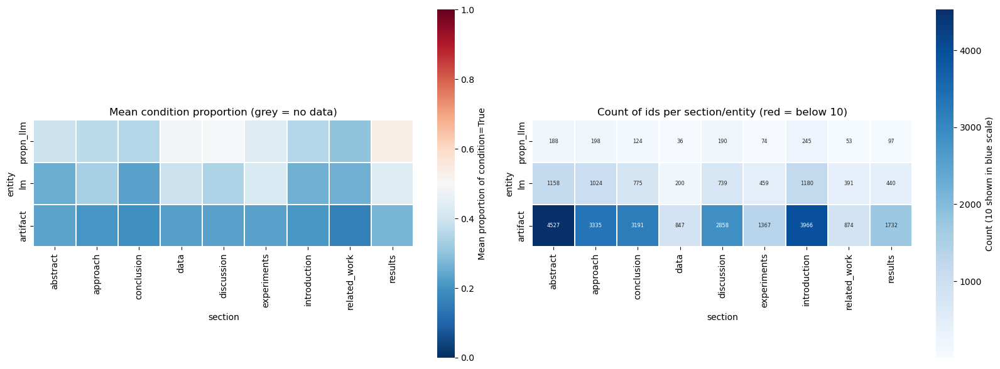

In [80]:
plot_humanlike_props_et(dedup_subset)

PHYSICAL SCIENCES


section
abstract        0.220689
conclusion      0.229950
related_work    0.242442
introduction    0.249239
approach        0.275505
experiments     0.297356
discussion      0.342202
results         0.388174
data            0.407145
dtype: float64

/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


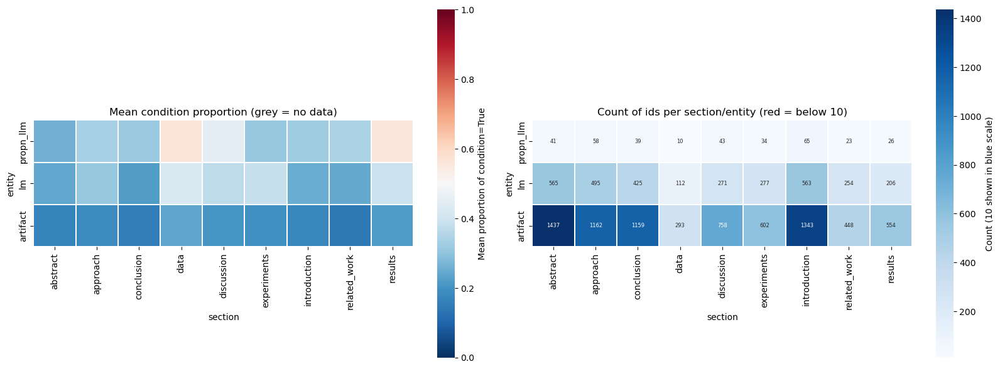

LIFE SCIENCES


section
related_work    0.160189
approach        0.201274
introduction    0.205379
abstract        0.253449
results         0.280447
conclusion      0.294088
data            0.337663
discussion      0.342517
experiments     0.416997
dtype: float64

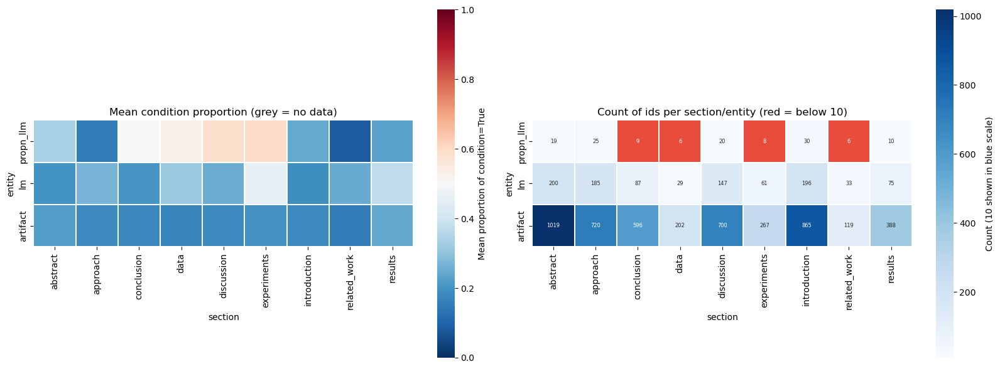

SOCIAL SCIENCES


section
data            0.234682
conclusion      0.249771
related_work    0.253759
introduction    0.280198
abstract        0.283008
approach        0.346902
discussion      0.346920
results         0.402910
experiments     0.403906
dtype: float64

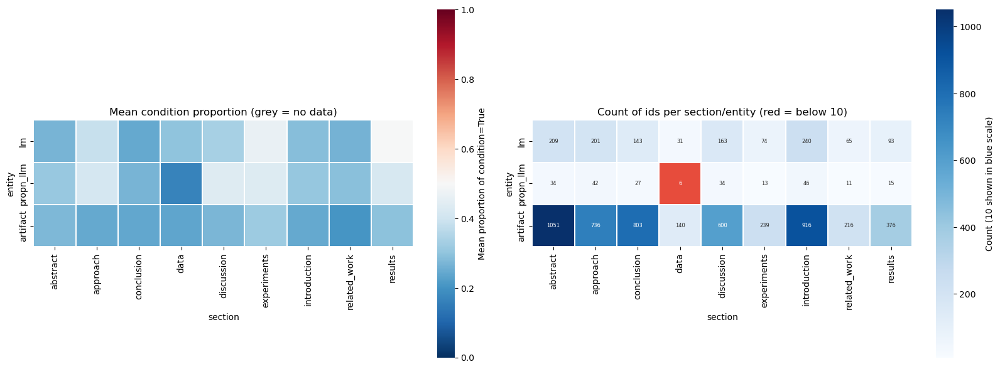

HEALTH SCIENCES


section
related_work    0.272709
conclusion      0.295609
introduction    0.333197
approach        0.363631
abstract        0.369855
discussion      0.393187
data            0.425497
experiments     0.453743
results         0.503764
dtype: float64

/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/ROIHU_TYKKY_0W8ewzV/miniforge/envs/env1/lib/python3.12/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


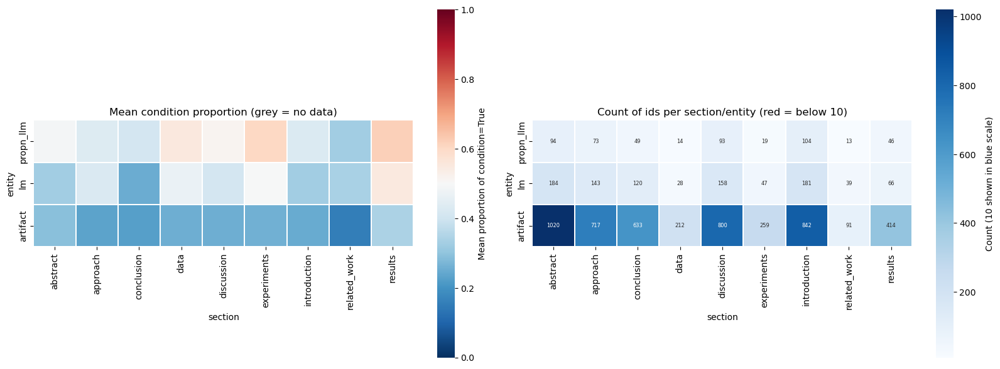

In [81]:
for domain in domain_order:
    print(domain.upper())
    plot_humanlike_props_et(dedup_subset[dedup_subset["domain"] == domain])

In [90]:
dedup_subset.groupby(["domain", "section_canonical", "entity_lower"], observed=True).size().sort_values()[lambda x: x < 5].reset_index("entity_lower")["entity_lower"].unique().tolist()

['pre-trained language model',
 'lm',
 'transformer',
 'foundation models',
 'claude',
 'transformers',
 'foundation model',
 'genai',
 'chatbot',
 'chatbots',
 'large language model',
 'large language models',
 'pre-trained language models',
 'lms',
 'llama',
 'frameworks',
 'agent',
 'agents',
 'gemini',
 'language model',
 'bert',
 'gpt',
 'architecture',
 'language models',
 'chatgpt']

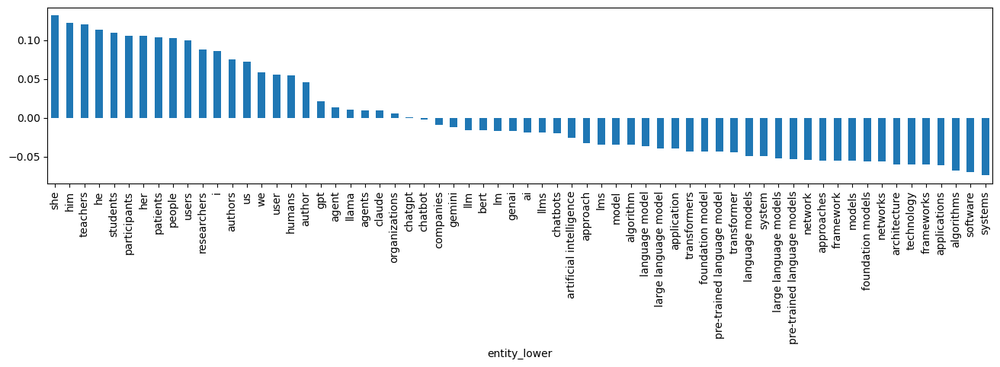

In [106]:
fig, ax = plt.subplots(figsize=(16, 3))
df_dedup.groupby("entity_lower", observed=True)["score"].median().sort_values(ascending=False).plot.bar(ax=ax)
plt.show()

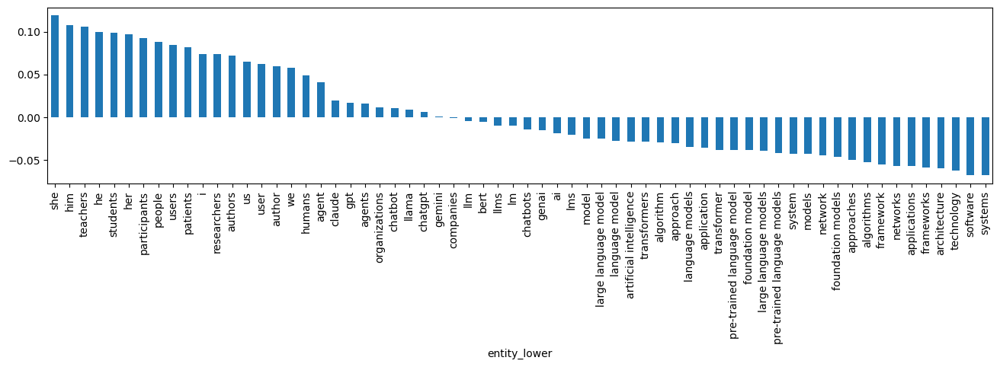

In [107]:
fig, ax = plt.subplots(figsize=(16, 3))
df_dedup.groupby("entity_lower", observed=True)["score"].mean().sort_values(ascending=False).plot.bar(ax=ax)
plt.show()

In [108]:
median_index = dedup_subset.groupby("entity_lower", observed=True)["score"].median().sort_values(ascending=False).index

In [110]:
dedup_subset.groupby(["domain", "entity_lower"], observed=True)["score"].median().unstack("domain").reindex(median_index).style.background_gradient()

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
gpt,0.022649,0.022866,0.019191,0.020698
llama,0.013579,0.000282,0.009944,0.010130
claude,0.012617,0.007097,0.000875,0.003041
agent,-0.006625,0.008335,-0.000004,0.022966
agents,-0.016435,0.007407,-0.007683,0.019860
chatgpt,0.007842,-0.014133,-0.008424,-0.012152
chatbot,-0.004048,-0.013582,-0.019585,-0.006128
gemini,-0.001223,-0.020166,-0.011976,-0.024920
bert,-0.003884,-0.022279,-0.014446,-0.018329


In [114]:
dedup_subset.groupby(["domain", "entity_lower"], observed=True)["humanlike"].mean().unstack("domain").reindex(median_index).style.background_gradient(cmap="RdBu_r")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
gpt,0.772326,0.810376,0.741918,0.758772
llama,0.626316,0.525000,0.597270,0.575758
claude,0.621053,0.562500,0.507692,0.515625
agent,0.459350,0.545738,0.499773,0.631992
agents,0.392739,0.528590,0.475080,0.584019
chatgpt,0.566524,0.397260,0.449677,0.393443
chatbot,0.479730,0.433824,0.382456,0.461337
gemini,0.492857,0.257732,0.350254,0.240000
bert,0.469136,0.331818,0.404915,0.344907


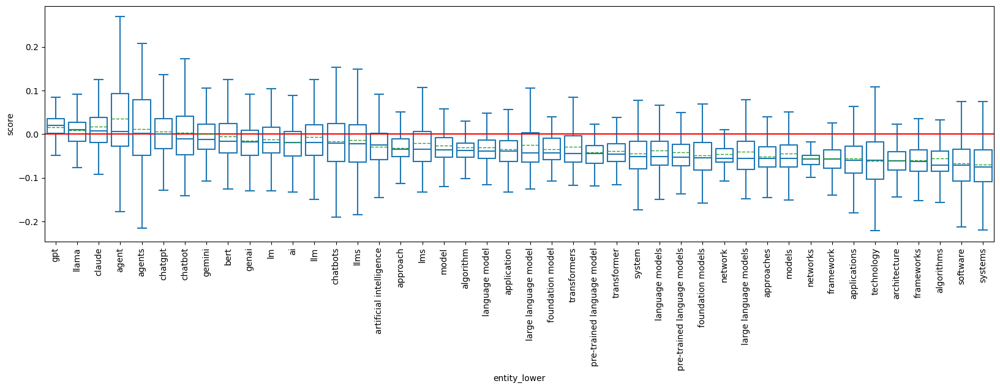

In [125]:
fig, ax = plt.subplots(figsize=(20, 5))
sns.boxplot(dedup_subset, y="score", x="entity_lower", showmeans=True, meanline=True, fill=False, showfliers=False, ax=ax, order=median_index)
ax.axhline(0, color="red")
plt.xticks(rotation=90)
plt.show()

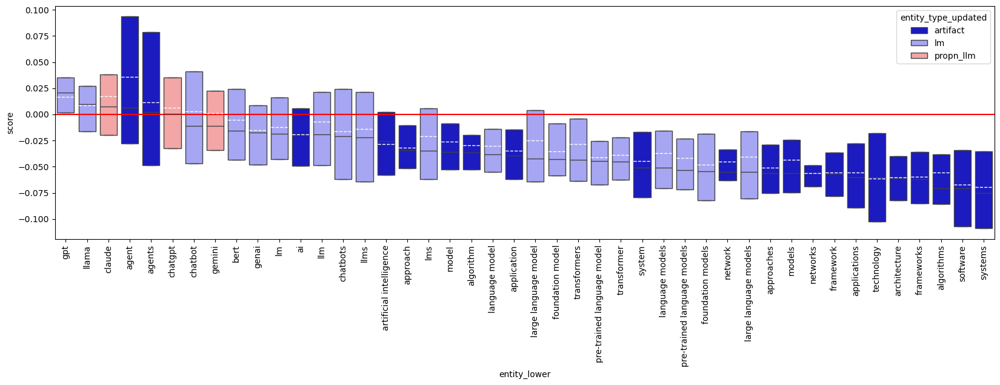

In [135]:
fig, ax = plt.subplots(figsize=(20, 5))
sns.boxplot(dedup_subset, y="score", x="entity_lower",
            whis=(25, 75), showmeans=True, meanline=True, meanprops={"color": "white"}, showfliers=False,
            ax=ax, order=median_index, hue="entity_type_updated", dodge=False, palette=et_palette[:-1])
ax.axhline(0, color="red")
plt.xticks(rotation=90)
plt.show()

### Claude vs GPT?

In [93]:
claude_gpt = dedup_subset[dedup_subset["entity_lower"].isin(("claude", "gpt"))].copy()
claude_gpt["entity_lower"] = claude_gpt["entity_lower"].cat.remove_unused_categories()

In [96]:
print("Proportion of humanlike predictions for Claude:", claude_gpt[claude_gpt["entity_lower"] == "claude"]["humanlike"].mean())
print("Mean score for Claude:", claude_gpt[claude_gpt["entity_lower"] == "claude"]["score"].mean())
print("Proportion of humanlike predictions for GPT:", claude_gpt[claude_gpt["entity_lower"] == "gpt"]["humanlike"].mean())
print("Mean score for GPT:", claude_gpt[claude_gpt["entity_lower"] == "gpt"]["score"].mean())

Proportion of humanlike predictions for Claude: 0.5648148148148148
Mean score for Claude: 0.01738168644369312
Proportion of humanlike predictions for GPT: 0.7613882863340564
Mean score for GPT: 0.01659429285235499


<Axes: xlabel='entity_lower', ylabel='score'>

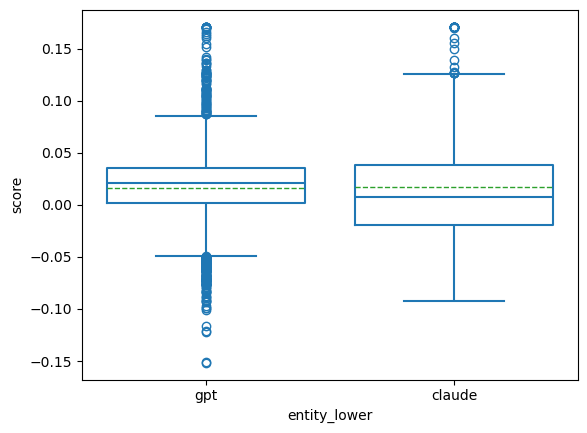

In [117]:
sns.boxplot(claude_gpt, y="score", x="entity_lower", showmeans=True, meanline=True, fill=False)

## Entity-level inspection

In [57]:
df[df["entity_type"] == "artifact"]["entity_lower"].unique().tolist()

['artificial intelligence',
 'ai',
 'systems',
 'frameworks',
 'technology',
 'approach',
 'network',
 'algorithms',
 'software',
 'models',
 'agent',
 'model',
 'applications',
 'algorithm',
 'framework',
 'application',
 'networks',
 'approaches',
 'system',
 'architecture',
 'agents']

<Axes: xlabel='entity_lower'>

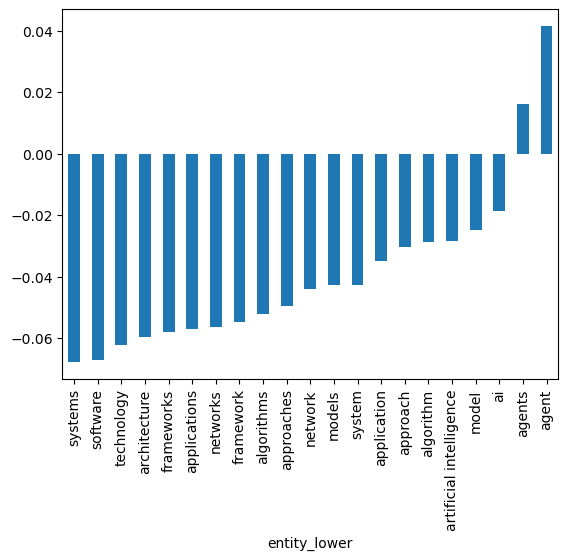

In [63]:
df[df["entity_type"] == "artifact"].groupby("entity_lower", observed=True)["score"].mean().sort_values().plot.bar()

<Axes: xlabel='entity_lower'>

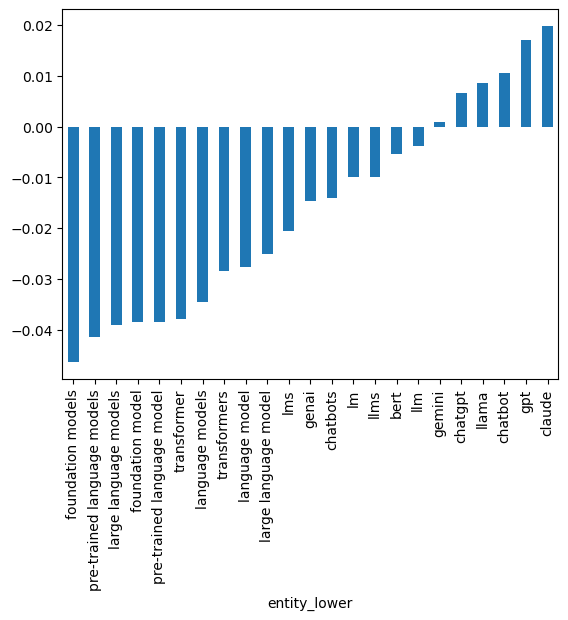

In [64]:
df[df["entity_type"] == "lm"].groupby("entity_lower", observed=True)["score"].mean().sort_values().plot.bar()

In [81]:
mask = df[df["entity_lower"].isin(("agent", "agents"))]["chunk_text"].str.contains("conversational", case=False, na=False)
conversational_index = mask[mask].index

In [82]:
df.loc[conversational_index]["chunk_text"].value_counts().sum()

1033

In [83]:
df.loc[conversational_index]["chunk_text"].value_counts()

chunk_text
conversational agents                            294
the conversational agent                          99
a conversational agent                            74
Conversational agents                             39
pedagogical conversational agents                 30
                                                ... 
speechenabled conversational agents                1
a conversational agent-based search interface      1
artificial intelligence conversational agents      1
i.e., conversational agents                        1
CVH/conversational agent/chatbot                   1
Name: count, Length: 312, dtype: int64

In [84]:
# Change the agent mentions that include "conversational" into LM entity type
df.loc[conversational_index, "entity_type"] = "lm"

<Axes: xlabel='entity_lower'>

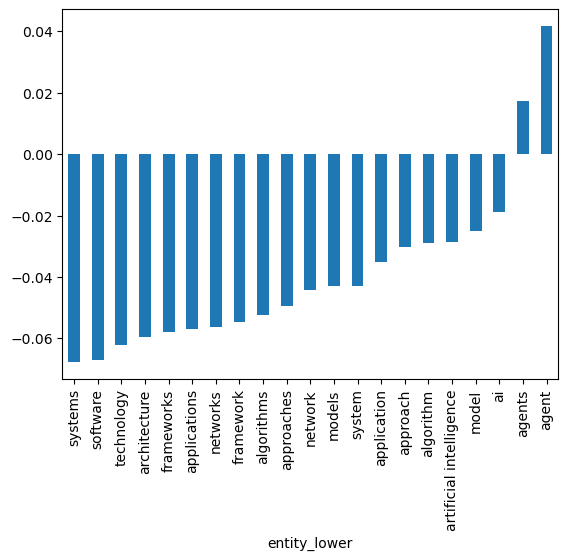

In [86]:
df[df["entity_type"] == "artifact"].groupby("entity_lower", observed=True)["score"].mean().sort_values().plot.bar()

In [96]:
df[df["entity_lower"] == "agent"].groupby("chunk_text", observed=True).agg(
    score=("score", "mean"),
    count=("chunk_text", "size")
).sort_values(["score"], ascending=False).head(30)

,score,count
chunk_text,,
another agent's disregard,0.281443,1
an agent's preference,0.275423,1
an agent's own moral goals,0.262055,1
one-person-one-agent scenarios,0.258032,1
an agent's choices,0.256301,1
an agent's decisions,0.254191,1
an intelligent agent's behavior,0.253022,1
that particular agent's actions,0.248887,1
an agent's own body,0.243550,1


In [87]:
for sent in df[(df["entity_type"] == "artifact") & (df["entity_lower"] == "agent")].sort_values("score", ascending=False).head(10)["sentence"]:
    print(sent)

In moving towards that direction, in this paper, a brain inspired model of self-awareness is presented that allows an agent to learn to attend to different aspects of self as an individual with identity, physical embodiment, mental states, experiences, and reflections on how others may think about oneself.
Another reading of vulnerability defines it as an individual's specific experience of another agent's disregard for their fundamental claims to selfhood.
They are certain to encounter situations that they have not seen before and choosing how much to trust another agent based on past experiences is futile.
The ICH adopts and extends Levin's concept of the ognitive light onethe scale at which an agent's goals, memories, and self-model operate:
Segregation (a global phenomenon) could occur even if an agent's preference was just to live in a community where one is not in a minority.
On the far right (D) are human beings (and perhaps others to be discovered) whose behavior can be radical

In [89]:
for sent in df[(df["entity_type"] == "lm") & (df["entity_lower"] == "agent")].sort_values("score", ascending=False).head(10)["masked_sentence_minimal"]:
    print(sent)

The possible interaction configurations for these scenarios would be (1) one conversational agent representing the tutor and two human learners, or (2) one conversational agent representing the tutor, another conversational [MASK] in the role of a co-learner and one human learner.
The possible interaction configurations for these scenarios would be (1) one conversational agent representing the tutor and two human learners, or (2) one conversational [MASK] representing the tutor, another conversational agent in the role of a co-learner and one human learner.
The possible interaction configurations for these scenarios would be (1) one conversational [MASK] representing the tutor and two human learners, or (2) one conversational agent representing the tutor, another conversational agent in the role of a co-learner and one human learner.
In addition, we designed the conversational agent as an autonomy-supporting (eg, patients were able to control, and set up a date and time of the digital 

<Axes: xlabel='entity_lower'>

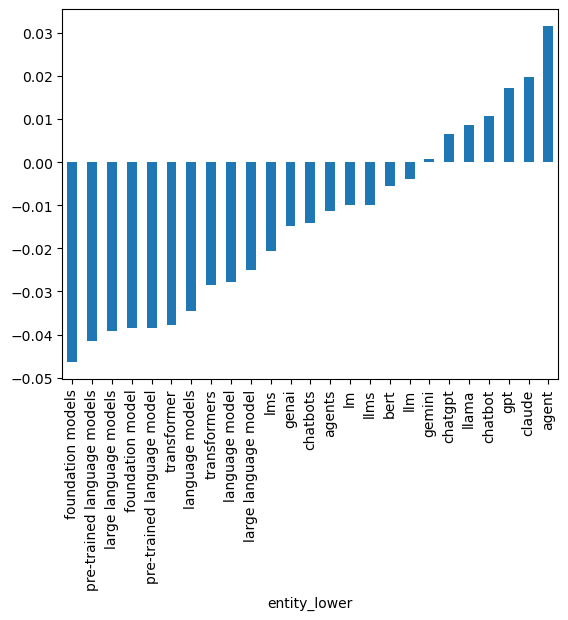

In [85]:
df[df["entity_type"] == "lm"].groupby("entity_lower", observed=True)["score"].mean().sort_values().plot.bar()

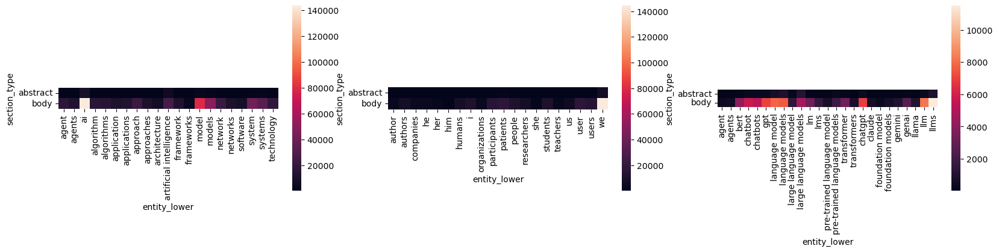

In [118]:
fig, axes = plt.subplots(1, df.entity_type.nunique(), figsize=(20, 4))
axes = axes.flatten()

for i, et in enumerate(df.entity_type.unique()):
    subset = df[df["entity_type"] == et]
    sns.heatmap(pd.crosstab(subset["section_type"], subset["entity_lower"]), ax=axes[i], square=True)

plt.show()

In [105]:
df_dedup["section_type"].value_counts(normalize=True)

section_type
body        0.949263
abstract    0.050737
Name: proportion, dtype: float64

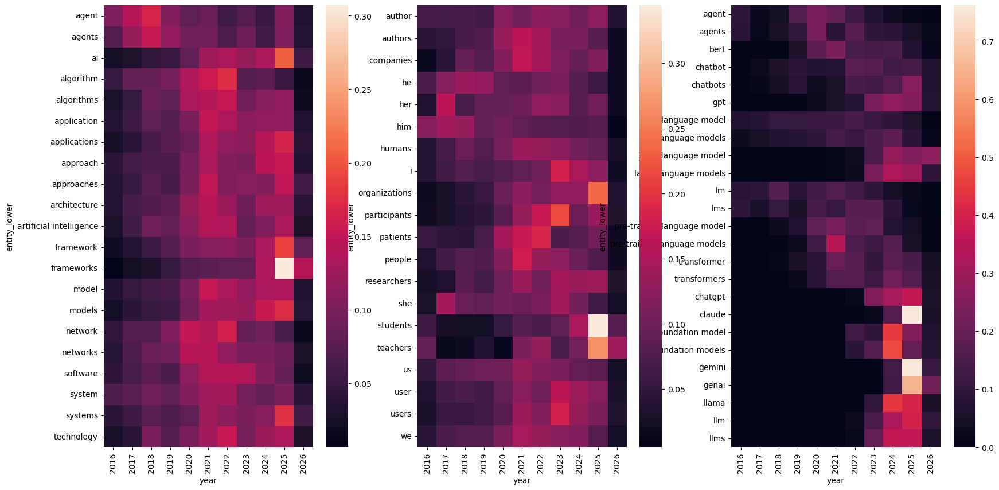

In [144]:
fig, axes = plt.subplots(1, df.entity_type.nunique(), figsize=(20, 10))
axes = axes.flatten()

for i, et in enumerate(df.entity_type.unique()):
    subset = df[df["entity_type"] == et]
    sns.heatmap(pd.crosstab(subset["entity_lower"], subset["year"], normalize="index"), ax=axes[i], yticklabels=1)

plt.show()

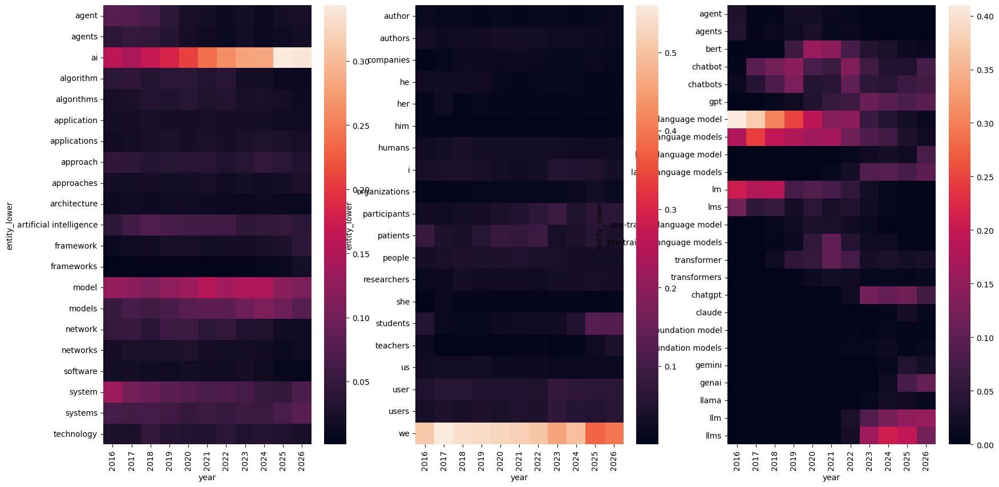

In [143]:
fig, axes = plt.subplots(1, df.entity_type.nunique(), figsize=(20, 10))
axes = axes.flatten()

for i, et in enumerate(df.entity_type.unique()):
    subset = df[df["entity_type"] == et]
    sns.heatmap(pd.crosstab(subset["entity_lower"], subset["year"], normalize="columns"), ax=axes[i], yticklabels=1)

plt.show()

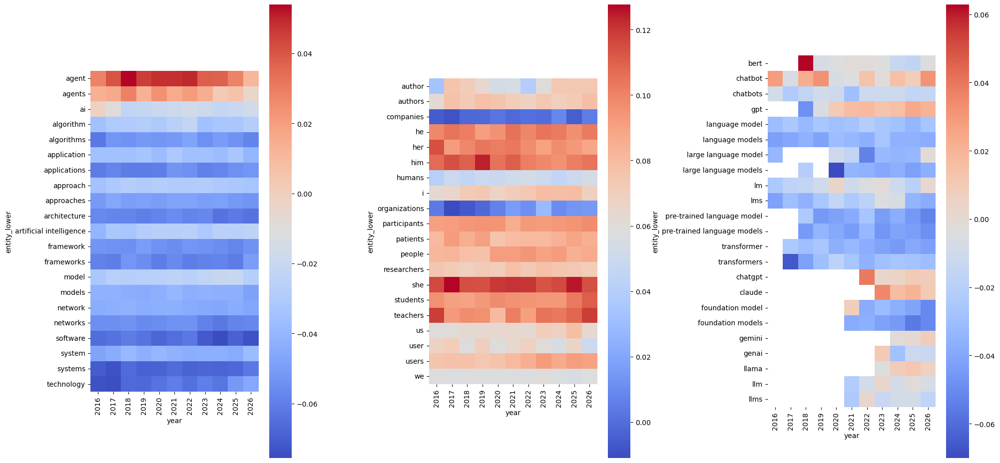

In [121]:
fig, axes = plt.subplots(1, df.entity_type.nunique(), figsize=(20, 10))
axes = axes.flatten()

for i, et in enumerate(df.entity_type.unique()):
    subset = df_dedup[df_dedup["entity_type"] == et]
    map_data = subset.groupby(["year", "entity_lower"], observed=True)["score"].mean().unstack("year")
    sns.heatmap(map_data, ax=axes[i], yticklabels=1, cmap="coolwarm", square=True)

plt.tight_layout()
plt.show()

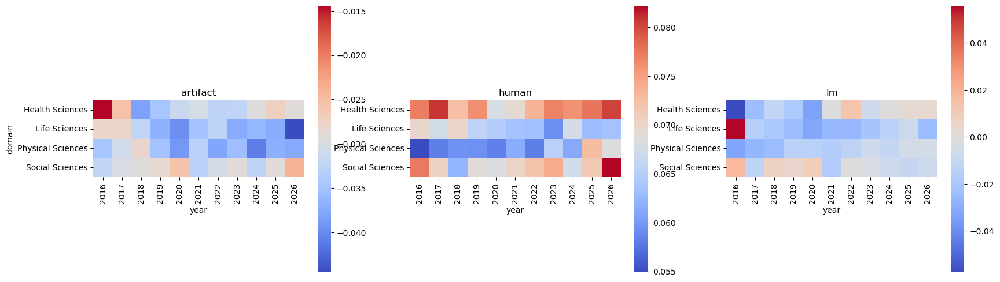

In [119]:
fig, axes = plt.subplots(1, df.entity_type.nunique(), figsize=(20, 6))
axes = axes.flatten()

for i, et in enumerate(df.entity_type.unique()):
    axes[i].set_title(et)
    subset = df_dedup[df_dedup["entity_type"] == et]
    map_data = subset.groupby(["year", "domain"], observed=True)["score"].mean().unstack("year")
    sns.heatmap(map_data, ax=axes[i], yticklabels=1, cmap="coolwarm", square=True)

plt.show()

In [126]:
def standardize(table):
    row_totals = table.sum(axis=1)
    col_totals = table.sum(axis=0)
    grand_total = table.sum().sum()
    
    E = np.outer(row_totals, col_totals) / grand_total
    E = pd.DataFrame(E, index=table.index, columns=table.columns)
    
    lift = table / E
    log_lift = np.log(lift.mask(lift == 0, np.nan))
    return log_lift

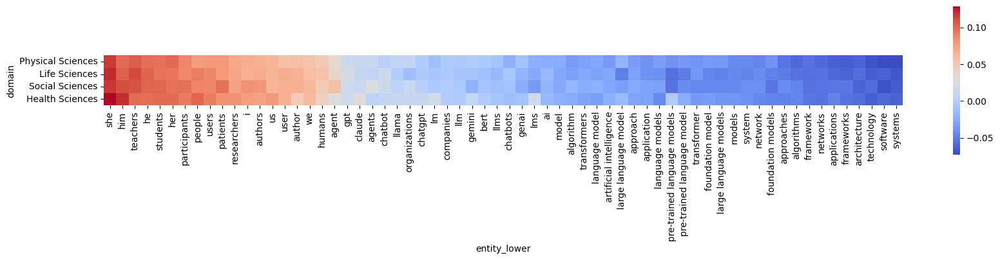

In [144]:
avg_scores_ent = df_dedup.groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
avg_scores_ent_sorted_index = avg_scores_ent.mean().sort_values(ascending=False).index

plt.figure(figsize=(20, 3))
sns.heatmap(avg_scores_ent[avg_scores_ent_sorted_index].loc[domain_order], square=True, cmap="coolwarm", yticklabels=1)
plt.show()

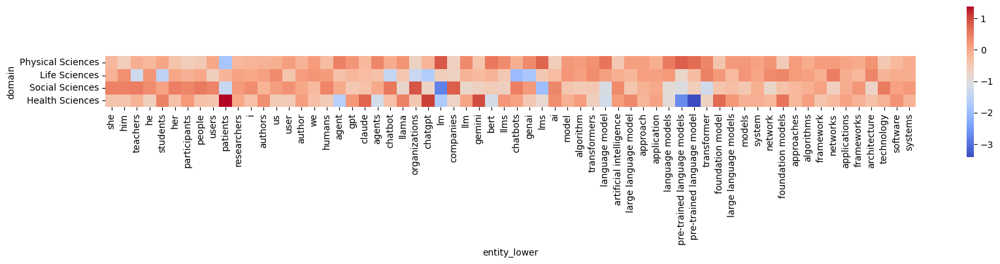

In [145]:
counts_ent = pd.crosstab(df_dedup["domain"], df_dedup["entity_lower"])
plt.figure(figsize=(20, 3))
sns.heatmap(standardize(counts_ent[avg_scores_ent_sorted_index].loc[domain_order]), square=True, cmap="coolwarm", yticklabels=1)
plt.show()

In [132]:
no_human = df_dedup[df_dedup["entity_type"] != "human"]

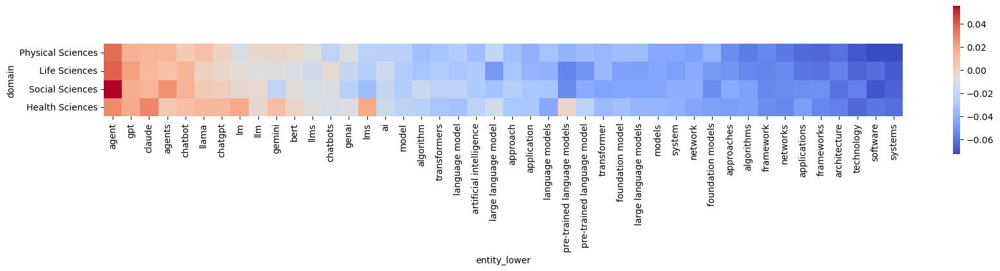

In [146]:
avg_scores_ent = no_human.groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
avg_scores_ent_sorted_index = avg_scores_ent.mean().sort_values(ascending=False).index

plt.figure(figsize=(20, 3))
sns.heatmap(avg_scores_ent[avg_scores_ent_sorted_index].loc[domain_order], square=True, cmap="coolwarm", yticklabels=1)
plt.show()

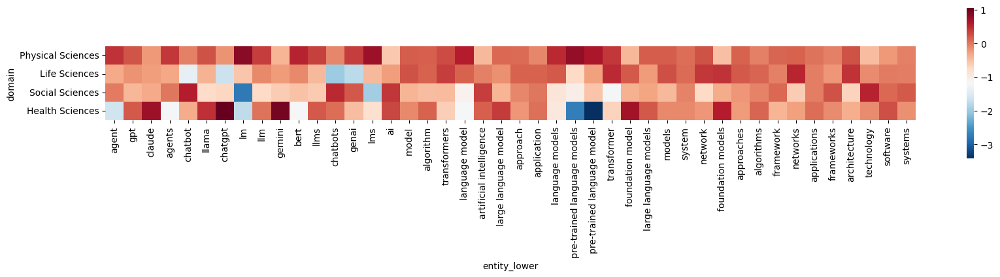

In [147]:
counts_ent = pd.crosstab(no_human["domain"], no_human["entity_lower"])
plt.figure(figsize=(20, 3))
sns.heatmap(standardize(counts_ent[avg_scores_ent_sorted_index].loc[domain_order]), square=True, cmap="RdBu_r", yticklabels=1)
plt.show()

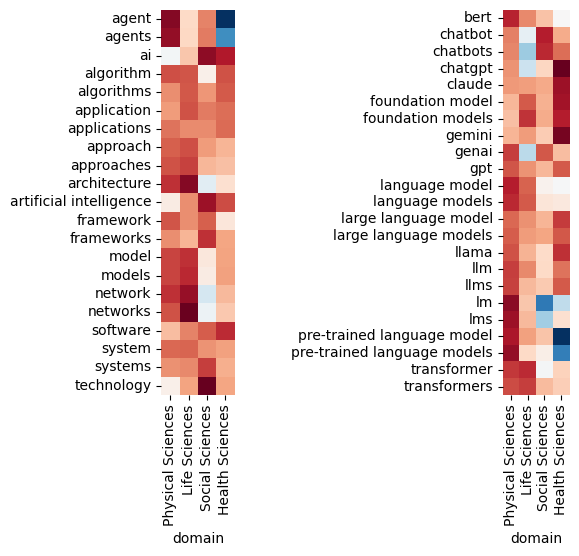

In [149]:
terms_standardized = standardize(pd.crosstab(no_human["domain"], no_human["entity_lower"]))
fig, axes = plt.subplots(1, 2, figsize=(8,5))
for i, et in enumerate(("artifact", "lm")):
    entities = sorted(no_human[no_human["entity_type"] == et]["entity_lower"].unique().tolist())
    subset = terms_standardized.loc[domain_order][entities]
    sns.heatmap(subset.loc[domain_order].T, yticklabels=1, square=True, cmap="RdBu_r", ax=axes[i], cbar=False)
    axes[i].set_ylabel("")
plt.show()